# Reproduction code — "Climate mode interactions shape El Niño-driven tropical ocean and atmospheric warming"

**Po-Cheng Chen, Fei-Fei Jin, Sen Zhao** (University of Hawaiʻi at Mānoa)

This notebook reproduces **all ten main-text figures** of the accompanying manuscript from upstream inputs to final rendered panels. The figure outputs stored in this notebook were produced by a complete run and correspond one-to-one to Figs. 1–10 of the submitted manuscript; the 88 CMIP5/CMIP6 models used in the hybrid-operator experiments are listed in Supplementary Data 1.

**Design.** The observed-replay engine and the CMIP hybrid-operator engine are load-or-compute: if no cache files are present, everything is recomputed from the upstream inputs listed below. Recomputed results are written to separate `*_repro` files so that original caches are never overwritten.

**Upstream input boundary** (these files are the inputs; everything below them is recomputed):

| file | role | provenance |
|---|---|---|
| `XRO_indices_oras5_extended_2025.nc` | 10-mode state vector, historical operator fit | 1979–2024 bit-identical to the official senclimate/XRO repository indices; the 2025 segment was computed by the authors from ORAS5 monthly fields using the same index definitions and processing pipeline as Zhao et al. (2024). |
| `ERA5_SST_global_1deg_1940-2025.nc` | SST reconstruction target + β coefficient maps | ERA5 monthly means (Copernicus CDS) |
| `ERA5_T_plevs_1deg_30S30N_1979-2025.nc` | LTT target (1000/925/850 hPa, pressure-weighted) | ERA5 monthly means (Copernicus CDS) |
| `pocheng_tropical_mean_SST_XRO/*_fit.nc`, `*_timeseries.nc` | per-model CMIP XRO operator fits (88 models; Supplementary Data 1) | fitted upstream from CMIP5/CMIP6 historical SST + thetao |
| `realtime_oisst_sst_indices.nc`, `realtime_tao_pmel_wwv.nc` | forecast initial conditions | NOAA OISST v2.1; PMEL/TAO WWV |

**Section map.** 1 Environment · 2 Observed replay engine · 3 LTT reconstruction & Hovmöller inputs · 4–8 Figures 1–5 · 9 CMIP hybrid-operator ensemble · 10–12 Figures 6–9 · 13 Figure 10 (real-time forecast).

**Runtime.** Observed replay ≈ 1 min; the 88-model CMIP recompute is the long pole (≈10–15 min without cache). The XRO package is pinned to senclimate/XRO release v1.0.2 (Zhao et al., 2024; archived at https://doi.org/10.5281/zenodo.10681114). Data layout: all inputs live in `./data` next to this notebook (see README); figures are written to `./figures`; recomputed engine outputs are written to `*_repro` files and never overwrite the reference caches supplied in `data/reference_cache/`.

## 1. Environment setup

Install `cftime` and the `XRO` package, pinned to release **v1.0.2** of the `senclimate/XRO` GitHub repository (Zhao et al., 2024; archived at https://doi.org/10.5281/zenodo.10681114). For a fully pinned local environment use the accompanying `environment.yml` instead of these bootstrap cells (they are provided for Google Colab convenience).

The setup cell below defines the two location variables used throughout:
- `DATA_DIR` (default `./data`, override with `XRO_DATA_DIR`) — all input files listed in the header table.
- `FIG_DIR` (default `./figures`, override with `XRO_FIG_DIR`) — all figure output.

Both engines run with `FORCE_RECOMPUTE = True` (reproduction mode): the supplied reference caches in `data/reference_cache/` are **never read**; everything is recomputed from the upstream inputs and written to `*_repro` files, which can then be diffed against the reference caches.

In [2]:
!pip install cftime

In [3]:
!pip install git+https://github.com/senclimate/XRO.git@v1.0.2

  Cloning https://github.com/senclimate/XRO.git to /private/var/folders/nn/g5y_hr417_7fs2rrnlfw7r380000gn/T/pip-req-build-hhtw0emw
  Running command git clone --filter=blob:none --quiet https://github.com/senclimate/XRO.git /private/var/folders/nn/g5y_hr417_7fs2rrnlfw7r380000gn/T/pip-req-build-hhtw0emw


  Resolved https://github.com/senclimate/XRO.git to commit a7ddf1ad0f877ec5f9f102f8cb67addefe41311a


  Installing build dependencies ... -

 \

 done


  Getting requirements to build wheel ... -

 done


  Preparing metadata (pyproject.toml) ... - done


In [4]:
# ── Data & output locations ─────────────────────────────────────────────
# All input files listed in the header table live in DATA_DIR.
# Default layout (Zenodo reproduction package): ./data next to this notebook.
# Override with the XRO_DATA_DIR / XRO_FIG_DIR environment variables if needed.
import os

if os.path.exists('/content'):                      # Google Colab
    from google.colab import drive
    drive.mount('/content/drive')

DATA_DIR = os.path.abspath(os.environ.get('XRO_DATA_DIR', 'data'))
FIG_DIR   = os.path.abspath(os.environ.get('XRO_FIG_DIR', 'figures'))
CACHE_OUT = os.path.abspath(os.environ.get('XRO_CACHE_DIR', 'outputs_cache'))
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(CACHE_OUT, exist_ok=True)
assert os.path.isdir(DATA_DIR), (
    f"DATA_DIR not found: {DATA_DIR}\n"
    "Place the reproduction package's data/ folder next to this notebook, "
    "or set XRO_DATA_DIR to its location.")
print('DATA_DIR =', DATA_DIR)
print('FIG_DIR  =', FIG_DIR)

## 2. Observed replay engine — operator, residual forcing, decoupling replays

Builds the full observation-based replay engine inline:

- `build_stepper_linear` (sub-step integration, `nstep=10`, output = sub-step mean)
- `delta_from_obs` (best-shift search + residual-forcing diagnosis)
- `patch_C_blocks` (zero or replace L sub-blocks)
- `replay_with_patched_L` (deterministic replay driven by the observed residual forcing)
- Full BASE / C1=0 / C2=0 / C1&C2=0 and per-basin replay loops

**Caching:** if `REPLAY_FILE` exists it is loaded (fast); otherwise everything is computed inline (≈30 s) and cached.

In [5]:
# ============================================================
# CELL A — Setup + COMPLETE OBS-replay engine (v2)
#
# What's new vs v1:
#   v1 just loaded `xro_replays_lindetrend_1979-2025.npz` and crashed if missing.
#   v2 contains the FULL engine inline:
#     - build_stepper_linear (sub-stepping, nstep=10, output = sub-step mean)
#     - delta_from_obs (best_shift search + DELTA diagnosis)
#     - patch_C_blocks (C1/C2/L8/L_ENSO zero or replace)
#     - Full BASE / C1 / C2 / C12 + per-basin replay loops
#   If REPLAY_FILE exists → load (fast).
#   If REPLAY_FILE missing → compute everything inline (slower, ~30s).
#   Result is cached to REPLAY_FILE for next time.
#
# Cite: Zhao et al. (2024) Nature, XRO framework.
# ============================================================
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from XRO import XRO

# ============================================================
# Paths
# ============================================================
# DATA_DIR / FIG_DIR are defined once in the setup cell (Section 1)
IDX_FILE      = os.path.join(DATA_DIR, 'XRO_indices_oras5_extended_2025.nc')
LTT_PLEV_FILE = os.path.join(DATA_DIR, 'ERA5_T_plevs_1deg_30S30N_1979-2025.nc')
SST_GLOB_FILE = os.path.join(DATA_DIR, 'ERA5_SST_global_1deg_1940-2025.nc')
REPLAY_FILE   = os.path.join(DATA_DIR, 'reference_cache', 'xro_replays_lindetrend_1979-2025.npz')
REPLAY_REPRO  = os.path.join(CACHE_OUT, 'xro_replays_lindetrend_1979-2025.repro.npz')
FORCE_RECOMPUTE = True   # reproduction mode: never read the cache

LTT_PLEVS = np.array([1000., 925., 850.])

# ============================================================
# Settings
# ============================================================
STATE10    = ['Nino34','WWV','NPMM','SPMM','IOB','IOD','SIOD','TNA','ATL3','SASD']
ENSO_CORE  = ['Nino34','WWV']
NON_ENSO   = [m for m in STATE10 if m not in ENSO_CORE]
MODES9     = ['Nino34','NPMM','SPMM','IOB','IOD','SIOD','TNA','ATL3','SASD']
MODES9UP   = ['NINO34','NPMM','SPMM','IOB','IOD','SIOD','TNA','ATL3','SASD']
NSTEP      = 10
PERIOD     = slice('1979-01-01', '2025-12-31')
STD_BASE   = PERIOD
EVENT_BASE = PERIOD

BASIN_MODES = {
    'ExPO': ['NPMM', 'SPMM'],
    'IO':   ['IOB',  'IOD',  'SIOD'],
    'AO':   ['TNA',  'ATL3', 'SASD'],
}

# ============================================================
# Engine helper functions (these ARE the engine — keep inline!)
# ============================================================
def ensure_alias(ds):
    if 'NINO34' in ds and 'Nino34' not in ds: ds['Nino34'] = ds['NINO34']
    if 'Nino34' in ds and 'NINO34' not in ds: ds['NINO34'] = ds['Nino34']
    return ds

def _as0360_sorted(da, lon_name='lon'):
    if lon_name in da.coords:
        lon = da[lon_name]
        if float(lon.min()) < 0:
            da = da.assign_coords({lon_name: (lon % 360)})
        da = da.sortby(lon_name)
    return da

def idx_of(names, sel):
    """1-based indices (XRO fit_ds uses 1-based ranky/rankx coords)."""
    up = [n.upper() for n in names]
    return [up.index(s.upper()) + 1 for s in sel]

def build_stepper_linear(Lac, nstep=10):
    """Sub-step integration over a month. Output is sub-step MEAN (not endpoint).
    This is critical — XRO simulate uses the same scheme.
    """
    ncycle = Lac.shape[-1]
    dt = 1.0 / ncycle / nstep
    def step(X, mon_idx):
        X_in = np.array(X, dtype=np.float64, copy=True)
        M = Lac[:, :, mon_idx]
        tmp = np.zeros_like(X_in)
        for _ in range(nstep):
            X_in += (M @ X_in) * dt
            tmp  += X_in / nstep
        return tmp
    return step

def delta_from_obs(stepper, X_obs_np, months0_to_11):
    """Diagnose residual forcing DELTA s.t. X_obs(t+1) = stepper(X_obs(t)) + DELTA(t+1).
    Search 0..11 best_shift that minimises residual RMS (calibrates calendar
    alignment between XRO Lac month-index and obs month-index).
    """
    best = None
    for sh in range(12):
        r, T = X_obs_np.shape
        d = np.zeros((r, T), dtype=float)
        for i in range(T - 1):
            mon = int((months0_to_11[i] + sh) % 12)
            d[:, i + 1] = (X_obs_np[:, i + 1]
                           - stepper(X_obs_np[:, i].reshape(r, 1), mon).squeeze())
        rms = float(np.sqrt(np.nanmean(d[:, 1:] ** 2)))
        if best is None or rms < best[0]:
            best = (rms, sh, d)
    return best

def patch_C_blocks(fit_base, fit_obs_ref, which, subset, mode='zero'):
    """Modify Lac in fit_base by zeroing (or replacing) C1/C2 blocks.
    which : 'C1' (modes→ENSO), 'C2' (ENSO→modes), 'C1&C2' (both).
    subset: list of mode names involved (e.g. ['NPMM','SPMM'] for ExPO basin).
    mode  : 'zero' or 'obs' (replace with fit_obs_ref).
    """
    f = fit_base.copy(deep=True)
    vn = [str(v) for v in f['var_names'].values]
    ENSO = idx_of(vn, ENSO_CORE)
    SUB  = idx_of(vn, subset)
    def set_block(rows, cols):
        for r in rows:
            for c in cols:
                if mode == 'zero':
                    f['Lac'].loc[dict(ranky=r, rankx=c)] = 0.0
                else:
                    f['Lac'].loc[dict(ranky=r, rankx=c)] = fit_obs_ref['Lac'].sel(ranky=r, rankx=c)
    if which == 'C1':      set_block(ENSO, SUB)
    elif which == 'C2':    set_block(SUB, ENSO)
    elif which == 'C1&C2': set_block(ENSO, SUB); set_block(SUB, ENSO)
    else: raise ValueError(which)
    return f

def replay_with_patched_L(fit_patched, X0, DELTA, months0, best_shift, nstep=10):
    """Run a deterministic replay using patched Lac + OBS DELTA."""
    Lac_pat = fit_patched['Lac'].values
    step    = build_stepper_linear(Lac_pat, nstep=nstep)
    YY = np.zeros((X0.shape[0], DELTA.shape[1]), dtype=float)
    YY[:, 0] = X0
    for i in range(YY.shape[1] - 1):
        mon = int((months0[i] + best_shift) % 12)
        YY[:, i + 1] = (step(YY[:, i].reshape(-1, 1), mon)
                        + DELTA[:, i + 1].reshape(-1, 1)).squeeze()
    return YY

def make_Zz(YY_np, tcom_in, mu9_in, sig9_in):
    pos = {n.upper(): i for i, n in enumerate(STATE10)}
    YY9 = np.stack([YY_np[pos[m], :] for m in MODES9UP], axis=0)
    mons = pd.DatetimeIndex(tcom_in).month.values
    Zz = np.zeros_like(YY9, dtype=np.float64)
    for t_i, m in enumerate(mons):
        mu_m  = mu9_in[:, m - 1]
        sig_m = sig9_in[:, m - 1]
        Zz[:, t_i] = (YY9[:, t_i] - mu_m) / np.where(sig_m > 0, sig_m, 1.0)
    return Zz

def reconstruct_2d(Cj_da, Zz, tcom_in):
    Cj_np = Cj_da.values
    mons  = pd.DatetimeIndex(tcom_in).month.values
    T_len = len(tcom_in)
    nlat, nlon = Cj_np.shape[2], Cj_np.shape[3]
    Y = np.zeros((T_len, nlat, nlon), dtype=np.float32)
    for t_i, m in enumerate(mons):
        Y[t_i] = np.einsum('mxy,m->xy', Cj_np[:, m - 1], Zz[:, t_i])
    return xr.DataArray(Y, dims=['time', 'lat', 'lon'],
                        coords={'time': tcom_in, 'lat': Cj_da.lat.values,
                                'lon': Cj_da.lon.values})

def tropmean_15(da):
    lat_vals = da['lat'].values
    if lat_vals[0] > lat_vals[-1]:
        sub = da.sel(lat=slice(15., -15.)).sortby('lat')
    else:
        sub = da.sel(lat=slice(-15., 15.))
    w = xr.DataArray(np.cos(np.deg2rad(sub['lat'].values)), dims=['lat'],
                     coords={'lat': sub['lat'].values})
    return sub.weighted(w).mean(['lat', 'lon'], skipna=True)

def tropmean_30(da):
    lat_vals = da['lat'].values
    if lat_vals[0] > lat_vals[-1]:
        sub = da.sel(lat=slice(30., -30.)).sortby('lat')
    else:
        sub = da.sel(lat=slice(-30., 30.))
    w = xr.DataArray(np.cos(np.deg2rad(sub['lat'].values)), dims=['lat'],
                     coords={'lat': sub['lat'].values})
    return sub.weighted(w).mean(['lat', 'lon'], skipna=True)

def linear_detrend_1d(x):
    n = len(x); t = np.linspace(-1, 1, n)
    A = np.column_stack([t, np.ones(n)]); fin = np.isfinite(x)
    coef = np.linalg.lstsq(A[fin], x[fin], rcond=None)[0]
    return x - A @ coef

def linear_detrend_2d_field(anom_np):
    T = anom_np.shape[0]
    tn = np.linspace(-1, 1, T)
    A  = np.column_stack([tn, np.ones(T)])
    flat  = anom_np.reshape(T, -1).astype(float)
    valid = np.isfinite(flat).all(0)
    coef  = np.full((2, flat.shape[1]), np.nan)
    if valid.any():
        coef[:, valid] = np.linalg.lstsq(A, flat[:, valid], rcond=None)[0]
    return (flat - A @ coef).reshape(anom_np.shape).astype(np.float32)

# ============================================================
# 1. XRO fit + DELTA (linear detrend applied to state indices)
# ============================================================
print('Loading XRO indices and fitting operator (linear detrend) ...')
ds_idx   = ensure_alias(xr.open_dataset(IDX_FILE)).drop_vars('month', errors='ignore')
tcom     = pd.DatetimeIndex(ds_idx.sel(time=PERIOD).time.values).values
X_obs_ds = ds_idx[STATE10].sel(time=tcom)

_X_obs_raw = X_obs_ds.to_array().values                  # (10, T) raw
_X_obs_lin = np.array([linear_detrend_1d(_X_obs_raw[i]) for i in range(10)])

_X_lin_da = xr.DataArray(_X_obs_lin, dims=['ranky', 'time'],
                          coords={'ranky': np.arange(1, 11), 'time': tcom})
xro = XRO(ncycle=12, ac_order=1, is_forward=True)
fit_obs = xro.fit_matrix(_X_lin_da, var_names=STATE10,
                          time=np.arange(len(tcom)) / 12.0)
months0  = pd.DatetimeIndex(tcom).month.values - 1
step_obs = build_stepper_linear(fit_obs['Lac'].values, nstep=NSTEP)
d_rms, best_shift, DELTA = delta_from_obs(step_obs, _X_obs_lin, months0)
print(f'  best_shift={best_shift},  delta_rms={d_rms:.3f}')

# ============================================================
# 2. OBS replays — load if available, else compute inline
# ============================================================
def _compute_obs_replays():
    """Compute YY_base / YY_c1 / YY_c2 / YY_c12 + per-basin variants using engine."""
    print('  Computing OBS replays from scratch (engine inline) ...')
    T = _X_obs_lin.shape[1]
    X0 = _X_obs_lin[:, 0]

    # BASE = identity replay (sanity)
    YY_b = replay_with_patched_L(fit_obs, X0, DELTA, months0, best_shift, NSTEP)

    # ALL-modes C1 / C2 / C12 (subset = NON_ENSO = all 8 non-ENSO modes)
    fit_c1  = patch_C_blocks(fit_obs, fit_obs, 'C1',    NON_ENSO, mode='zero')
    fit_c2  = patch_C_blocks(fit_obs, fit_obs, 'C2',    NON_ENSO, mode='zero')
    fit_c12 = patch_C_blocks(fit_obs, fit_obs, 'C1&C2', NON_ENSO, mode='zero')
    YY_c1_  = replay_with_patched_L(fit_c1,  X0, DELTA, months0, best_shift, NSTEP)
    YY_c2_  = replay_with_patched_L(fit_c2,  X0, DELTA, months0, best_shift, NSTEP)
    YY_c12_ = replay_with_patched_L(fit_c12, X0, DELTA, months0, best_shift, NSTEP)

    # Per-basin variants (subset = each basin's modes)
    basin_out = {}
    for basin, modes in BASIN_MODES.items():
        for which, key_suffix in [('C1', 'c1'), ('C2', 'c2'), ('C1&C2', 'c12')]:
            fit_pat = patch_C_blocks(fit_obs, fit_obs, which, modes, mode='zero')
            basin_out[f'{basin}_{key_suffix}'] = replay_with_patched_L(
                fit_pat, X0, DELTA, months0, best_shift, NSTEP)

    # μ9 / σ9 from MODES9 of YY_base (= linearly-detrended X_obs)
    pos = {n.upper(): i for i, n in enumerate(STATE10)}
    YY9 = np.stack([YY_b[pos[m], :] for m in MODES9UP], axis=0)
    mu9_  = np.full((9, 12), np.nan)
    sig9_ = np.full((9, 12), np.nan)
    for m in range(12):
        sel = (months0 == m)
        mu9_[:, m]  = YY9[:, sel].mean(axis=1)
        sig9_[:, m] = YY9[:, sel].std(axis=1)
    return YY_b, YY_c1_, YY_c2_, YY_c12_, mu9_, sig9_, basin_out

if (not FORCE_RECOMPUTE) and os.path.exists(REPLAY_FILE):
    print(f'Loading pre-computed OBS replays from {os.path.basename(REPLAY_FILE)} ...')
    rep      = np.load(REPLAY_FILE, allow_pickle=False)
    YY_base  = rep['YY_base'];  YY_c1 = rep['YY_c1']
    YY_c2    = rep['YY_c2'];    YY_c12 = rep['YY_c12']
    mu9      = rep['mu9'];      sig9 = rep['sig9']
    YY_basin = {f'{b}_{s}': rep[f'{b}_{s}']
                for b in ['ExPO', 'IO', 'AO'] for s in ['c1', 'c2', 'c12']}
else:
    YY_base, YY_c1, YY_c2, YY_c12, mu9, sig9, YY_basin = _compute_obs_replays()
    # cache for next run
    save_dict = dict(tcom=tcom.astype('datetime64[ns]'), months0=months0,
                      mu9=mu9, sig9=sig9,
                      YY_base=YY_base, YY_c1=YY_c1, YY_c2=YY_c2, YY_c12=YY_c12,
                      **YY_basin)
    np.savez(REPLAY_REPRO, **save_dict)
    print(f'  Saved recomputed replays → {REPLAY_REPRO}')

# ============================================================
# 3. Z-score matrices  (linearly-detrended obs / replays)
# ============================================================
Zz_obs  = make_Zz(_X_obs_lin, tcom, mu9, sig9)
Zz_base = make_Zz(YY_base,    tcom, mu9, sig9)
Zz_c1   = make_Zz(YY_c1,      tcom, mu9, sig9)
Zz_c2   = make_Zz(YY_c2,      tcom, mu9, sig9)
Zz_c12  = make_Zz(YY_c12,     tcom, mu9, sig9)

# ============================================================
# 4. LTT (1000-850 hPa, 30S-30N, linear detrend)
# ============================================================
print('Loading and processing LTT (1000-850 hPa, 30S-30N, linear detrend) ...')

def _pressure_weights(plevs):
    p = np.sort(plevs)[::-1].astype(float)
    dp = np.zeros_like(p)
    dp[0] = (p[0] - p[1]) / 2;  dp[-1] = (p[-2] - p[-1]) / 2
    dp[1:-1] = (p[:-2] - p[2:]) / 2
    return dp / dp.sum()

_pw_ltt = _pressure_weights(LTT_PLEVS)

_ds_pl = xr.open_dataset(LTT_PLEV_FILE)
_ren = {}
if 'valid_time' in _ds_pl.dims: _ren['valid_time'] = 'time'
if 'latitude'   in _ds_pl.dims: _ren['latitude']   = 'lat'
if 'longitude'  in _ds_pl.dims: _ren['longitude']  = 'lon'
if _ren: _ds_pl = _ds_pl.rename(_ren)
_T_pl = _ds_pl['t']

_mask_ltt = np.isin(_T_pl['pressure_level'].values.astype(float), LTT_PLEVS)
_T_ltt    = _T_pl.isel(pressure_level=_mask_ltt)
_si_ltt   = np.argsort(_T_ltt['pressure_level'].values.astype(float))[::-1]
_T_ltt    = _T_ltt.isel(pressure_level=_si_ltt)
_LTT_raw  = (_T_ltt * _pw_ltt[None, :, None, None]).sum('pressure_level')

_tcom_per = pd.DatetimeIndex(tcom).to_period('M').to_timestamp()
_tltt_per = pd.DatetimeIndex(_LTT_raw.time.values).to_period('M').to_timestamp()
_thr_ltt  = _tcom_per.intersection(_tltt_per)
_LTT_raw  = _LTT_raw.sel(time=_thr_ltt.values)
_lat_ltt  = _LTT_raw.lat.values;  _lon_ltt = _LTT_raw.lon.values
_mon_ltt  = pd.DatetimeIndex(_thr_ltt.values).month.values - 1
_tt_mask  = np.array([p in pd.DatetimeIndex(_thr_ltt.values).to_period('M')
                       for p in pd.DatetimeIndex(tcom).to_period('M')])

_clim_ltt = _LTT_raw.groupby('time.month').mean('time')
_anom_ltt = (_LTT_raw.groupby('time.month') - _clim_ltt).values.astype(float)
_ltt_np   = linear_detrend_2d_field(_anom_ltt)
_T_ltt_n, _nlat_ltt, _nlon_ltt = _ltt_np.shape

TT_obs_dt = xr.DataArray(_ltt_np, dims=['time', 'lat', 'lon'],
                          coords={'time': _thr_ltt.values,
                                  'lat': _lat_ltt, 'lon': _lon_ltt})

_ZoT_full = Zz_obs.T
_ZoT_ltt  = _ZoT_full[_tt_mask]
_CjTT     = np.zeros((9, 12, _nlat_ltt, _nlon_ltt), dtype=np.float32)
for _m in range(12):
    _ti = np.where(_mon_ltt == _m)[0]
    _X  = _ZoT_ltt[_ti].astype(float)
    _Y  = _ltt_np[_ti].reshape(len(_ti), -1)
    _v  = np.isfinite(_Y).all(0)
    _c  = np.zeros((9, _Y.shape[1]))
    if _v.any():
        _c[:, _v] = np.linalg.lstsq(_X, _Y[:, _v], rcond=None)[0]
    _CjTT[:, _m] = _c.reshape(9, _nlat_ltt, _nlon_ltt)
Cj_TT = xr.DataArray(_CjTT, dims=['mode', 'month', 'lat', 'lon'],
                      coords={'lat': _lat_ltt, 'lon': _lon_ltt, 'month': np.arange(12)})
print(f'  Cj_TT (LTT 1000-850 hPa) fitted. shape: {_ltt_np.shape}, '
      f'lat={_lat_ltt[0]:.0f}~{_lat_ltt[-1]:.0f}')

# ============================================================
# 4b. 30S-30N SST: load global, clim-removal + LINEAR detrend, fit Cj
# ============================================================
print('Loading and processing 30S-30N SST (linear detrend) ...')
_sg = xr.open_dataset(SST_GLOB_FILE)['sst']
if float(_sg.lat[0]) > float(_sg.lat[-1]):
    _sg = _sg.sortby('lat')
_s30   = _sg.sel(lat=slice(-30, 30), time=PERIOD)
_shr   = (pd.DatetimeIndex(tcom).to_period('M').to_timestamp()
          .intersection(pd.DatetimeIndex(_s30.time.values).to_period('M').to_timestamp()))
_s30   = _s30.sel(time=_shr.values)
_lat30 = _s30.lat.values;  _lon30 = _s30.lon.values
_cl30  = _s30.groupby('time.month').mean('time')
_an30  = (_s30.groupby('time.month') - _cl30).values.astype(float)
_T30, _nlat30, _nlon30 = _an30.shape
_sst30_np = linear_detrend_2d_field(_an30)
_ocean30  = np.isfinite(_sst30_np[0])

SST_obs_dt = xr.DataArray(_sst30_np, dims=['time', 'lat', 'lon'],
                           coords={'time': _shr.values, 'lat': _lat30, 'lon': _lon30})

print('Fitting 30S-30N Cj_SST (linear detrend) ...')
_CjSST = np.zeros((9, 12, _nlat30, _nlon30), dtype=np.float32)
_ZoT   = Zz_obs.T
for _m in range(12):
    _ti = np.where(months0 == _m)[0]
    _X  = _ZoT[_ti].astype(float)
    _Y  = _sst30_np[_ti].reshape(len(_ti), -1)
    _v  = np.isfinite(_Y).all(0)
    _c  = np.zeros((9, _Y.shape[1]))
    if _v.any():
        _c[:, _v] = np.linalg.lstsq(_X, _Y[:, _v], rcond=None)[0]
    _CjSST[:, _m] = _c.reshape(9, _nlat30, _nlon30)

Cj_SST = xr.DataArray(_CjSST, dims=['mode', 'month', 'lat', 'lon'],
                        coords={'lat': _lat30, 'lon': _lon30, 'month': np.arange(12)})
Cj_sst = Cj_SST

# ============================================================
# 5. Tropical-mean 1D series (LTT 30S-30N | SST 30S-30N)
# ============================================================
def apply_sst_mask(da_2d, sst_ref=None):
    vals = da_2d.values.copy()
    vals[:, ~_ocean30] = np.nan
    return xr.DataArray(vals, dims=da_2d.dims, coords=da_2d.coords)

def recon_tt(Zz_in):
    return tropmean_30(reconstruct_2d(Cj_TT, Zz_in, tcom))

def recon_sst(Zz_in):
    return tropmean_30(apply_sst_mask(reconstruct_2d(Cj_SST, Zz_in, tcom)))

print('Computing tropical-mean series ...')
TT_1d_obs   = tropmean_30(TT_obs_dt)
SST_1d_obs  = tropmean_30(SST_obs_dt)
TT_1d_base  = recon_tt(Zz_base)
SST_1d_base = recon_sst(Zz_base)
TT_1d_c1    = recon_tt(Zz_c1)
TT_1d_c2    = recon_tt(Zz_c2)
TT_1d_c12   = recon_tt(Zz_c12)
SST_1d_c1   = recon_sst(Zz_c1)
SST_1d_c2   = recon_sst(Zz_c2)
SST_1d_c12  = recon_sst(Zz_c12)

def _r2(a, b): return float(np.corrcoef(a.values, b.values)[0, 1])
print(f'\n  LTT (1000-850 hPa, 30S-30N) OBS std={float(TT_1d_obs.std()):.4f} K | '
      f'BASE std={float(TT_1d_base.std()):.4f} K | r={_r2(TT_1d_obs,TT_1d_base):.4f}')
print(f'  SST (30S-30N) OBS std={float(SST_1d_obs.std()):.4f} K | '
      f'BASE r={_r2(SST_1d_obs,SST_1d_base):.4f}')
print(f'\nCELL A complete. {tcom[0].astype("datetime64[M]")} to {tcom[-1].astype("datetime64[M]")}, n={len(tcom)}')


Loading XRO indices and fitting operator (linear detrend) ...


/opt/anaconda3/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: invalid value encountered in power
  result_data = func(*input_data)
/opt/anaconda3/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: invalid value encountered in power
  result_data = func(*input_data)
/opt/anaconda3/lib/python3.13/site-packages/XRO/core.py:730: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  res_L = xr.concat([res_L, var_resL], dim='ranky')
/opt/anaconda3/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:818: RuntimeWarning: invalid value encountered in power
  result_data = func(*input_d

  best_shift=1,  delta_rms=0.518
Loading pre-computed OBS replays from xro_replays_lindetrend_1979-2025.npz ...
Loading and processing LTT (1000-850 hPa, 30S-30N, linear detrend) ...


  Cj_TT (LTT 1000-850 hPa) fitted. shape: (564, 61, 360), lat=30~-30
Loading and processing 30S-30N SST (linear detrend) ...


Fitting 30S-30N Cj_SST (linear detrend) ...
Computing tropical-mean series ...



  LTT (1000-850 hPa, 30S-30N) OBS std=0.1957 K | BASE std=0.1626 K | r=0.8306
  SST (30S-30N) OBS std=0.1573 K | BASE r=0.9321

CELL A complete. 1979-01 to 2025-12, n=564


## 3. LTT reconstruction and Hovmöller inputs

Loads the detrended 1°-gridded ERA5 LTT and the LTT β coefficient maps, and defines all helper functions needed by Figures 4 and 5 (coordinate/detrending/interpolation utilities, replay constructors, the composite tool `stack_event_windows`, and the Hovmöller plot helpers).

Runs the three pan-tropical variant replays (C1=0, C2=0, C1&C2=0), reconstructs their LTT fields, and assembles `hov_raw = {"OBS","BASE","C1","C2","C12"}` — a dictionary of `(time, lon)` Hovmöllers in the 15°S–15°N equatorial band on a shared longitude mask.

In [6]:
# ============================================================
# CELL TT -- LTT (1000-850 hPa) Hovmoller infrastructure
# Builds hov_raw {OBS, BASE, C1, C2, C12} used by Figs 4 & 5.
# Depends on CELL A.
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

EVENT_BASE      = slice('1979-01-01', '2025-12-31')
REL_START_MONTH = 1
N_REL_MONTHS    = 24

FIXED_LIMIT_TOP = 1.5
FIXED_LIMIT_DEL = 0.4
FIGSIZE         = (17.4, 9.8)

SHOW_CONTOURS        = True
CONTOUR_FRAC_TOP     = 0.20
CONTOUR_FRAC_DEL     = 0.10
N_CONTOUR_TOP        = 13
N_CONTOUR_DEL        = 11
CONTOUR_COLOR        = 'k'
CONTOUR_LINEWIDTH    = 0.45
CONTOUR_LABELS       = True
CONTOUR_LABEL_FONTSIZE = 6

YTICK_LINE_COLOR = 'gray'
YTICK_LINE_STYLE = '--'
YTICK_LINE_WIDTH = 1.0
YTICK_LINE_ALPHA = 0.50
XGRID_LINE_STYLE = '--'
XGRID_LINE_WIDTH = 0.45
XGRID_LINE_ALPHA = 0.15

need = ['YY_base','YY_c1','YY_c2','YY_c12','tcom','ds_idx','STATE10','fit_obs',
        'DELTA','months0','best_shift','X_obs_ds','patch_C_blocks',
        'build_stepper_linear','TT_obs_dt','Cj_TT','Zz_base','Zz_c1','Zz_c2','Zz_c12',
        'reconstruct_2d','make_Zz','mu9','sig9']
miss = [k for k in need if k not in globals()]
if miss:
    raise RuntimeError(f'Missing from CELL A: {miss}')

# ============================================================
# Helper functions
# ============================================================
def lon360_to_label(x):
    x = int(round(x)) % 360
    if x == 0:   return '0'
    if x == 180: return '180'
    if x < 180:  return f'{x}E'
    return f'{360 - x}W'

def get_lon_ticks_labels_360_sparse():
    ticks = np.array([0, 60, 120, 180, 240, 300])
    return ticks, [lon360_to_label(v) for v in ticks]

def to_month_start(da):
    tt = pd.DatetimeIndex(da.time.values).to_period('M').to_timestamp()
    out = da.assign_coords(time=tt).sortby('time')
    if pd.Index(tt).duplicated().any():
        out = out.groupby('time').mean('time')
    return out

def exact_or_interp_monthly(H, target):
    out = H.reindex(time=target)
    if not np.isfinite(out.values).all():
        out = H.interp(time=target)
    return out

def get_nino34_series(ds):
    n = ds['Nino34'] if 'Nino34' in ds else ds['NINO34']
    return to_month_start(n.sel(time=EVENT_BASE).dropna('time'))

def relmonth_labels(start_month=1, nmonths=24):
    labels = []
    for i in range(nmonths):
        m_abs = start_month + i
        yoff  = (m_abs - 1) // 12
        mon   = (m_abs - 1) % 12 + 1
        mon_str = pd.Timestamp(2001, mon, 1).strftime('%b')
        labels.append(f'{mon_str}(0)' if yoff == 0 else f'{mon_str}(+{yoff})')
    return labels

def build_hov(da_2d):
    lat_vals = da_2d['lat'].values
    if lat_vals[0] > lat_vals[-1]:
        da_2d = da_2d.sortby('lat')
    w = xr.DataArray(np.cos(np.deg2rad(da_2d['lat'].values)), dims=['lat'],
                     coords={'lat': da_2d['lat'].values})
    out = da_2d.weighted(w).mean('lat', skipna=True)
    out = to_month_start(out)
    return out.transpose('time', 'lon')

def apply_shared_lon_mask(hov_dict):
    hov_dict = {k: v.transpose('time', 'lon') for k, v in hov_dict.items()}
    masks = [np.isfinite(H).any('time') for H in hov_dict.values()]
    common = xr.concat(masks, dim='_p').all('_p')
    nkept = int(common.sum())
    if nkept == 0:
        raise RuntimeError('No longitudes survive shared mask.')
    hov_dict = {k: H.isel(lon=common.values) for k, H in hov_dict.items()}
    return hov_dict, len(common), nkept

def add_y_guides(ax, y_positions, xmin, xmax):
    for yp in y_positions:
        ax.hlines(yp, xmin=xmin, xmax=xmax,
                  colors=YTICK_LINE_COLOR, linestyles=YTICK_LINE_STYLE,
                  linewidth=YTICK_LINE_WIDTH, alpha=YTICK_LINE_ALPHA, zorder=3)

def add_contours(ax, lon, y, data2d, vlim, frac, nlev):
    if not SHOW_CONTOURS: return
    lev = np.linspace(-vlim, vlim, nlev)
    lev = lev[np.abs(lev) >= frac * vlim]
    if len(lev) == 0: return
    cs = ax.contour(lon, y, data2d, levels=lev,
                    colors=CONTOUR_COLOR, linewidths=CONTOUR_LINEWIDTH)
    if CONTOUR_LABELS:
        try: ax.clabel(cs, fmt='%.1f', fontsize=CONTOUR_LABEL_FONTSIZE)
        except Exception: pass

def make_target_months(event_year, start_month=1, nmonths=24):
    return pd.date_range(pd.Timestamp(event_year, start_month, 1), periods=nmonths, freq='MS')

def stack_event_windows(H, years, start_month=1, nmonths=24, min_valid_frac=0.98):
    arrs, kept = [], []
    H2 = to_month_start(H)
    full_size = nmonths * H2.sizes['lon']
    for y in years:
        target = make_target_months(y, start_month=start_month, nmonths=nmonths)
        win = exact_or_interp_monthly(H2, target)
        frac = int(np.isfinite(win.values).sum()) / full_size
        if frac < min_valid_frac:
            print(f'  skip {y}: valid_frac={frac:.3f}')
            continue
        rel = xr.DataArray(np.arange(nmonths), dims='time', coords={'time': target})
        win = win.assign_coords(rel_month=rel).swap_dims({'time': 'rel_month'})
        if 'time' in win.coords:
            win = win.reset_coords('time', drop=True)
        arrs.append(win.expand_dims(event=[y]))
        kept.append(y)
    if not arrs:
        raise RuntimeError('No valid event windows found.')
    return xr.concat(arrs, dim='event').assign_coords(event=('event', kept))

def rebuild_2d_from_YY_local(YY, t_idx):
    Zz = make_Zz(YY, t_idx, mu9, sig9)
    return reconstruct_2d(Cj_TT, Zz, t_idx)

# ============================================================
# Build Hovmoller for OBS and all-mode variants
# ============================================================
print('Building LTT (1000-850 hPa) Hovmoller (OBS, BASE, C1, C2, C12) ...')
TT_base_2d_hov = reconstruct_2d(Cj_TT, Zz_base, tcom)
TT_c1_2d       = reconstruct_2d(Cj_TT, Zz_c1,   tcom)
TT_c2_2d       = reconstruct_2d(Cj_TT, Zz_c2,   tcom)
TT_c12_2d      = reconstruct_2d(Cj_TT, Zz_c12,  tcom)

hov_raw = {
    'OBS':  build_hov(TT_obs_dt),
    'BASE': build_hov(TT_base_2d_hov),
    'C1':   build_hov(TT_c1_2d),
    'C2':   build_hov(TT_c2_2d),
    'C12':  build_hov(TT_c12_2d),
}

hov_raw, nlon_orig, nlon_kept = apply_shared_lon_mask(hov_raw)
print(f'  Longitude columns kept: {nlon_kept}/{nlon_orig}')
print('CELL LTT (1000-850 hPa) complete.')


Building LTT (1000-850 hPa) Hovmoller (OBS, BASE, C1, C2, C12) ...


  Longitude columns kept: 360/360
CELL LTT (1000-850 hPa) complete.


## 4. Figure 1 — Tropical-mean LTT and SST with Niño-3.4 shading

**Draft Fig. 1.** Two stacked panels of tropical-mean (30°S–30°N) monthly anomalies for 1979–2025, plotted as a 3-month running mean (black line): (a) lower-tropospheric temperature (LTT; pressure-weighted mean over 1000, 925, and 850 hPa) and (b) sea surface temperature (SST). The background shading is the standardized Niño-3.4 index (red = warm, blue = cool; saturation at ±2.5 σ). Both series are deseasonalized and linearly detrended over the full period.

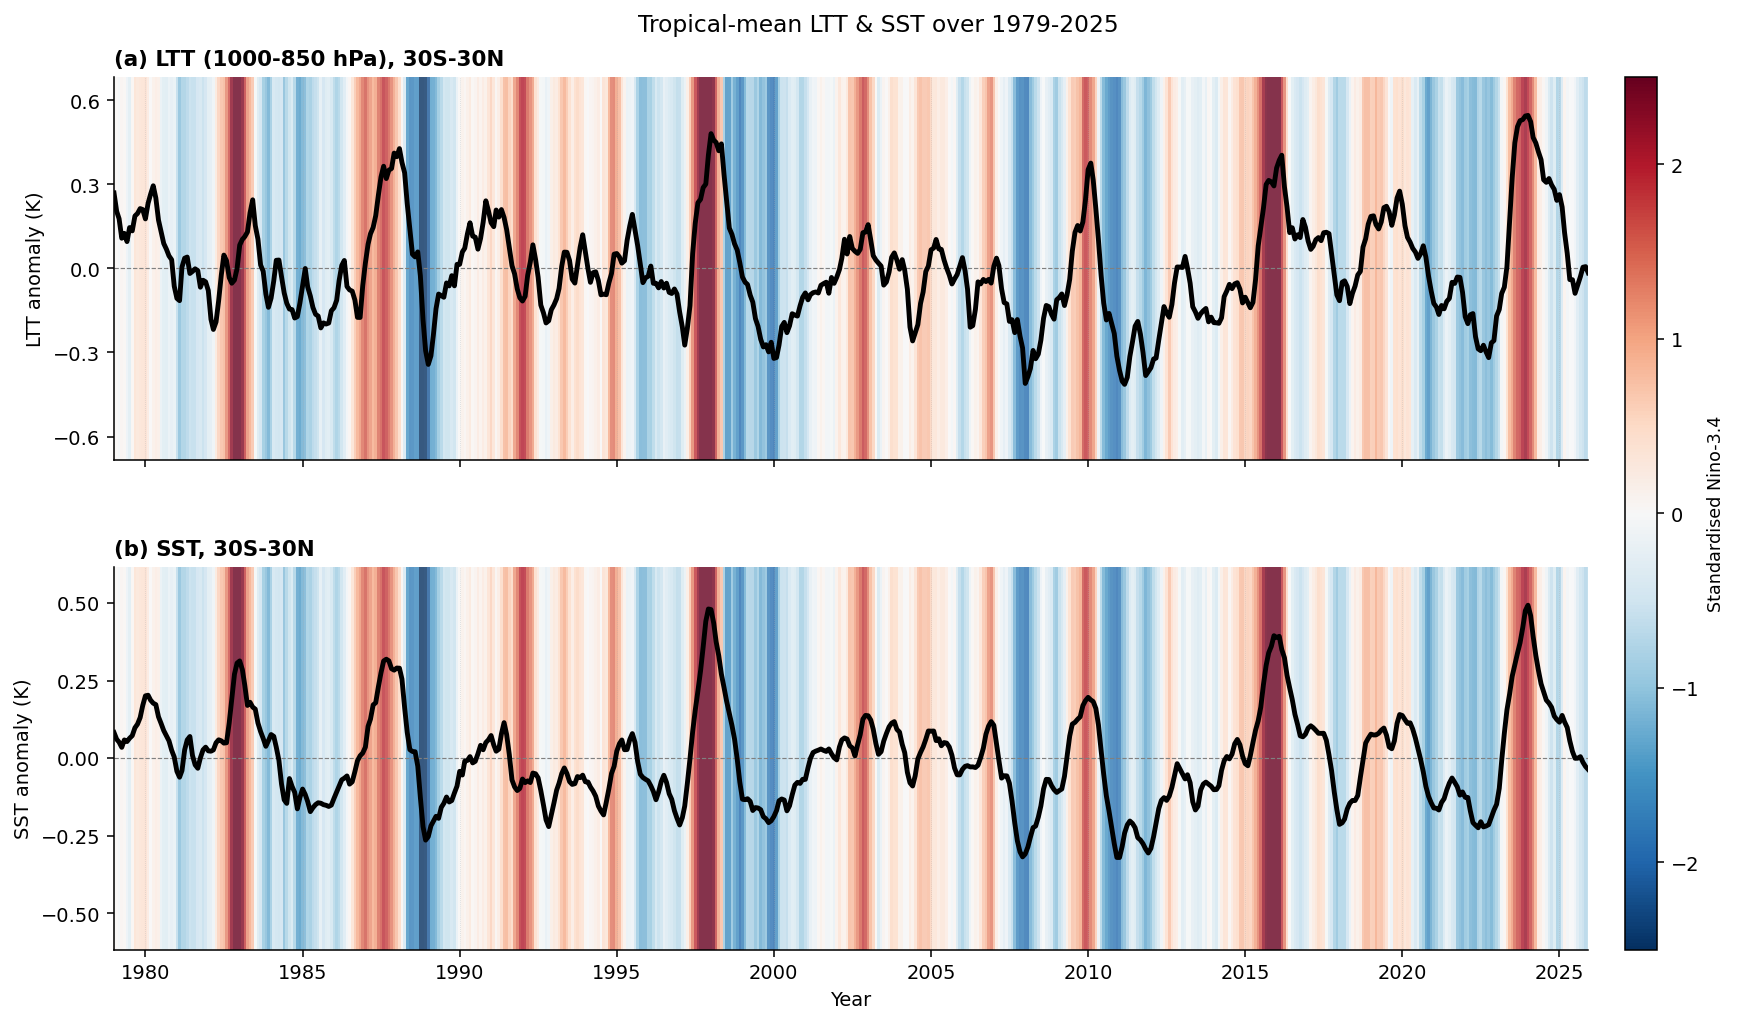

In [7]:
# ============================================================
# FIG 1 -- LTT (1000-850 hPa, 30S-30N) & SST (30S-30N) with Nino-3.4 shading
#   (a) LTT (1000-850 hPa pressure-weighted mean, linear detrend)
#   (b) SST (linear detrend)
#   Background: standardised Nino-3.4 (continuous red-blue colorbar)
#   Line: 3-month running mean, 1979-2025
# Depends: CELL A (TT_1d_obs=LTT_1d_obs, SST_1d_obs, ds_idx, tcom)
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import Normalize

SMOOTH_MONTHS = 3
NINO_VLIM     = 2.5

tt_series  = TT_1d_obs.to_series()
sst_series = SST_1d_obs.to_series()

tt_sm  = tt_series.rolling(window=SMOOTH_MONTHS, center=True,
                            min_periods=max(1, SMOOTH_MONTHS // 2)).mean()
sst_sm = sst_series.rolling(window=SMOOTH_MONTHS, center=True,
                             min_periods=max(1, SMOOTH_MONTHS // 2)).mean()

nino_raw = ds_idx['Nino34'].sel(time=tcom)
nino_std = ((nino_raw - float(nino_raw.mean())) / float(nino_raw.std())).to_series()
nino_std = nino_std.reindex(tt_sm.index, method='nearest')

plt.rcParams.update({'figure.dpi': 140, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

fig, axes = plt.subplots(2, 1, figsize=(13, 7.6), sharex=True)
cmap = mpl.cm.RdBu_r
norm = Normalize(vmin=-NINO_VLIM, vmax=NINO_VLIM)

def _shade_panel(ax, series_sm, obs_label, y_label):
    idx = series_sm.index
    yhi = max(abs(series_sm.dropna().values)) * 1.25
    ylo = -yhi
    X  = idx.values.astype('datetime64[ns]')
    dx = (X[1] - X[0]) / 2
    Xm = np.concatenate([[X[0] - dx], X[:-1] + np.diff(X) / 2, [X[-1] + dx]])
    ax.pcolormesh(Xm, [ylo, yhi], nino_std.values.reshape(1, -1),
                  cmap=cmap, norm=norm, shading='flat', alpha=0.80, zorder=0)
    ax.plot(idx, series_sm.values, color='k', lw=2.5, zorder=3)
    ax.axhline(0, color='0.5', lw=0.6, ls='--', zorder=2)
    ax.set_ylabel(y_label, fontsize=10)
    ax.set_ylim(ylo, yhi)
    ax.set_title(obs_label, loc='left', fontsize=11, fontweight='bold')
    ax.set_xlim(idx[0], idx[-1])
    ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=5, symmetric=True))
    ax.grid(axis='x', ls=':', lw=0.4, alpha=0.5)

_shade_panel(axes[0], tt_sm,  '(a) LTT (1000-850 hPa), 30S-30N', 'LTT anomaly (K)')
_shade_panel(axes[1], sst_sm, '(b) SST, 30S-30N',               'SST anomaly (K)')

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.subplots_adjust(left=0.08, right=0.89, top=0.90, bottom=0.08, hspace=0.28)
cax = fig.add_axes([0.91, 0.08, 0.018, 0.82])
cbar = fig.colorbar(sm, cax=cax, orientation='vertical')
cbar.set_label('Standardised Nino-3.4', fontsize=9)

axes[1].set_xlabel('Year')
axes[0].xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y'))
axes[0].xaxis.set_major_locator(mpl.dates.YearLocator(5))
plt.setp(axes[0].get_xticklabels(), visible=False)
fig.suptitle('Tropical-mean LTT & SST over 1979-2025',
             fontsize=12, y=0.96)
plt.show()


## 5. Figure 2 — BASE vs OBS benchmark for tropical-mean SST

**Draft Fig. 2.** Benchmarking the XRO BASE replay against observations (tropical-mean SST, 30°S–30°N). Four panels:

* (a) monthly anomaly time series (OBS black, BASE blue),
* (b) amplitude = standard deviation of the monthly series,
* (c) seasonal cycle of monthly variance (DJF-centred, Jun–May x-axis),
* (d) lead-lag correlation between Niño-3.4(t−τ) and SST(t), τ ∈ [−18, +18].

Reconstruction uses the **β-regression tropical-mean SST path**: for each calendar month, tropical-mean SST is modelled by ordinary least squares as β(month) · z-scored 9-mode state, with β estimated from the full observed record (1979–2025) and applied identically to OBS and to every replayed state (BASE and all decoupling experiments). The legend reports the correlation r between each reconstruction and OBS over 1979–2025; because β is fitted and evaluated over the same period, r is an in-sample measure of explanatory power, not out-of-sample predictive skill.


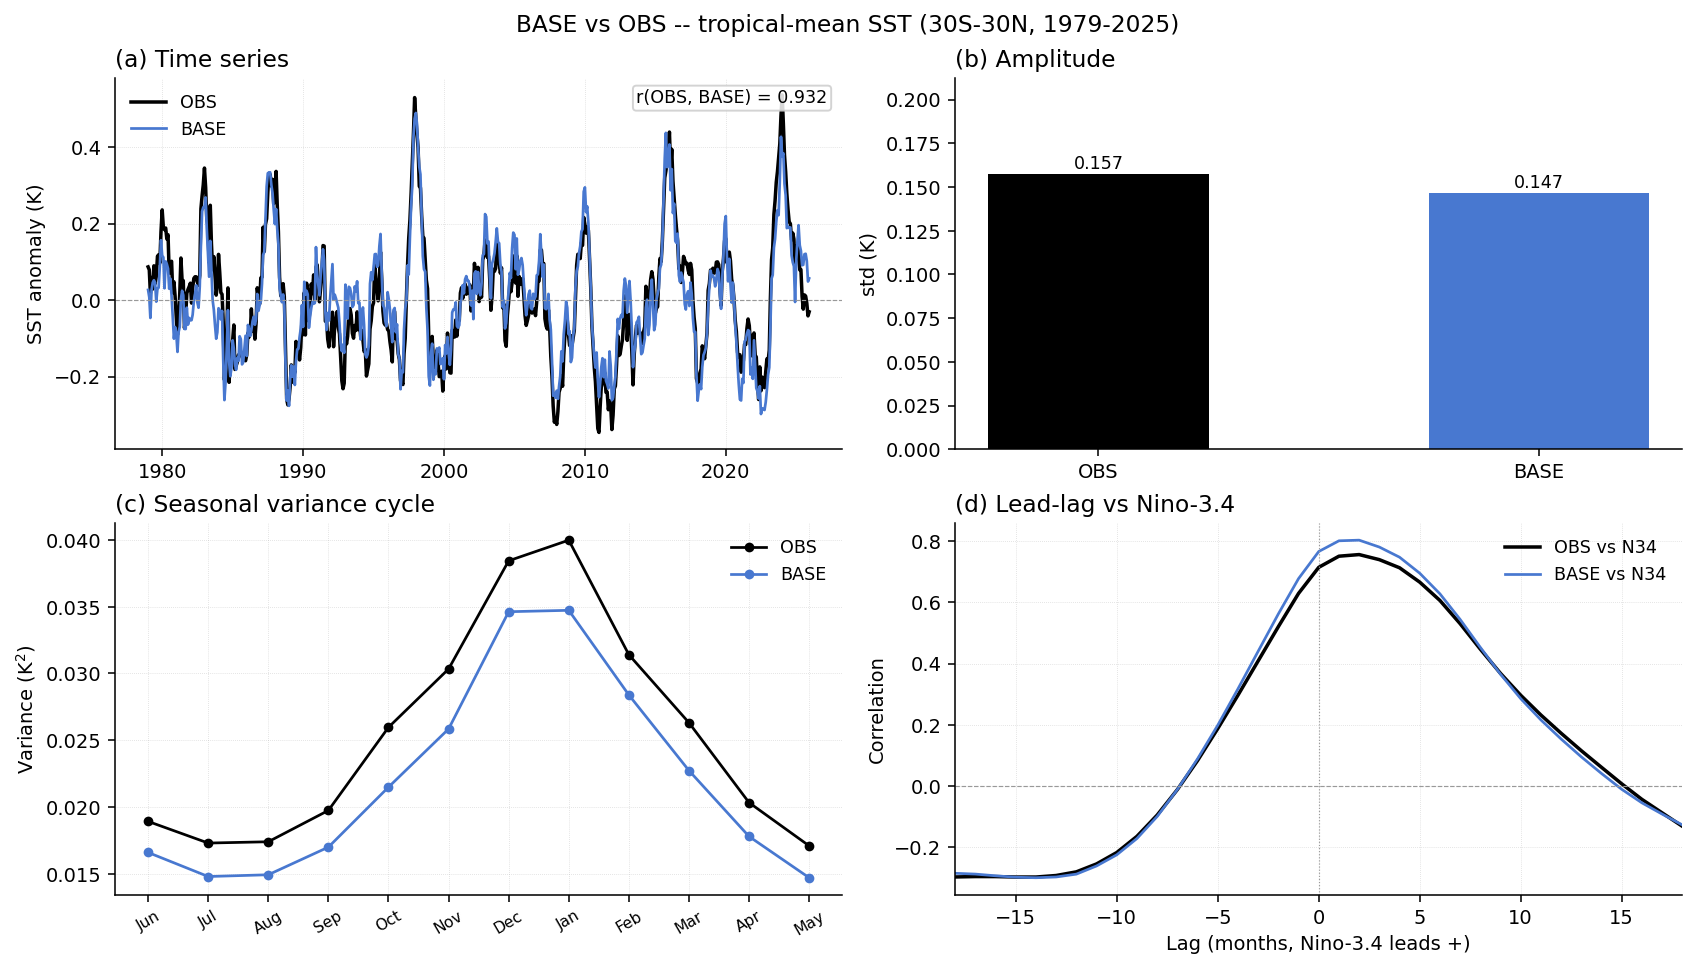

In [8]:
# ============================================================
# FIG 2 -- BASE vs OBS benchmark (tropical-mean SST, 30S-30N)
#   (a) monthly time series
#   (b) amplitude std
#   (c) seasonal variance cycle (Jun-May x-axis)
#   (d) lead-lag correlation with Nino-3.4
# In-sample: 1979-2025. Linear detrend.
# Depends: CELL A (SST_1d_obs, SST_1d_base, ds_idx, tcom)
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

VALID  = slice('1979-01-01', '2025-12-31')
MAXLAG = 18
COL2 = {'OBS': 'k', 'BASE': '#4878D0'}
ORDER2 = ['OBS', 'BASE']

series2 = {
    'OBS':  SST_1d_obs.sel(time=VALID),
    'BASE': SST_1d_base.sel(time=VALID),
}
nino_obs2 = ds_idx['Nino34'].sel(time=VALID)

def leadlag_corr(y, x, lags):
    y_np = y.values; x_np = x.values
    rs = []
    for lag in lags:
        if lag >= 0:
            xi, yi = x_np[:len(x_np) - lag], y_np[lag:]
        else:
            xi, yi = x_np[-lag:], y_np[:len(y_np) + lag]
        fin = np.isfinite(xi) & np.isfinite(yi)
        rs.append(float(np.corrcoef(xi[fin], yi[fin])[0, 1]) if fin.sum() > 10 else float('nan'))
    return np.array(rs)

lags2 = np.arange(-MAXLAG, MAXLAG + 1)

def _seasonal_var(da):
    df = pd.DataFrame({'v': da.values, 'm': pd.DatetimeIndex(da.time.values).month})
    return df.groupby('m')['v'].var()

r_obs2  = leadlag_corr(series2['OBS'],  nino_obs2, lags2)
r_base2 = leadlag_corr(series2['BASE'], nino_obs2, lags2)

r_base_obs = float(np.corrcoef(series2['OBS'].values, series2['BASE'].values)[0, 1])

plt.rcParams.update({'figure.dpi': 140, 'axes.spines.top': False,
                     'axes.spines.right': False})
fig, axes = plt.subplots(2, 2, figsize=(12, 6.8), constrained_layout=True)
fig.suptitle('BASE vs OBS -- tropical-mean SST (30S-30N, 1979-2025)', fontsize=12)

# (a) time series
ax = axes[0, 0]
for k in ORDER2:
    ax.plot(series2[k].time, series2[k].values, color=COL2[k],
            lw=1.8 if k == 'OBS' else 1.4, label=k)
ax.axhline(0, color='0.6', lw=0.6, ls='--')
ax.set_title('(a) Time series', loc='left')
ax.set_ylabel('SST anomaly (K)')
ax.legend(frameon=False, fontsize=9)
ax.text(0.98, 0.97, f'r(OBS, BASE) = {r_base_obs:.3f}', transform=ax.transAxes,
        fontsize=9, va='top', ha='right',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.85, ec='0.8'))
ax.grid(ls=':', lw=0.4, alpha=0.5)

# (b) amplitude
ax = axes[0, 1]
stds2 = [float(series2[k].std().values) for k in ORDER2]
bars = ax.bar(ORDER2, stds2, color=[COL2[k] for k in ORDER2], width=0.5)
ax.set_ylabel('std (K)')
ax.set_title('(b) Amplitude', loc='left')
ax.set_ylim(0, max(stds2) * 1.35)
for bar, v in zip(bars, stds2):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.003, f'{v:.3f}',
            ha='center', fontsize=9)

# (c) seasonal variance cycle
ax = axes[1, 0]
mon_order  = [6, 7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5]
mon_labels = ['Jun','Jul','Aug','Sep','Oct','Nov','Dec','Jan','Feb','Mar','Apr','May']
for k in ORDER2:
    sv = _seasonal_var(series2[k])
    vals = [sv.get(m, float('nan')) for m in mon_order]
    ax.plot(range(12), vals, color=COL2[k], lw=1.4, marker='o', ms=4, label=k)
ax.set_xticks(range(12))
ax.set_xticklabels(mon_labels, fontsize=8, rotation=30)
ax.set_ylabel('Variance (K$^2$)')
ax.set_title('(c) Seasonal variance cycle', loc='left')
ax.legend(frameon=False, fontsize=9)
ax.grid(ls=':', lw=0.4, alpha=0.5)

# (d) lead-lag
ax = axes[1, 1]
ax.plot(lags2, r_obs2,  color=COL2['OBS'],  lw=1.8, label='OBS vs N34')
ax.plot(lags2, r_base2, color=COL2['BASE'], lw=1.4, label='BASE vs N34')
ax.axhline(0, color='0.6', lw=0.6, ls='--')
ax.axvline(0, color='0.6', lw=0.6, ls=':')
ax.set_xlabel('Lag (months, Nino-3.4 leads +)')
ax.set_ylabel('Correlation')
ax.set_title('(d) Lead-lag vs Nino-3.4', loc='left')
ax.set_xlim(-MAXLAG, MAXLAG)
ax.legend(frameon=False, fontsize=9)
ax.grid(ls=':', lw=0.4, alpha=0.5)

plt.show()


## 6. Figure 3 — OBS vs C1=0 / C2=0 / C1&C2=0 for tropical-mean SST

**Draft Fig. 3.** Same diagnostics as Fig. 2, but for XRO experiments that zero selected blocks of the seasonally-varying operator L(t) while holding the residual forcing fixed:

* `C1=0_ALL` — removes feedbacks from the eight non-ENSO modes back onto ENSO (Niño-3.4, WWV),
* `C2=0_ALL` — removes teleconnections from ENSO to the other modes,
* `C1&C2=0_ALL` — removes both directions simultaneously.

Each experiment replays the identical residual forcing through the modified operator, then reconstructs tropical-mean SST through the same β(month) used for OBS/BASE in Fig. 2. Legend annotates the OBS correlation r of each curve.

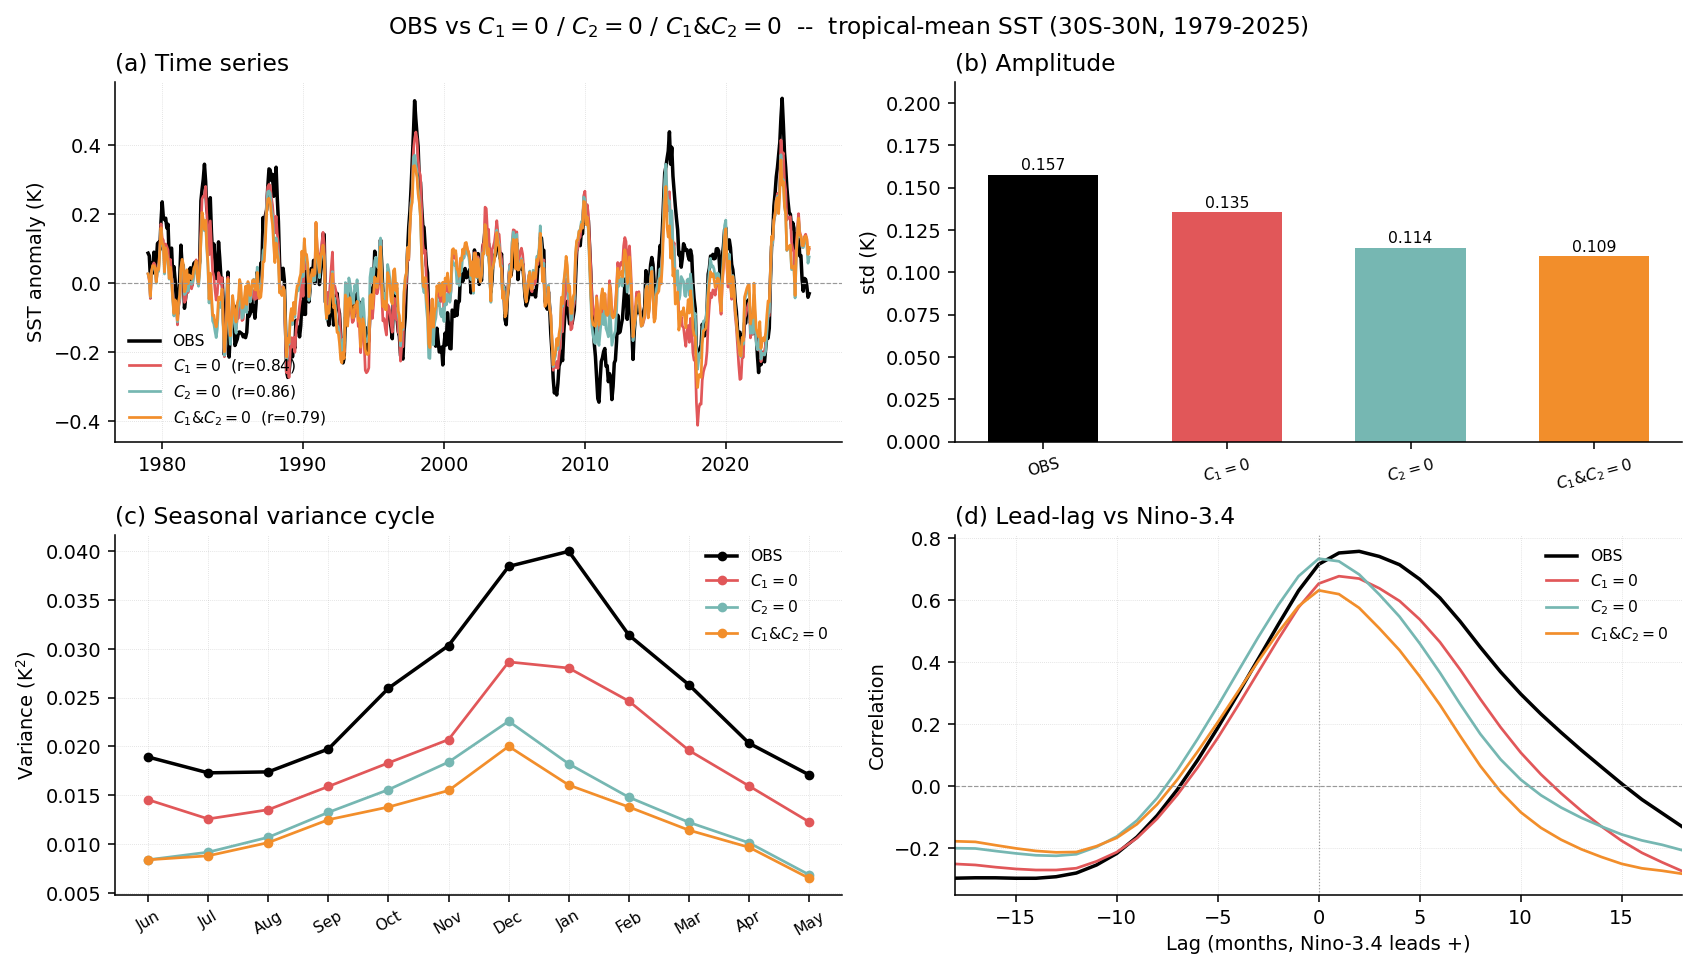

In [9]:
# ============================================================
# FIG 3 -- OBS vs C1=0/C2=0/C1&C2=0 (tropical-mean SST, 30S-30N)
#   Same 4-panel layout as FIG 2.
# Depends: CELL A (SST_1d_obs/c1/c2/c12, ds_idx)
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

VALID3 = slice('1979-01-01', '2025-12-31')
MAXLAG3 = 18
COL3 = {'OBS': 'k', 'C1=0': '#e15759', 'C2=0': '#76b7b2', 'C1&C2=0': '#f28e2b'}
ORDER3 = ['OBS', 'C1=0', 'C2=0', 'C1&C2=0']
LBL3   = {
    'OBS':     'OBS',
    'C1=0':    r'$C_1=0$',
    'C2=0':    r'$C_2=0$',
    'C1&C2=0': r'$C_1$&$C_2=0$',
}

series3 = {
    'OBS':     SST_1d_obs.sel(time=VALID3),
    'C1=0':    SST_1d_c1.sel(time=VALID3),
    'C2=0':    SST_1d_c2.sel(time=VALID3),
    'C1&C2=0': SST_1d_c12.sel(time=VALID3),
}
nino_obs3 = ds_idx['Nino34'].sel(time=VALID3)

def _leadlag(y, x, lags):
    y_np = y.values; x_np = x.values
    rs = []
    for lag in lags:
        if lag >= 0:
            xi, yi = x_np[:len(x_np) - lag], y_np[lag:]
        else:
            xi, yi = x_np[-lag:], y_np[:len(y_np) + lag]
        fin = np.isfinite(xi) & np.isfinite(yi)
        rs.append(float(np.corrcoef(xi[fin], yi[fin])[0, 1]) if fin.sum() > 10 else float('nan'))
    return np.array(rs)

def _svar(da):
    df = pd.DataFrame({'v': da.values, 'm': pd.DatetimeIndex(da.time.values).month})
    return df.groupby('m')['v'].var()

lags3 = np.arange(-MAXLAG3, MAXLAG3 + 1)

r_vs_obs3 = {}
r_nino3   = {}
for k in ORDER3:
    if k == 'OBS':
        r_vs_obs3[k] = 1.0
    else:
        fin = np.isfinite(series3['OBS'].values) & np.isfinite(series3[k].values)
        r_vs_obs3[k] = float(np.corrcoef(series3['OBS'].values[fin],
                                          series3[k].values[fin])[0, 1])
    r_nino3[k] = _leadlag(series3[k], nino_obs3, lags3)

plt.rcParams.update({'figure.dpi': 140, 'axes.spines.top': False,
                     'axes.spines.right': False})
fig, axes = plt.subplots(2, 2, figsize=(12, 6.8), constrained_layout=True)
fig.suptitle(r'OBS vs $C_1=0$ / $C_2=0$ / $C_1$&$C_2=0$  --  tropical-mean SST (30S-30N, 1979-2025)', fontsize=12)

# (a)
ax = axes[0, 0]
for k in ORDER3:
    lbl = LBL3[k] if k == 'OBS' else f'{LBL3[k]}  (r={r_vs_obs3[k]:.2f})'
    ax.plot(series3[k].time, series3[k].values, color=COL3[k],
            lw=1.8 if k == 'OBS' else 1.4, label=lbl)
ax.axhline(0, color='0.6', lw=0.6, ls='--')
ax.set_title('(a) Time series', loc='left')
ax.set_ylabel('SST anomaly (K)')
ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.grid(ls=':', lw=0.4, alpha=0.5)

# (b)
ax = axes[0, 1]
stds3 = [float(series3[k].std().values) for k in ORDER3]
bars = ax.bar(range(len(ORDER3)), stds3, color=[COL3[k] for k in ORDER3], width=0.6)
ax.set_xticks(range(len(ORDER3)))
ax.set_xticklabels([LBL3[k] for k in ORDER3], rotation=15, fontsize=8)
ax.set_ylabel('std (K)')
ax.set_title('(b) Amplitude', loc='left')
ax.set_ylim(0, max(stds3) * 1.35)
for bar, v in zip(bars, stds3):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.003, f'{v:.3f}',
            ha='center', fontsize=8)

# (c)
ax = axes[1, 0]
mon_order  = [6, 7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5]
mon_labels = ['Jun','Jul','Aug','Sep','Oct','Nov','Dec','Jan','Feb','Mar','Apr','May']
for k in ORDER3:
    sv = _svar(series3[k])
    vals = [sv.get(m, float('nan')) for m in mon_order]
    ax.plot(range(12), vals, color=COL3[k],
            lw=1.8 if k == 'OBS' else 1.4, marker='o', ms=4, label=LBL3[k])
ax.set_xticks(range(12))
ax.set_xticklabels(mon_labels, fontsize=8, rotation=30)
ax.set_ylabel('Variance (K$^2$)')
ax.set_title('(c) Seasonal variance cycle', loc='left')
ax.legend(frameon=False, fontsize=8)
ax.grid(ls=':', lw=0.4, alpha=0.5)

# (d)
ax = axes[1, 1]
for k in ORDER3:
    ax.plot(lags3, r_nino3[k], color=COL3[k],
            lw=1.8 if k == 'OBS' else 1.4, label=LBL3[k])
ax.axhline(0, color='0.6', lw=0.6, ls='--')
ax.axvline(0, color='0.6', lw=0.6, ls=':')
ax.set_xlabel('Lag (months, Nino-3.4 leads +)')
ax.set_ylabel('Correlation')
ax.set_title('(d) Lead-lag vs Nino-3.4', loc='left')
ax.set_xlim(-MAXLAG3, MAXLAG3)
ax.legend(frameon=False, fontsize=8)
ax.grid(ls=':', lw=0.4, alpha=0.5)

plt.show()


## 7. Figure 4 — Pan-tropical composite El Niño LTT Hovmöller

Composite analysis over all ONI-based El Niño events within 1979–2025:

- **Event selection:** ONI (3-month running mean of Niño-3.4) ≥ +0.5 °C for at least 5 overlapping 3-mo periods.
- **Window:** 24 months centered on Jan(0) – Dec(+1) (top = Jan(0), bottom = Dec(+1)).
- **Top row:** composite mean Hovmöller for OBS, BASE, C1=0, C2=0, C1&C2=0 (color range ±1.5 K).
- **Bottom row:** composite difference `(case − BASE)` for C1=0, C2=0, C1&C2=0 (color range ±0.4 K).
- **Significance:** two-sided one-sample *t*-test on the event dimension (H₀: mean = 0). Points not significant at *α* = 0.05 are overlaid with black dots; a figure caption clarifies the convention.

Output stored in `res_comp_elnino_ltt_oni`.


ONI-based El Nino events (12):
  1982-05 -> 1983-05   peak 1982-12 = +2.42 C
  1986-09 -> 1988-01   peak 1987-08 = +1.53 C
  1991-06 -> 1992-06   peak 1992-01 = +1.72 C
  1994-09 -> 1995-02   peak 1994-12 = +1.12 C
  1997-05 -> 1998-04   peak 1997-12 = +2.70 C
  2002-06 -> 2003-02   peak 2002-11 = +1.48 C
  2004-08 -> 2005-01   peak 2004-09 = +0.69 C
  2006-09 -> 2007-01   peak 2006-11 = +0.97 C
  2009-07 -> 2010-03   peak 2009-12 = +1.54 C
  2014-10 -> 2016-05   peak 2015-12 = +2.68 C
  2018-10 -> 2019-06   peak 2019-04 = +0.75 C
  2023-06 -> 2024-04   peak 2023-12 = +1.82 C
Event years candidate: [1982, 1987, 1991, 1994, 1997, 2002, 2004, 2006, 2009, 2015, 2019, 2023]
Composite years actually used: [1982, 1987, 1991, 1994, 1997, 2002, 2004, 2006, 2009, 2015, 2019, 2023]


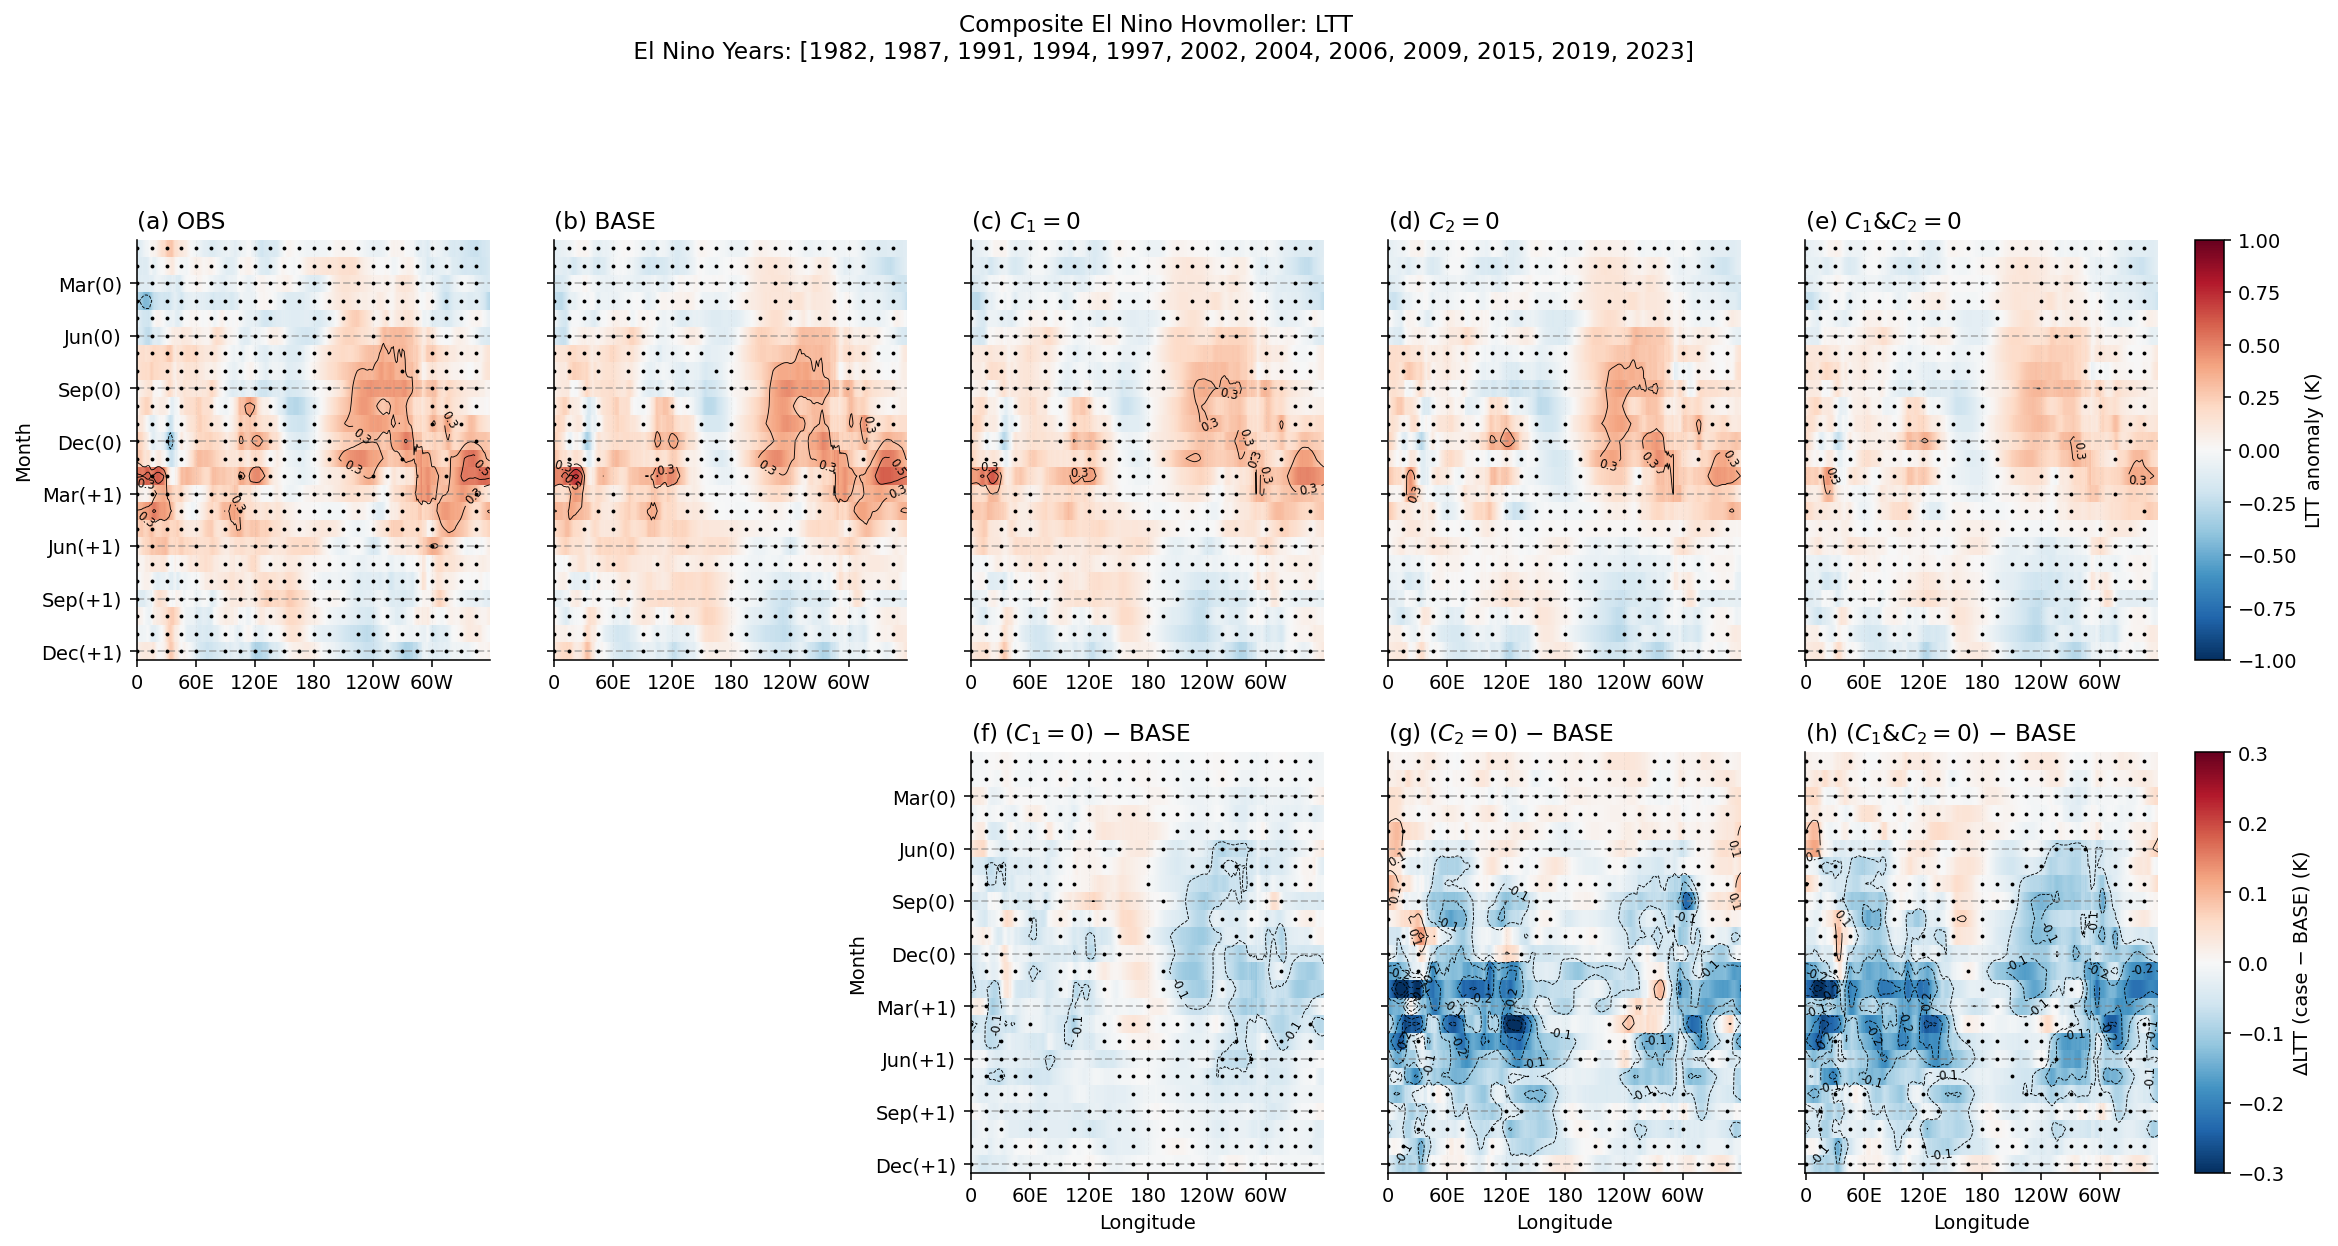

In [11]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

EVENT_BASE      = slice("1979-01-01", "2025-12-31")
REL_START_MONTH = 1
N_REL_MONTHS    = 24

FIXED_LIMIT_TOP = 1.0
FIXED_LIMIT_DEL = 0.3
FIGSIZE         = (17.4, 9.8)

XGRID_LINE_STYLE = "--"
XGRID_LINE_WIDTH = 0.45
XGRID_LINE_ALPHA = 0.15

SHOW_CONTOURS     = True
CONTOUR_FRAC_TOP  = 0.20
CONTOUR_FRAC_DEL  = 0.10
N_CONTOUR_TOP     = 13
N_CONTOUR_DEL     = 11

ONI_THRESHOLD = 0.5
ONI_MIN_RUN   = 5

need = ["ds_idx","hov_raw","stack_event_windows","add_contours","add_y_guides","get_lon_ticks_labels_360_sparse","relmonth_labels","get_nino34_series","to_month_start"]
miss = [k for k in need if k not in globals()]
if miss:
    raise RuntimeError("Missing " + str(miss) + ". Please run CELL F once first.")

def build_oni_from_ds(ds, base=EVENT_BASE):
    n34 = get_nino34_series(ds)
    n34 = to_month_start(n34.sel(time=base).dropna("time"))
    s = pd.Series(n34.values, index=pd.DatetimeIndex(n34.time.values).to_period("M").to_timestamp(), name="N34")
    oni = s.rolling(window=3, center=True, min_periods=3).mean()
    oni.name = "ONI"
    return oni

def select_elnino_years_oni(oni, threshold=ONI_THRESHOLD, min_run=ONI_MIN_RUN):
    above = (oni >= threshold).astype(int).fillna(0).values
    times = oni.index
    events = []
    i = 0
    n = len(above)
    while i < n:
        if above[i] == 1:
            j = i
            while j < n and above[j] == 1:
                j += 1
            if (j - i) >= min_run:
                seg = oni.iloc[i:j]
                events.append((times[i], times[j-1], seg.idxmax(), float(seg.max())))
            i = j
        else:
            i += 1
    years = []
    for (_, _, peak_ts, _) in events:
        m = peak_ts.month
        y = peak_ts.year
        years.append(y - 1 if m == 1 else y)
    return events, list(dict.fromkeys(years))

oni_series = build_oni_from_ds(ds_idx, base=EVENT_BASE)
events_oni, elnino_years = select_elnino_years_oni(oni_series)

print("ONI-based El Nino events (" + str(len(events_oni)) + "):")
for (st, ed, pk, pv) in events_oni:
    print("  " + st.strftime("%Y-%m") + " -> " + ed.strftime("%Y-%m") + "   peak " + pk.strftime("%Y-%m") + " = " + ("%+.2f" % pv) + " C")
print("Event years candidate:", elnino_years)

stacks = {k: stack_event_windows(hov_raw[k], elnino_years, start_month=REL_START_MONTH, nmonths=N_REL_MONTHS) for k in hov_raw.keys()}
means  = {k: stacks[k].mean("event", skipna=True) for k in stacks.keys()}

dstacks = {k: stack_event_windows(hov_raw[k] - hov_raw["BASE"], elnino_years, start_month=REL_START_MONTH, nmonths=N_REL_MONTHS) for k in ["C1","C2","C12"]}
dmeans  = {k: dstacks[k].mean("event", skipna=True) for k in dstacks.keys()}

means_plot_rev  = {k: v.isel(rel_month=slice(None, None, -1)) for k, v in means.items()}
dmeans_plot_rev = {k: v.isel(rel_month=slice(None, None, -1)) for k, v in dmeans.items()}

used_years = stacks["BASE"]["event"].values.tolist()
print("Composite years actually used:", used_years)

# -----------------------------------------------------------
# Significance masks (two-sided one-sample t-test, alpha=0.05)
#   H0: mean across events == 0
#   mask == True  -> NOT significant at 95% (dots will be drawn)
# -----------------------------------------------------------
from scipy.stats import ttest_1samp

SIG_ALPHA     = 0.05
DOT_SIZE      = 16
DOT_COLOR     = "k"
DOT_STRIDE_X  = 15   # every Nth longitude grid cell
DOT_STRIDE_Y  = 1   # every Nth rel_month step

def _nonsig_mask_from_stack(stack):
    """
    stack dims: (event, rel_month, lon).
    Returns a 2D boolean mask (rel_month, lon) where True = NOT significant.
    Reversed along rel_month to match *_plot_rev orientation.
    """
    arr = stack.values  # (event, rel_month, lon)
    # Need at least 2 finite events per gridpoint; otherwise treat as non-sig (True)
    with np.errstate(invalid="ignore"):
        _, p = ttest_1samp(arr, popmean=0.0, axis=0, nan_policy="omit")
    p = np.asarray(p)
    nonsig = ~(p < SIG_ALPHA)   # True where p >= alpha or p is NaN
    # reverse rel_month to match *_plot_rev
    return nonsig[::-1, :]

# define order BEFORE building sig masks (used both here and below)
order_top = ["OBS","BASE","C1","C2","C12"]

sig_masks_top = {k: _nonsig_mask_from_stack(stacks[k])  for k in order_top}
sig_masks_del = {k: _nonsig_mask_from_stack(dstacks[k]) for k in ["C1","C2","C12"]}

def _draw_nonsig_dots(ax, lon, y, mask, sx=DOT_STRIDE_X, sy=DOT_STRIDE_Y):
    """mask shape: (len(y), len(lon)); True -> draw a dot."""
    ny, nx = mask.shape
    yy, xx = np.meshgrid(y, lon, indexing="ij")
    sub = np.zeros_like(mask, dtype=bool)
    sub[::sy, ::sx] = True
    sel = mask & sub
    if sel.any():
        ax.scatter(xx[sel], yy[sel], s=DOT_SIZE, c=DOT_COLOR,
                   marker=".", linewidths=0, zorder=5)


# Roll longitude to 0-360 so date line (180) is at center
lon_orig = means_plot_rev["BASE"]["lon"].values
if lon_orig.min() < 0:
    sort_idx_lon = np.argsort((lon_orig + 360) % 360)
    def _to0360(da):
        return da.assign_coords(lon=(da.lon + 360) % 360).sortby('lon')
    means_plot_rev  = {k: _to0360(v) for k, v in means_plot_rev.items()}
    dmeans_plot_rev = {k: _to0360(v) for k, v in dmeans_plot_rev.items()}
    sig_masks_top = {k: v[:, sort_idx_lon] for k, v in sig_masks_top.items()}
    sig_masks_del = {k: v[:, sort_idx_lon] for k, v in sig_masks_del.items()}

# (already defined above) order_top    = ["OBS","BASE","C1","C2","C12"]
titles_top   = ["(a) OBS","(b) BASE",r"(c) $C_1=0$",r"(d) $C_2=0$",r"(e) $C_1$&$C_2=0$"]
delta_keys   = [None, None, "C1", "C2", "C12"]
delta_titles = ["", "", r"(f) ($C_1=0$) − BASE", r"(g) ($C_2=0$) − BASE", r"(h) ($C_1$&$C_2=0$) − BASE"]

fig, axes = plt.subplots(2, 5, figsize=FIGSIZE, sharex=False, sharey=True)
fig.subplots_adjust(left=0.08, right=0.98, top=0.80, bottom=0.12, wspace=0.18, hspace=0.22)

fig.suptitle("Composite El Nino Hovmoller: LTT \n El Nino Years: " + str(used_years), fontsize=12, y=0.965)

Href = means_plot_rev["BASE"]
y    = np.arange(Href.sizes["rel_month"])
lon  = Href["lon"].values
xmin = float(np.nanmin(lon))
xmax = float(np.nanmax(lon))

lon_ticks, lon_ticklabels = get_lon_ticks_labels_360_sparse()

tick_pos         = np.arange(0, N_REL_MONTHS, 3)
all_tick_lab     = relmonth_labels(start_month=REL_START_MONTH, nmonths=N_REL_MONTHS)
all_tick_lab_rev = all_tick_lab[::-1]
tick_lab         = [all_tick_lab_rev[i] for i in tick_pos]

# ---- top row: OBS / BASE / C1 / C2 / C12 ----
im_top = None
for j, key in enumerate(order_top):
    H = means_plot_rev[key]
    im_top = axes[0, j].pcolormesh(
        lon, y, H.values,
        cmap="RdBu_r",
        vmin=-FIXED_LIMIT_TOP, vmax=FIXED_LIMIT_TOP,
        shading="auto"
    )
    if SHOW_CONTOURS:
        add_contours(axes[0, j], lon, y, H.values,
                     FIXED_LIMIT_TOP, CONTOUR_FRAC_TOP, N_CONTOUR_TOP)
    axes[0, j].set_title(titles_top[j], loc="left")
    _draw_nonsig_dots(axes[0, j], lon, y, sig_masks_top[key])

# ---- bottom row: blanks under OBS/BASE, then ΔC1 / ΔC2 / ΔC12 ----
axes[1, 0].axis("off")
axes[1, 1].axis("off")

im_bot = None
for j, key in enumerate(delta_keys):
    if key is None:
        continue
    D = dmeans_plot_rev[key]
    im_bot = axes[1, j].pcolormesh(
        lon, y, D.values,
        cmap="RdBu_r",
        vmin=-FIXED_LIMIT_DEL, vmax=FIXED_LIMIT_DEL,
        shading="auto"
    )
    if SHOW_CONTOURS:
        add_contours(axes[1, j], lon, y, D.values,
                     FIXED_LIMIT_DEL, CONTOUR_FRAC_DEL, N_CONTOUR_DEL)
    axes[1, j].set_title(delta_titles[j], loc="left")
    _draw_nonsig_dots(axes[1, j], lon, y, sig_masks_del[key])

# ---- longitude ticks on all axes that have data ----
for ax in [axes[0,0], axes[0,1], axes[0,2], axes[0,3], axes[0,4],
           axes[1,2], axes[1,3], axes[1,4]]:
    if ax.has_data():
        ax.set_xticks(lon_ticks)
        ax.set_xticklabels(lon_ticklabels)

axes[1, 2].set_xlabel("Longitude")
axes[1, 3].set_xlabel("Longitude")
axes[1, 4].set_xlabel("Longitude")

# ---- shared y ticks, grid, y-guides ----
visible_axes = [ax for ax in axes.flat if ax.has_data()]
for ax in visible_axes:
    ax.set_yticks(tick_pos)
    ax.set_yticklabels([""] * len(tick_pos))
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle=XGRID_LINE_STYLE,
            linewidth=XGRID_LINE_WIDTH, alpha=XGRID_LINE_ALPHA)
    add_y_guides(ax, tick_pos, xmin, xmax)

axes[0, 0].set_yticklabels(tick_lab)
axes[0, 0].tick_params(axis="y", labelleft=True, pad=4)
axes[0, 0].set_ylabel("Month")

axes[1, 2].set_yticklabels(tick_lab)
axes[1, 2].tick_params(axis="y", labelleft=True, pad=4)
axes[1, 2].set_ylabel("Month")

# NOTE: data are already reversed explicitly; do NOT invert y-axis here.

# ---- colorbars (right side, one per row, hard-coded from subplots_adjust math) ----
# Layout: top=0.80, bottom=0.12, hspace=0.22, nrows=2
# row_h = (top - bottom) / (nrows + (nrows-1)*hspace) = 0.68 / 2.22 = 0.3063
# Top row y0 = 0.80 - 0.3063 = 0.4937; Bottom row y0 = 0.12 (height 0.3063)
fig.subplots_adjust(right=0.91)
cax1 = fig.add_axes([0.925, 0.4937, 0.012, 0.3063])
cb1  = fig.colorbar(im_top, cax=cax1, orientation="vertical")
cb1.set_label("LTT anomaly (K)")

if im_bot is not None:
    cax2 = fig.add_axes([0.925, 0.12, 0.012, 0.3063])
    cb2  = fig.colorbar(im_bot, cax=cax2, orientation="vertical")
    cb2.set_label("ΔLTT (case − BASE) (K)")

plt.show()

res_comp_elnino_ltt_oni = {
    "years":   used_years,
    "means":   means_plot_rev,
    "dmeans":  dmeans_plot_rev,
    "stacks":  stacks,
    "dstacks": dstacks,
}


## 8. Figure 5 — Basin-targeted composite El Niño LTT difference Hovmöller

Repeats the composite analysis of Figure 4 but confines the coupling removal to one basin subset at a time. Uses the same ONI event list and the same significance stippling.

Basin subsets:

- **ExPO** (extratropical Pacific): NPMM, SPMM
- **IO** (Indian Ocean): IOB, IOD, SIOD
- **AO** (Atlantic): TNA, ATL3, SASD

For each basin, three variant replays are run (C1=0, C2=0, C1&C2=0, restricted to that basin's modes), composited over the same ONI event windows, differenced against the pan-tropical BASE, and laid out as a 3 × 3 grid:

- **Rows:** ExPO / IO / AO
- **Columns:** ΔC1 (C1=0 − BASE), ΔC2 (C2=0 − BASE), ΔC1&C2

All panels share the Δ LTT color scale (±0.4 K) with identical t-test stippling.

Output stored in `res_comp_elnino_ltt_basin`.


ONI El Nino years: [1982, 1987, 1991, 1994, 1997, 2002, 2004, 2006, 2009, 2015, 2019, 2023]
  Basin ExPO ...


  Basin IO ...


  Basin AO ...


Composite years: [1982, 1987, 1991, 1994, 1997, 2002, 2004, 2006, 2009, 2015, 2019, 2023]


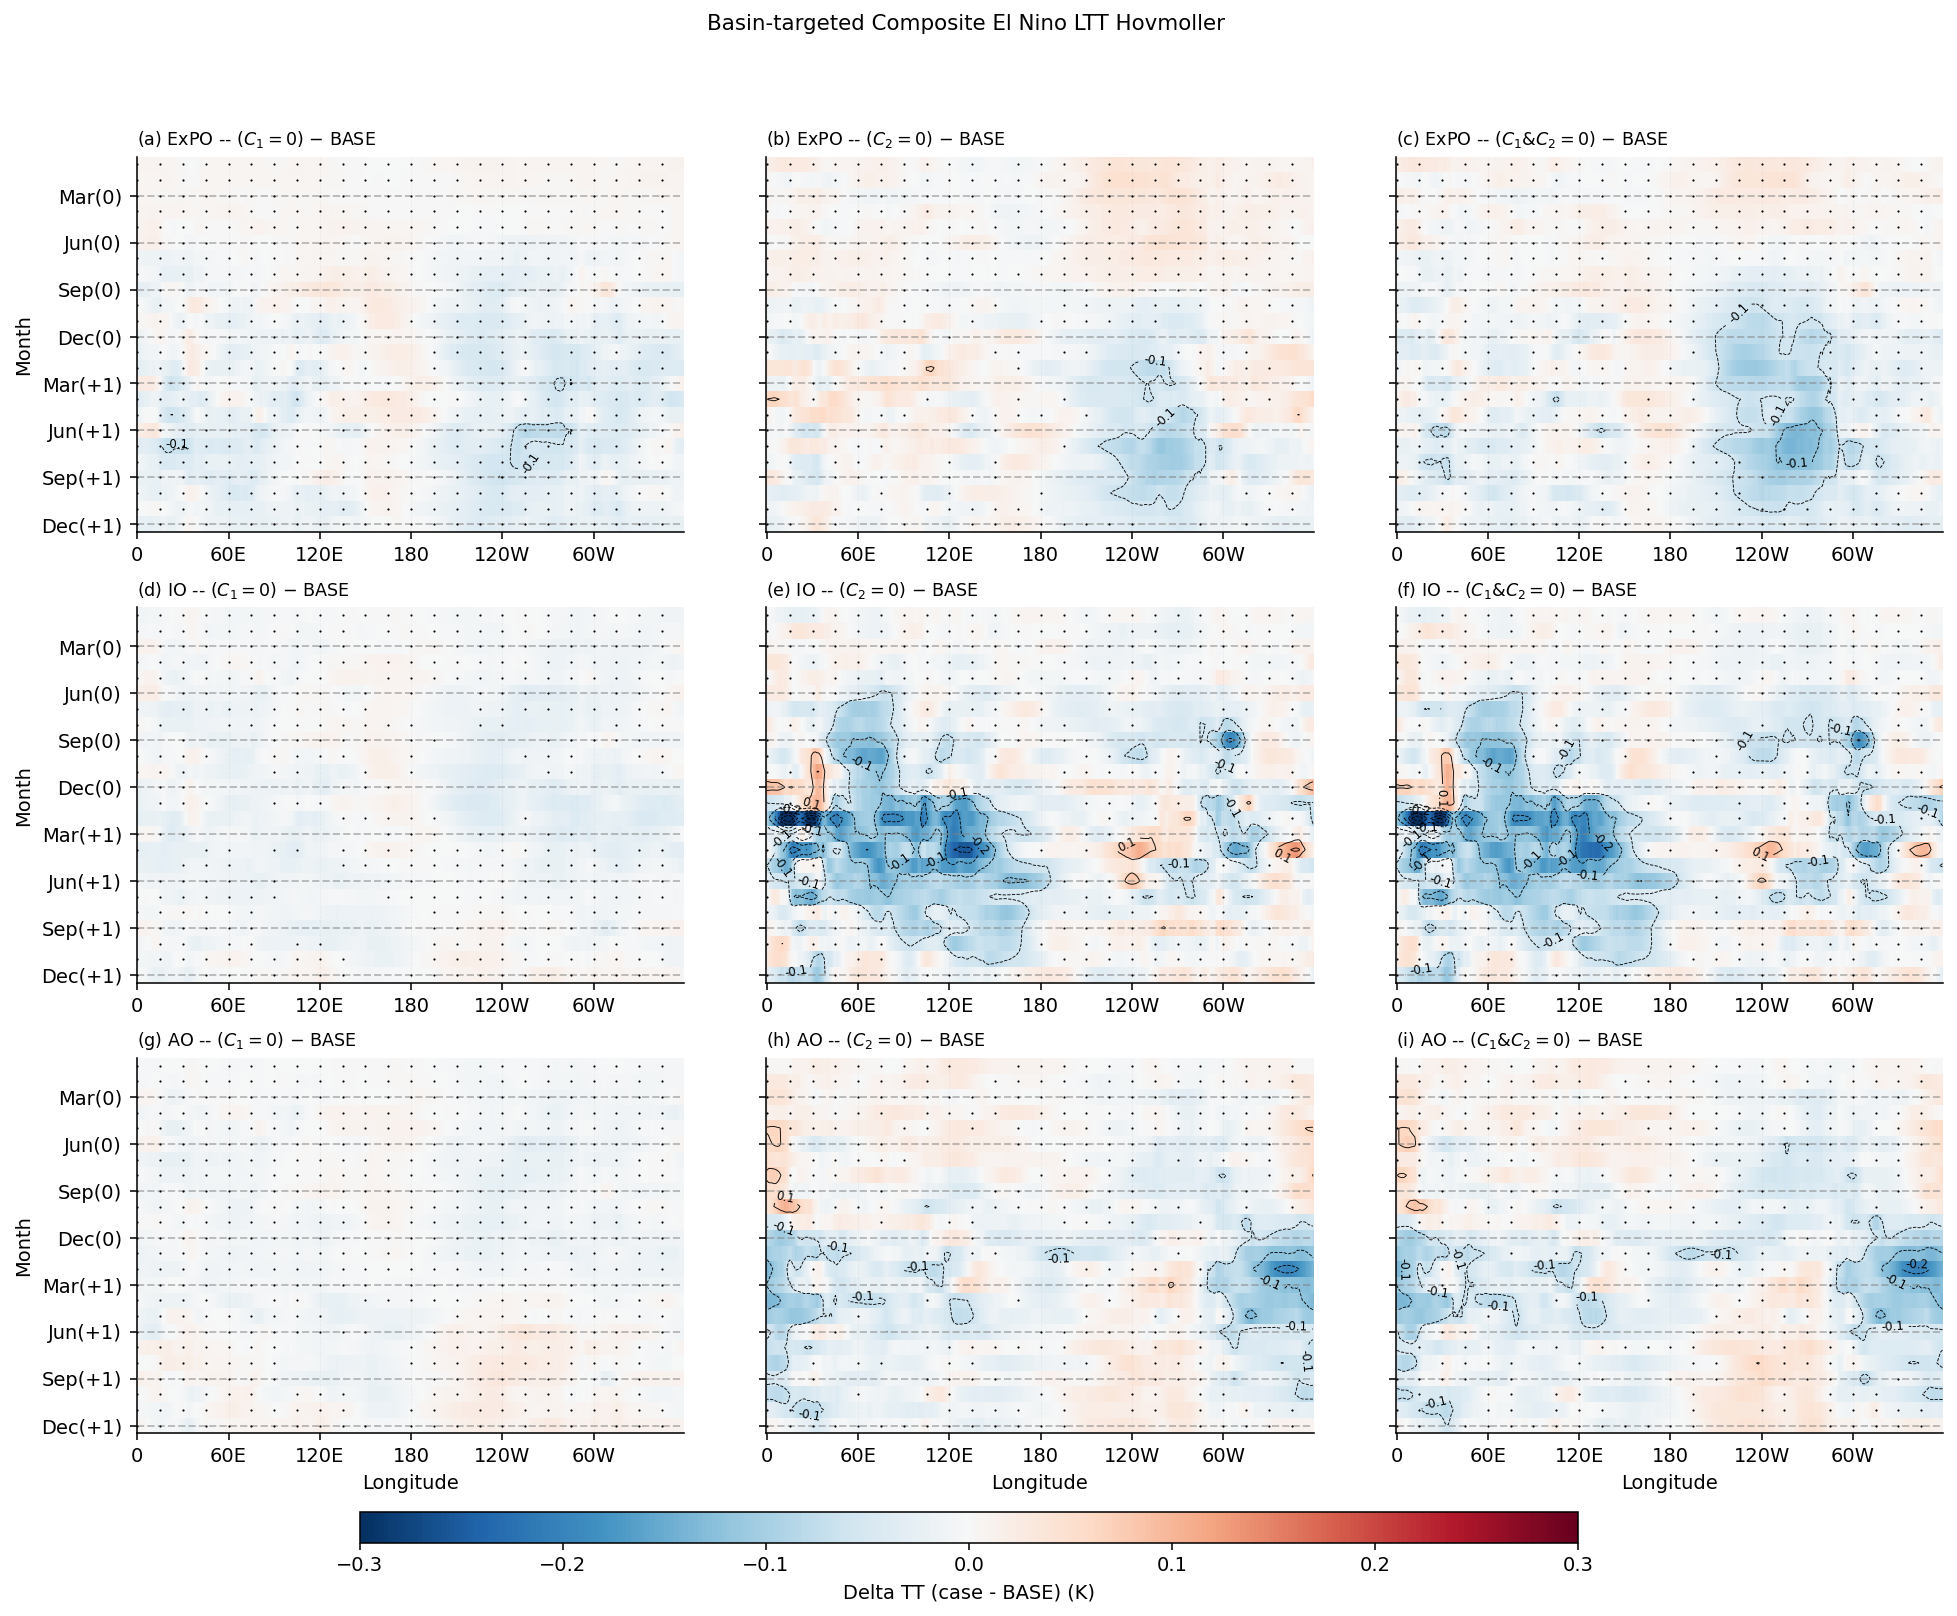

In [12]:
# ============================================================
# FIG 6 -- Basin-targeted composite El Nino TT Hovmoller
# For each basin (ExPO / IO / AO), composes the TT difference
# (C1=0, C2=0, C1&C2=0) vs BASE over ONI-based El Nino events.
# Layout: 3 rows x 3 cols (basin x experiment)
# Uses precomputed YY_basin replays from CELL A.
# Depends: CELL A + CELL TT
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import ttest_1samp

EVENT_BASE      = slice('1979-01-01', '2025-12-31')
REL_START_MONTH = 1
N_REL_MONTHS    = 24
FIXED_LIMIT_DEL = 0.3
FIGSIZE         = (14.5, 12.0)
XGRID_LINE_STYLE = '--'; XGRID_LINE_WIDTH = 0.45; XGRID_LINE_ALPHA = 0.15
SHOW_CONTOURS    = True; CONTOUR_FRAC_DEL = 0.10; N_CONTOUR_DEL = 11
ONI_THRESHOLD = 0.5; ONI_MIN_RUN = 5
SIG_ALPHA = 0.05; DOT_SIZE = 5; DOT_COLOR = 'k'
DOT_STRIDE_X = 15; DOT_STRIDE_Y = 1

need = ['YY_basin','tcom','ds_idx','hov_raw','rebuild_2d_from_YY_local','build_hov',
        'apply_shared_lon_mask','stack_event_windows','add_contours','add_y_guides',
        'get_lon_ticks_labels_360_sparse','relmonth_labels','get_nino34_series','to_month_start']
miss = [k for k in need if k not in globals()]
if miss:
    raise RuntimeError(f'Missing: {miss}. Run CELL A and CELL TT first.')

BASIN_MODES = {'ExPO': ['NPMM','SPMM'], 'IO': ['IOB','IOD','SIOD'], 'AO': ['TNA','ATL3','SASD']}
BASIN_KEYS  = {'C1': 'c1', 'C2': 'c2', 'C12': 'c12'}

# ONI event selection
def build_oni_from_ds(ds, base=EVENT_BASE):
    n34 = get_nino34_series(ds)
    n34 = to_month_start(n34.sel(time=base).dropna('time'))
    s   = pd.Series(n34.values,
                    index=pd.DatetimeIndex(n34.time.values).to_period('M').to_timestamp())
    return s.rolling(window=3, center=True, min_periods=3).mean().rename('ONI')

def select_elnino_years(oni, threshold=ONI_THRESHOLD, min_run=ONI_MIN_RUN):
    above = (oni >= threshold).astype(int).fillna(0).values
    times = oni.index; events = []; i = 0; n = len(above)
    while i < n:
        if above[i] == 1:
            j = i
            while j < n and above[j] == 1: j += 1
            if (j - i) >= min_run:
                seg = oni.iloc[i:j]
                events.append((times[i], times[j-1], seg.idxmax(), float(seg.max())))
            i = j
        else: i += 1
    years = []
    for (_, _, pk, _) in events:
        years.append(pk.year - 1 if pk.month == 1 else pk.year)
    return events, list(dict.fromkeys(years))

oni_series = build_oni_from_ds(ds_idx)
events_oni, elnino_years = select_elnino_years(oni_series)
print(f'ONI El Nino years: {elnino_years}')

BASE_hov = hov_raw['BASE']
panel_data, panel_dstacks = {}, {}
used_years_ref = None

for basin_name in ['ExPO', 'IO', 'AO']:
    print(f'  Basin {basin_name} ...')
    hov_b = {'BASE': BASE_hov}
    for exp_label, exp_key in BASIN_KEYS.items():
        npz_key = f'{basin_name}_{exp_key}'
        TT_var_2d = rebuild_2d_from_YY_local(YY_basin[npz_key], tcom)
        hov_b[exp_label] = build_hov(TT_var_2d)
    hov_b, _, _ = apply_shared_lon_mask(hov_b)
    d_hov = {k: hov_b[k] - hov_b['BASE'] for k in ['C1', 'C2', 'C12']}
    dstacks_b = {k: stack_event_windows(d_hov[k], elnino_years,
                                        start_month=REL_START_MONTH,
                                        nmonths=N_REL_MONTHS)
                 for k in ['C1', 'C2', 'C12']}
    dmeans_b   = {k: dstacks_b[k].mean('event', skipna=True) for k in dstacks_b}
    panel_data[basin_name]    = {k: v.isel(rel_month=slice(None, None, -1))
                                 for k, v in dmeans_b.items()}
    panel_dstacks[basin_name] = dstacks_b
    if used_years_ref is None:
        used_years_ref = dstacks_b['C1']['event'].values.tolist()

print(f'Composite years: {used_years_ref}')

def _nonsig_mask(stack):
    arr = stack.values
    with np.errstate(invalid='ignore'):
        _, p = ttest_1samp(arr, popmean=0.0, axis=0, nan_policy='omit')
    return (~(p < SIG_ALPHA))[::-1, :]

sig_masks = {b: {k: _nonsig_mask(panel_dstacks[b][k]) for k in ['C1','C2','C12']}
             for b in ['ExPO','IO','AO']}

def _draw_dots(ax, lon, y, mask, sx=DOT_STRIDE_X, sy=DOT_STRIDE_Y):
    yy, xx = np.meshgrid(y, lon, indexing='ij')
    sub = np.zeros_like(mask, dtype=bool); sub[::sy, ::sx] = True
    sel = mask & sub
    if sel.any():
        ax.scatter(xx[sel], yy[sel], s=DOT_SIZE, c=DOT_COLOR, marker='.', linewidths=0, zorder=5)

# Roll longitude to 0-360 so date line (180) is at center
_ref_lon = panel_data['ExPO']['C1']['lon'].values
if _ref_lon.min() < 0:
    _sort_idx_lon = np.argsort((_ref_lon + 360) % 360)
    def _to0360(da):
        return da.assign_coords(lon=(da.lon + 360) % 360).sortby('lon')
    panel_data = {b: {k: _to0360(v) for k, v in bd.items()}
                  for b, bd in panel_data.items()}
    sig_masks  = {b: {k: v[:, _sort_idx_lon] for k, v in bm.items()}
                  for b, bm in sig_masks.items()}

fig, axes = plt.subplots(3, 3, figsize=FIGSIZE, sharex=False, sharey=True)
fig.subplots_adjust(left=0.09, right=0.98, top=0.88, bottom=0.12, wspace=0.15, hspace=0.20)
fig.suptitle(
    f'Basin-targeted Composite El Nino LTT Hovmoller ',
    fontsize=11, y=0.965
)

col_titles = {'C1': r'($C_1=0$) − BASE', 'C2': r'($C_2=0$) − BASE',
              'C12': r'($C_1$&$C_2=0$) − BASE'}
panel_letters = [['(a)','(b)','(c)'], ['(d)','(e)','(f)'], ['(g)','(h)','(i)']]

Href = panel_data['ExPO']['C1']
y    = np.arange(Href.sizes['rel_month'])
lon  = Href['lon'].values
xmin, xmax = float(np.nanmin(lon)), float(np.nanmax(lon))
lon_ticks, lon_ticklabels = get_lon_ticks_labels_360_sparse()
tick_pos = np.arange(0, N_REL_MONTHS, 3)
all_lab  = relmonth_labels(start_month=REL_START_MONTH, nmonths=N_REL_MONTHS)
tick_lab = [all_lab[::-1][i] for i in tick_pos]

im = None
for i, basin_name in enumerate(['ExPO', 'IO', 'AO']):
    for j, key in enumerate(['C1', 'C2', 'C12']):
        ax = axes[i, j]
        D  = panel_data[basin_name][key]
        im = ax.pcolormesh(lon, y, D.values, cmap='RdBu_r',
                           vmin=-FIXED_LIMIT_DEL, vmax=FIXED_LIMIT_DEL, shading='auto')
        if SHOW_CONTOURS:
            add_contours(ax, lon, y, D.values, FIXED_LIMIT_DEL, CONTOUR_FRAC_DEL, N_CONTOUR_DEL)
        _draw_dots(ax, lon, y, sig_masks[basin_name][key])
        ax.set_title(f'{panel_letters[i][j]} {basin_name} -- {col_titles[key]}',
                     loc='left', fontsize=9)
        ax.set_xticks(lon_ticks); ax.set_xticklabels(lon_ticklabels)
        ax.set_yticks(tick_pos); ax.set_yticklabels([''] * len(tick_pos))
        ax.grid(axis='x', linestyle=XGRID_LINE_STYLE,
                linewidth=XGRID_LINE_WIDTH, alpha=XGRID_LINE_ALPHA)
        add_y_guides(ax, tick_pos, xmin, xmax)

for i in range(3):
    axes[i, 0].set_yticklabels(tick_lab)
    axes[i, 0].tick_params(axis='y', labelleft=True, pad=4)
    axes[i, 0].set_ylabel('Month')
for j in range(3):
    axes[2, j].set_xlabel('Longitude')

cax = fig.add_axes([0.20, 0.055, 0.60, 0.018])
cb  = fig.colorbar(im, cax=cax, orientation='horizontal')
cb.set_label('Delta TT (case - BASE) (K)')
plt.show()


## 9. CMIP hybrid-operator ensemble (88 CMIP5/CMIP6 models)

Runs the hybrid-operator replay engine across the 88 CMIP5/CMIP6 models of Supplementary Data 1. Only the seasonally varying linear operator L comes from each CMIP model; everything else (initial condition, observed residual forcing, β projections, μ/σ standardization) stays observational.

**Experiments:** BASE / C1 / L_ENSO / C2 / L8 / C12L8 × ALL / ExPO / IO / AO.
**Outputs:** `per_model_series`, `df`, `df_consistent`, `series`, `series_ltt`, `nino34_series`.

**Standardization recipe** (`USE_STANDARD_BETA = True`): observed tropical-mean SST/LTT targets and all 10 mode indices are re-detrended over the common evaluation window EVAL_WIN (1979–2010) before fitting; the observed operator, β_SST, β_LTT, and μ/σ are all computed from the re-detrended observations over the same window, so every hybrid input (observations and models) uses a linear detrend over the identical 1979–2010 window.

**Caching:** if `cmip_per_model_series_unified.pkl` exists it is loaded (fast); otherwise the engine runs across all CMIP fits in `MODEL_DIR` (≈10–15 min) and saves the cache.

**Required inputs on disk:** `MODEL_DIR = pocheng_tropical_mean_SST_XRO/` (per-model `*_fit.nc` + `*_timeseries.nc`), `XRO_indices_oras5_extended_2025.nc`, `ERA5_tropical_mean_sst_anom_detr_1950-2025.nc`, `ERA5_LTT_1000-850_detr_tropmean_1979-2025.nc`.

In [13]:
# ============================================================
# CELL B — CMIP hybrid-L replay engine (v2)
#
# What's new vs v1:
#   v1 just loaded `cmip_per_model_series_unified.pkl` and crashed if missing.
#   v2 contains the FULL CMIP engine inline:
#     - Reads per-model XRO fit/timeseries from MODEL_DIR (~91 models)
#     - Hybrid-L patching (replaces selected L sub-blocks with OBS L)
#     - Sub-step integration + DELTA injection per model
#     - Saves per-model y_sst, y_ltt for downstream figures (Figs 7-10)
#
#   Load-or-compute:
#     If CMIP_PKL exists → load (fast).
#     If missing → run full engine inline (~10-15 min for 91 models) + cache.
#
# Dependencies: CELL A must have run first (provides OBS engine context).
# ============================================================
import os, glob, pickle, time
import numpy as np
import xarray as xr
import pandas as pd
from XRO import XRO

# ── Paths ─────────────────────────────────────────────────────
DATA_DIR_B     = DATA_DIR.rstrip("/") + "/"
CMIP_PKL       = os.path.join(DATA_DIR, "reference_cache", "cmip_per_model_series_unified.pkl")
CMIP_PKL_REPRO = os.path.join(CACHE_OUT, "cmip_per_model_series_unified_repro.pkl")
FORCE_RECOMPUTE = True   # reproduction mode: never read the cache
MODEL_DIR      = DATA_DIR_B + "pocheng_tropical_mean_SST_XRO"
IDX_FILE_B     = DATA_DIR_B + "XRO_indices_oras5_extended_2025.nc"
ERA_TROPIC_SST = DATA_DIR_B + "ERA5_tropical_mean_sst_anom_detr_1950-2025.nc"
ERA_TROPIC_VAR = "tropical_mean_sst_anom_detr"
ERA_LTT_FILE   = DATA_DIR_B + "ERA5_LTT_1000-850_detr_tropmean_1979-2025.nc"
LTT_VAR        = "ltt_tropmean_detr"
BETA_LTT_FILE  = DATA_DIR_B + "beta_from_patterns.nc"

# === USE_STANDARD_BETA: when True, fit β_SST + β_LTT + Lac_obs_B from OBS
# data that has been re-detrended over EVAL_WIN (1979-2010). This is the
# scientifically correct recipe per the paper standard:
#   - All hybrid-experiment OBS data: 1979-2010 range + linear detrend over 1979-2010
#   - Models also: 1979-2010 range + linear detrend over 1979-2010
# (As opposed to using pre-computed detrend-over-longer-window files, which
#  leaves residual EVAL trend and biases β by ~1-8% per mode.)
# Fig 1-6 (OBS-only) are unaffected — they use OBS 1979-2025 in CELL A. ===
USE_STANDARD_BETA = True
STATE10_B    = ["Nino34","WWV","NPMM","SPMM","IOB","IOD","SIOD","TNA","ATL3","SASD"]
MODES9_SST_B = ["Nino34","NPMM","SPMM","IOB","IOD","SIOD","TNA","ATL3","SASD"]
MODES9_LTT_B = ["NINO34","NPMM","SPMM","IOB","IOD","SIOD","TNA","ATL3","SASD"]
BASINS_B = {
    "ExPO": ["NPMM","SPMM"],
    "IO"  : ["IOB","IOD","SIOD"],
    "AO"  : ["TNA","ATL3","SASD"],
    "ALL" : ["NPMM","SPMM","IOB","IOD","SIOD","TNA","ATL3","SASD"],
}
CASES_TO_RUN = [
    "BASE", "OBS_L", "L_ENSO",
    "C1_ALL","C2_ALL","C12_ALL","L8_ALL","C12L8_ALL",
    "C1_ExPO","C2_ExPO","C12_ExPO","L8_ExPO","C12L8_ExPO",
    "C1_IO","C2_IO","C12_IO","L8_IO","C12L8_IO",
    "C1_AO","C2_AO","C12_AO","L8_AO","C12L8_AO",
]
EVAL_WIN_B = slice("1979-01-01","2010-12-31")  # unified engine: all metrics on EVAL_WIN
AC_ORDER_B = 1; NSTEP_B = 10; MAXLAG_B = 18; EXPLODE = 1e6

# ── Engine helpers (re-defined locally for self-containment) ──────
def _ensure_alias_B(ds):
    if "NINO34" in ds and "Nino34" not in ds: ds["Nino34"] = ds["NINO34"]
    if "Nino34" in ds and "NINO34" not in ds: ds["NINO34"] = ds["Nino34"]
    return ds

def _find_pairs(model_dir):
    fits = sorted(glob.glob(os.path.join(model_dir, "*_fit.nc")))
    tss  = sorted(glob.glob(os.path.join(model_dir, "*_timeseries.nc")))
    fk = {os.path.basename(p).replace("_fit.nc",""): p for p in fits}
    tk = {os.path.basename(p).replace("_timeseries.nc",""): p for p in tss}
    return [(k, fk[k], tk[k]) for k in sorted(set(fk) & set(tk))
            if 'OBS' not in k]  # skip OBS pair

def _subset_reorder_fit(fit_ds, state10):
    names = [str(v).strip() for v in fit_ds["var_names"].values]
    up    = [n.upper() for n in names]
    idx   = [up.index(n.upper()) for n in state10]
    out   = fit_ds.isel(ranky=idx, rankx=idx).copy(deep=True)
    out["var_names"].values[:] = np.array(state10)
    return out

def _build_stepper_B(Lac, nstep=10):
    ncycle = Lac.shape[-1]; dt = 1.0/ncycle/nstep
    def step(X, mon_idx):
        X_in = np.array(X, float, copy=True); tmp = np.zeros_like(X_in)
        Lm = Lac[:, :, mon_idx]
        for _ in range(nstep):
            X_in += (Lm @ X_in) * dt
            tmp  += X_in/nstep
        return tmp
    return step

def _compute_delta_B(stepper, X_np, months_idx, shift):
    r, T = X_np.shape; dlt = np.zeros((r, T), float)
    for i in range(T-1):
        mon = int((months_idx[i] + shift) % 12)
        dlt[:, i+1] = (X_np[:, i+1] -
                       stepper(X_np[:, i].reshape(r, 1), mon).squeeze())
    return dlt

def _best_shift_B(stepper, X_np, months_idx):
    best = None
    for sh in range(12):
        d = _compute_delta_B(stepper, X_np, months_idx, sh)
        rms = float(np.sqrt(np.nanmean(d[:, 1:]**2)))
        if best is None or rms < best[0]:
            best = (rms, sh, d)
    return best

def _hybrid_patch(Lac_model, Lac_obs, var_names, subset, which):
    out  = Lac_model.copy()
    vnU  = [v.upper() for v in var_names]
    ENSO = [vnU.index("NINO34"), vnU.index("WWV")]
    nm   = out.shape[-1]
    # Only compute SUB when needed (skip for OBS_L / L_ENSO which don't use subset)
    if which in ("C1", "C2", "C12", "L8"):
        if subset is None:
            raise ValueError(f"subset must be provided for which={which}")
        SUB = [vnU.index(s.upper()) for s in subset]
    def put(rows, cols):
        for j in range(nm):
            out[np.ix_(rows, cols, [j])] = Lac_obs[np.ix_(rows, cols, [j])]
    if which == "C1":    put(ENSO, SUB)
    elif which == "C2":  put(SUB, ENSO)
    elif which == "C12": put(ENSO, SUB); put(SUB, ENSO)
    elif which == "L8":  put(SUB, SUB)
    elif which == "L_ENSO": put(ENSO, ENSO)
    elif which == "OBS_L":
        out = Lac_obs.copy()  # full replacement
    return out

def _parse_case(tag):
    if tag == "BASE":   return "NONE", None
    if tag == "OBS_L":  return "OBS_L", None
    if tag == "L_ENSO": return "L_ENSO", None
    for prefix, which in [("C12L8_","C12L8"),("C12_","C12"),("C1_","C1"),
                           ("C2_","C2"),("L8_","L8")]:
        if tag.startswith(prefix):
            return which, BASINS_B[tag[len(prefix):]]
    raise ValueError(f"unknown tag: {tag}")

def _month_z_with_B(mu, sig, Z_da):
    mons = xr.DataArray(pd.DatetimeIndex(Z_da.time.values).month,
                        dims=["time"], coords={"time": Z_da.time})
    MU  = mu.sel(month=mons).transpose("time","mode")
    SIG = sig.sel(month=mons).transpose("time","mode")
    return ((Z_da-MU)/SIG).where(np.isfinite((Z_da-MU)/SIG), 0.0)

def _fit_beta_monthly_B(Zz, y_da):
    Zz, y = xr.align(Zz, y_da, join="inner")
    ti = pd.DatetimeIndex(Zz.time.values)
    modes = list(Zz["mode"].values)
    beta = np.full((len(modes), 12), np.nan, float)
    for mm in range(1, 13):
        sel = (ti.month == mm)
        Zm, ym = Zz.values[sel], y.values[sel].astype(float)
        ok = np.isfinite(ym) & np.all(np.isfinite(Zm), axis=1)
        if ok.sum() >= 12:
            beta[:, mm-1], *_ = np.linalg.lstsq(Zm[ok], ym[ok], rcond=None)
    return xr.DataArray(beta, dims=["mode","month"],
                        coords={"mode": modes, "month": np.arange(1,13)})

def _recon_from_beta_B(beta, Zz):
    mons = xr.DataArray(pd.DatetimeIndex(Zz.time.values).month,
                        dims=["time"], coords={"time": Zz.time})
    B = beta.sel(month=mons).transpose("time","mode")
    return (B*Zz).sum("mode")

def _intersect_time(t1, t2):
    i1, i2 = pd.DatetimeIndex(t1), pd.DatetimeIndex(t2)
    common = i1.intersection(i2)
    return common.values, i1.get_indexer(common), i2.get_indexer(common)

def _compute_cmip_engine():
    """Run the full CMIP hybrid-L engine.
    Returns dict with per_model_series + OBS context vars + saved μ/σ/β."""
    print(f'[CMIP] Building OBS context (EVAL_WIN = 1979-2010) ...')
    ds_idx_B = _ensure_alias_B(xr.open_dataset(IDX_FILE_B)).drop_vars("month", errors="ignore")
    y_obs_sst_B = xr.open_dataset(ERA_TROPIC_SST)[ERA_TROPIC_VAR].rename("SST")
    y_obs_ltt_B = xr.open_dataset(ERA_LTT_FILE)[LTT_VAR].rename("LTT")
    X_obs_B, y_obs_sst_B = xr.align(ds_idx_B[STATE10_B].sel(time=EVAL_WIN_B),
                                      y_obs_sst_B.sel(time=EVAL_WIN_B), join="inner")
    X_obs_B, y_obs_ltt_B = xr.align(X_obs_B, y_obs_ltt_B.sel(time=EVAL_WIN_B), join="inner")
    obs_time = X_obs_B.time.values

    # ===== USE_STANDARD_BETA: re-detrend all hybrid OBS series over EVAL_WIN =====
    if USE_STANDARD_BETA:
        from scipy.signal import detrend as _detrend
        # Re-detrend y_obs_sst_B over 1979-2010 (removes residual trend from longer-window file)
        _y_s = _detrend(y_obs_sst_B.values, type="linear")
        y_obs_sst_B = y_obs_sst_B.copy(data=_y_s)
        # Re-detrend y_obs_ltt_B over 1979-2010
        _y_l = _detrend(y_obs_ltt_B.values, type="linear")
        y_obs_ltt_B = y_obs_ltt_B.copy(data=_y_l)
        # Re-detrend each mode in X_obs_B over 1979-2010
        for _v in list(X_obs_B.data_vars):
            _vals = _detrend(X_obs_B[_v].values, type="linear")
            X_obs_B[_v] = X_obs_B[_v].copy(data=_vals)
        print(f"  [STD recipe] Re-detrended y_obs_sst, y_obs_ltt, and 10 modes over EVAL_WIN")
        print(f"    y_obs_sst slope after re-detrend: {np.polyfit(np.arange(len(_y_s)), _y_s, 1)[0]:.2e} (was non-zero)")
        print(f"    y_obs_ltt slope after re-detrend: {np.polyfit(np.arange(len(_y_l)), _y_l, 1)[0]:.2e} (was non-zero)")
    # ===== END re-detrend =====
    months0_B = pd.DatetimeIndex(obs_time).month.values - 1

    xro_B = XRO(ncycle=12, ac_order=AC_ORDER_B, is_forward=True)
    X_np  = X_obs_B.to_array().values.astype(float)
    tfloat = np.arange(1./24., X_np.shape[1]/12., 1./12., dtype=float)
    fit_obs_B = xro_B.fit_matrix(X_np, var_names=STATE10_B, time=tfloat)
    Lac_obs_B = fit_obs_B["Lac"].values
    step_obs_B = _build_stepper_B(Lac_obs_B, nstep=NSTEP_B)
    rms_obs, BEST_SHIFT_B, DELTA_B = _best_shift_B(step_obs_B, X_np, months0_B)
    print(f'  [OBS context] best_shift={BEST_SHIFT_B}, delta_rms={rms_obs:.3f}')

    # β_SST (fitted on EVAL_WIN as confirmed by unified.pkl)
    mu_sst_B = X_obs_B[MODES9_SST_B].to_array("mode").groupby("time.month").mean("time")
    sig_sst_B = X_obs_B[MODES9_SST_B].to_array("mode").groupby("time.month").std("time")
    Z_sst = X_obs_B[MODES9_SST_B].to_array("mode").transpose("time","mode")
    Zzs = _month_z_with_B(mu_sst_B, sig_sst_B, Z_sst)
    beta_sst_B = _fit_beta_monthly_B(Zzs, y_obs_sst_B)

    # β_LTT (fit on EVAL_WIN, same recipe as β_SST — STD compliant)
    mu_ltt_for_fit_B  = X_obs_B[MODES9_LTT_B if MODES9_LTT_B[0]!="NINO34" else ["Nino34"]+MODES9_LTT_B[1:]].to_array("mode").groupby("time.month").mean("time")
    # Build LTT Z just like SST Z but with NINO34 alias
    _ltt_mode_keys = ["Nino34"] + MODES9_LTT_B[1:]  # 9 modes for LTT (Nino34 + 8 others)
    sig_ltt_for_fit_B = X_obs_B[_ltt_mode_keys].to_array("mode").groupby("time.month").std("time")
    Z_ltt_fit = X_obs_B[_ltt_mode_keys].to_array("mode").transpose("time","mode")
    Z_ltt_fit = Z_ltt_fit.assign_coords(mode=("mode", MODES9_LTT_B))  # rename Nino34→NINO34
    mu_ltt_for_fit_B  = mu_ltt_for_fit_B.assign_coords(mode=("mode", MODES9_LTT_B))
    sig_ltt_for_fit_B = sig_ltt_for_fit_B.assign_coords(mode=("mode", MODES9_LTT_B))
    Zzl = _month_z_with_B(mu_ltt_for_fit_B, sig_ltt_for_fit_B, Z_ltt_fit)
    beta_ltt_B = _fit_beta_monthly_B(Zzl, y_obs_ltt_B)
    print(f"  [STD recipe] β_LTT fitted from re-detrended OBS (was previously loaded from file)")

    # μ/σ for LTT modes
    Z_ltt = xr.concat(
        [X_obs_B["Nino34"].rename("NINO34")] +
        [X_obs_B[m].rename(m) for m in MODES9_LTT_B[1:]],
        dim="mode").assign_coords(mode=("mode", MODES9_LTT_B)).transpose("time","mode")
    mu_ltt_B  = Z_ltt.groupby("time.month").mean("time").transpose("mode","month")
    sig_ltt_B = Z_ltt.groupby("time.month").std("time").transpose("mode","month")


    idx_map_B = {n.upper(): i for i, n in enumerate(STATE10_B)}

    pairs = _find_pairs(MODEL_DIR)
    print(f'[CMIP] Found {len(pairs)} model pairs.')

    per_model_series = []
    t0 = time.time()
    # Exclude short-history models (ending at 2005-12) for unified 1979-2010 window
    short_history_cutoff = pd.Timestamp("2006-01-01")
    n_skipped_short = 0
    for pi, (key, fit_path, ts_path) in enumerate(pairs, 1):
        try:
            fit_cmip = xr.open_dataset(fit_path)
            fit_cmip10 = _subset_reorder_fit(fit_cmip, STATE10_B)
            Lac_cmip = fit_cmip10["Lac"].values
            ts_cmip = xr.open_dataset(ts_path)
            # Check model's full history end date — skip if ends before 2010
            model_t_end = pd.DatetimeIndex(ts_cmip.time.values)[-1]
            if model_t_end < short_history_cutoff:
                n_skipped_short += 1
                continue  # skip short-history model (extends only to ~2005)
            common_t, obs_idx, _ = _intersect_time(obs_time, ts_cmip.time.values)
            if len(common_t) < 36: continue
            mon_c = pd.DatetimeIndex(common_t).month.values - 1
            dlt = DELTA_B[:, obs_idx]
            X0 = X_np[:, obs_idx[0]]

            for tag in CASES_TO_RUN:
                which, subset = _parse_case(tag)
                if which == "NONE":
                    Lac_case = Lac_cmip.copy()
                elif which in ("OBS_L", "L_ENSO"):
                    Lac_case = _hybrid_patch(Lac_cmip, Lac_obs_B, STATE10_B, None, which)
                elif which == "C12L8":
                    Lac_case = _hybrid_patch(Lac_cmip, Lac_obs_B, STATE10_B, subset, "C12")
                    Lac_case = _hybrid_patch(Lac_case, Lac_obs_B, STATE10_B, subset, "L8")
                else:
                    Lac_case = _hybrid_patch(Lac_cmip, Lac_obs_B, STATE10_B, subset, which)

                step = _build_stepper_B(Lac_case, nstep=NSTEP_B)
                YY = np.zeros((len(STATE10_B), len(common_t)), float)
                YY[:, 0] = X0
                ok = True
                for i in range(len(common_t)-1):
                    mon = int((mon_c[i] + BEST_SHIFT_B) % 12)
                    YY[:, i+1] = (step(YY[:, i].reshape(-1, 1), mon)
                                   + dlt[:, i+1].reshape(-1, 1)).squeeze()
                    if (not np.all(np.isfinite(YY[:, i+1])) or
                            np.nanmax(np.abs(YY[:, i+1])) > EXPLODE):
                        ok = False; break
                if not ok: continue

                Z_s = xr.DataArray(
                    np.stack([YY[idx_map_B[m.upper()], :] for m in MODES9_SST_B], axis=1),
                    dims=["time","mode"],
                    coords={"time": common_t, "mode": MODES9_SST_B})
                yhat_sst = _recon_from_beta_B(beta_sst_B, _month_z_with_B(mu_sst_B, sig_sst_B, Z_s)).rename("SST")

                Z_l = xr.concat(
                    [xr.DataArray(YY[idx_map_B["NINO34"], :], dims=["time"],
                                  coords={"time": common_t}).rename("NINO34")] +
                    [xr.DataArray(YY[idx_map_B[m.upper()], :], dims=["time"],
                                  coords={"time": common_t}).rename(m) for m in MODES9_LTT_B[1:]],
                    dim="mode").assign_coords(mode=("mode", MODES9_LTT_B)).transpose("time","mode")
                yhat_ltt = _recon_from_beta_B(beta_ltt_B, _month_z_with_B(mu_ltt_B, sig_ltt_B, Z_l)).rename("LTT")

                per_model_series.append({
                    "model": key, "exp": tag, "time": common_t,
                    "Nino34": xr.DataArray(YY[idx_map_B["NINO34"], :],
                                            dims=["time"], coords={"time": common_t}),
                    "y_sst": yhat_sst, "y_ltt": yhat_ltt,
                })

            if pi % 10 == 0:
                print(f'  [{pi}/{len(pairs)}] elapsed {time.time()-t0:.1f}s')
        except Exception as e:
            print(f'  [WARN] {key}: {e}')

    print(f'[CMIP] Done: {len(per_model_series)} rows in {time.time()-t0:.1f}s '
          f'(skipped {n_skipped_short} short-history models ending ≤2005)')

    return {
        'per_model_series': per_model_series,
        'y_obs_sst': y_obs_sst_B, 'y_obs_ltt': y_obs_ltt_B, 'X_obs': X_obs_B,
        'WINDOW': EVAL_WIN_B, 'MAXLAG': MAXLAG_B,
        'mu_sst': mu_sst_B, 'sig_sst': sig_sst_B, 'beta_sst': beta_sst_B,
        'mu_ltt': mu_ltt_B, 'sig_ltt': sig_ltt_B, 'beta_ltt': beta_ltt_B,
    }

# ── Load-or-compute ─────────────────────────────────────────────────
if (not FORCE_RECOMPUTE) and os.path.exists(CMIP_PKL):
    print(f'Loading pre-computed CMIP results from {os.path.basename(CMIP_PKL)} ...')
    with open(CMIP_PKL, 'rb') as f:
        multi = pickle.load(f)
else:
    print(f'CMIP_PKL not found. Running engine from scratch (~10-15 min) ...')
    multi = _compute_cmip_engine()
    with open(CMIP_PKL_REPRO, 'wb') as f:
        pickle.dump(multi, f)
    print(f'  Recomputed → {CMIP_PKL_REPRO}')

# Export to globals (for downstream figure cells)
per_model_series = multi['per_model_series']
y_obs_sst        = multi['y_obs_sst']
y_obs_ltt        = multi['y_obs_ltt']
X_obs            = multi['X_obs']
EVAL_WIN         = multi['WINDOW']
MAXLAG           = multi['MAXLAG']
mu_sst_u, sig_sst_u, beta_sst_u = multi['mu_sst'], multi['sig_sst'], multi['beta_sst']
mu_ltt_u, sig_ltt_u, beta_ltt_u = multi['mu_ltt'], multi['sig_ltt'], multi['beta_ltt']

n_models = len(set(d['model'] for d in per_model_series))
exps_avail = sorted(set(d['exp'] for d in per_model_series))
print(f'  {len(per_model_series)} entries = {n_models} models × {len(exps_avail)} experiments')
print(f'  experiments: {exps_avail}')
print(f'  EVAL_WIN: {EVAL_WIN.start[:7]} → {EVAL_WIN.stop[:7]} ({len(y_obs_sst)} months)')


Loading pre-computed CMIP results from cmip_per_model_series_unified.pkl ...
  2024 entries = 88 models × 23 experiments
  experiments: ['BASE', 'C12L8_ALL', 'C12L8_AO', 'C12L8_ExPO', 'C12L8_IO', 'C12_ALL', 'C12_AO', 'C12_ExPO', 'C12_IO', 'C1_ALL', 'C1_AO', 'C1_ExPO', 'C1_IO', 'C2_ALL', 'C2_AO', 'C2_ExPO', 'C2_IO', 'L8_ALL', 'L8_AO', 'L8_ExPO', 'L8_IO', 'L_ENSO', 'OBS_L']
  EVAL_WIN: 1979-01 → 2010-12 (384 months)


## 10. Figure 6 — Skill r by basin × replaced feedback block (88 CMIP hybrid-operator experiments)

Per-basin (ALL / ExPO / IO / AO) box-and-whisker of correlation r against OBS for each
hybrid-L experiment (BASE / C1 / C2 / L8 / C12L8). Per-model trajectories shown as
thin gray lines; median in red. Below each box is a colored strip showing the median
peak lag τ for that experiment (white 0 mo → dark red 3 mo).

**Reading**: the more the box+whisker shifts upward across BASE → C12L8, the more the
substituted feedback contributes to skill recovery. The τ strip indicates whether the
fix also brings ENSO lead-lag closer to OBS.


Loaded 2024 entries; eval window: 1979-01 → 2010-12
Fixed ORDER (left → right): ['BASE', 'C1', 'L_ENSO', 'C2', 'L8', 'C12L8']


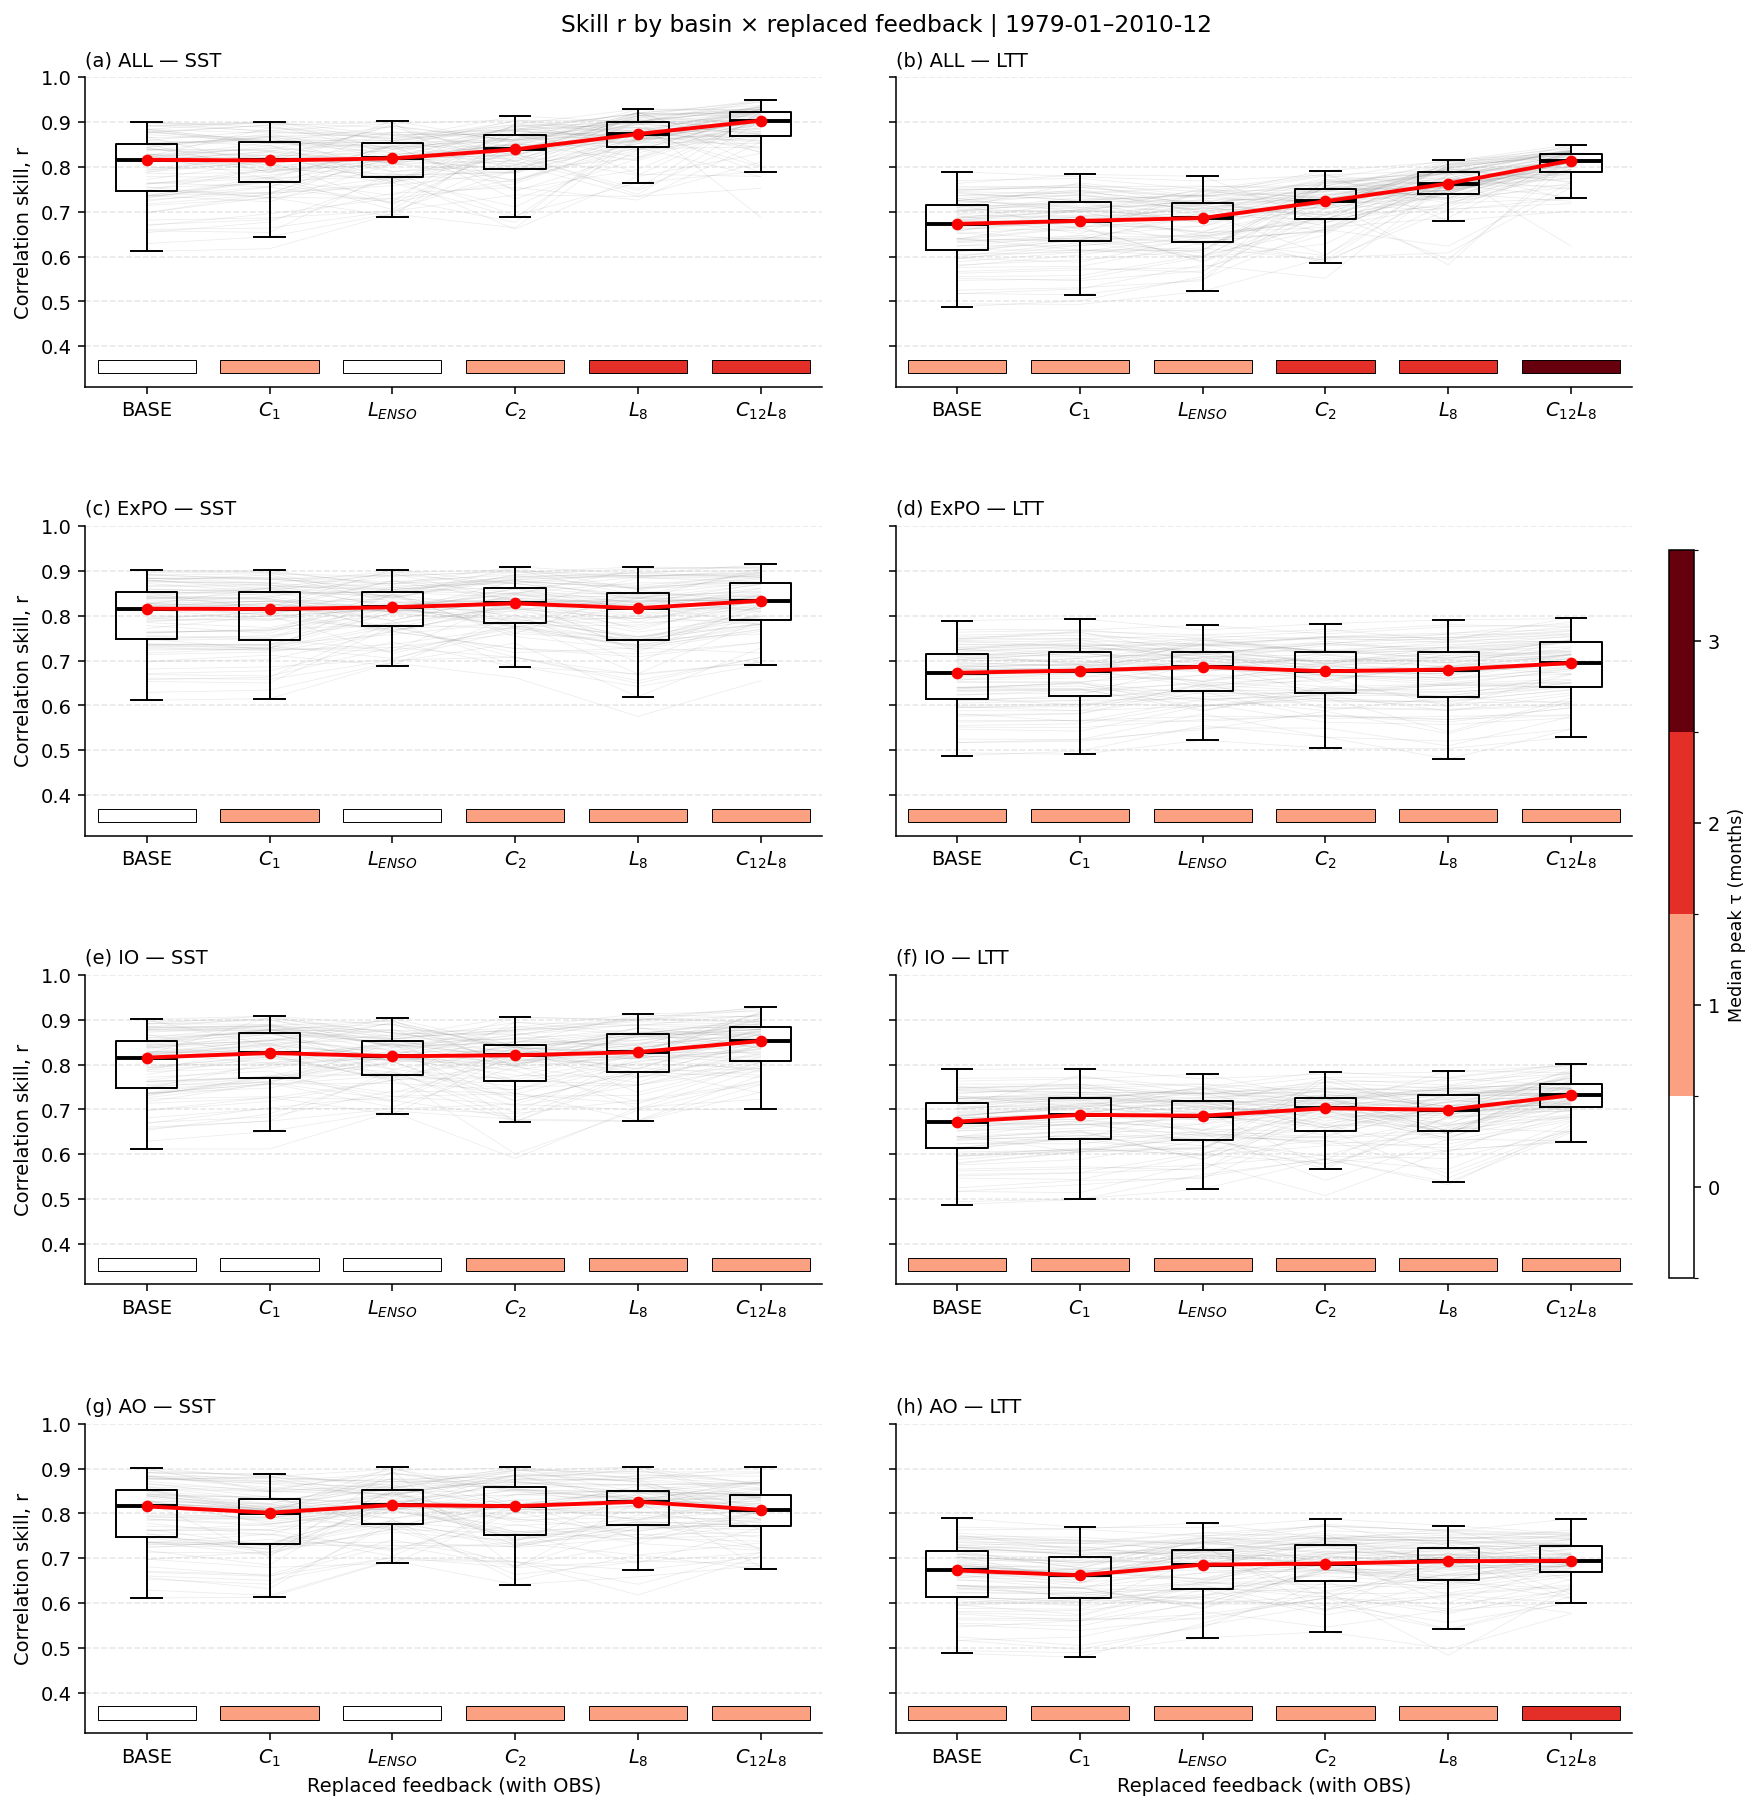

Saved: FigA_skill_by_basin.png


In [14]:
# ============================================================
# Setup: load unified CMIP engine output + helpers
# (replaces the Fig 7-10 narrative with FigA/S/T/U)
# ============================================================
import os, pickle, warnings
import numpy as np, xarray as xr, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle
warnings.filterwarnings('ignore')

# DATA_DIR from the setup cell
UNIFIED_WIN = slice("1979-01-01","2010-12-31")
EVAL_WIN    = UNIFIED_WIN
MAXLAG      = 18

unified_pkl = os.path.join(CACHE_OUT, "cmip_per_model_series_unified_repro.pkl")
if not os.path.isfile(unified_pkl):
    unified_pkl = os.path.join(DATA_DIR, "reference_cache", "cmip_per_model_series_unified.pkl")  # fallback: reference cache
if not os.path.isfile(unified_pkl):
    raise FileNotFoundError(f"Need {unified_pkl}\n"
                            "Run /tmp/run_cmip_engine_unified.py first.")
with open(unified_pkl, "rb") as f:
    _M = pickle.load(f)

per_model_series = _M["per_model_series"]
y_obs_sst = _M["y_obs_sst"]
y_obs_ltt = _M["y_obs_ltt"]
X_obs     = _M["X_obs"]
print(f"Loaded {len(per_model_series)} entries; eval window: "
      f"{EVAL_WIN.start[:7]} → {EVAL_WIN.stop[:7]}")

# ── shared helpers ─────────────────────────────────────────────────
def leadlag_corr(nino_da, y_da, maxlag=18):
    n, y = xr.align(nino_da, y_da, join="inner")
    lags = np.arange(-maxlag, maxlag+1)
    cc   = np.full_like(lags, np.nan, float)
    for i, tau in enumerate(lags):
        ns = n.shift(time=tau)
        a, b = xr.align(ns, y, join="inner")
        mv = np.isfinite(a.values) & np.isfinite(b.values)
        if mv.sum() >= 24:
            cc[i] = float(np.corrcoef(a.values[mv], b.values[mv])[0,1])
    return lags, cc

def _djf_var_xrophd(y_da, eval_window):
    y = y_da.sel(time=eval_window)
    mon_var = y.groupby("time.month").var("time", skipna=True)
    return float(mon_var.sel(month=[12,1,2]).mean().values)


# ============================================================
# Fig A — Skill r by basin × replaced feedback
# ============================================================
import matplotlib as mpl
from matplotlib.patches import Rectangle

BASINS_FOR_FIGA = ["ALL", "ExPO", "IO", "AO"]
BLOCKS_ALL = ["BASE", "L_ENSO", "C1", "C2", "L8", "C12L8"]

def _exp_name_for_basin(b, basin):
    if b == "BASE":   return "BASE"
    if b == "L_ENSO": return "L_ENSO"
    return f"{b}_{basin}"

def _r_and_lag_series(exp, kind, eval_win):
    y_obs = y_obs_sst if kind=='sst' else y_obs_ltt
    key = 'y_sst' if kind=='sst' else 'y_ltt'
    rows = []
    for rec in per_model_series:
        if rec['exp'] != exp: continue
        y_m = rec[key].sel(time=eval_win)
        y_o = y_obs.sel(time=eval_win)
        a, b = xr.align(y_m, y_o, join='inner')
        ok = np.isfinite(a.values) & np.isfinite(b.values)
        if ok.sum() >= 12:
            r = float(np.corrcoef(a.values[ok], b.values[ok])[0,1])
            n34 = rec['Nino34'].sel(time=eval_win)
            lags, cc = leadlag_corr(n34, y_m, MAXLAG)
            tau = int(lags[np.nanargmax(cc)]) if not np.all(np.isnan(cc)) else np.nan
            rows.append({'model': rec['model'], 'r': r, 'tau': tau})
    return pd.DataFrame(rows)

# τ colormap: 0–3 months range (4 levels)
TAU_VMAX = 3
reds = mpl.colormaps['Reds'].resampled(TAU_VMAX + 1)
tau_colors = [(1,1,1,1)] + [reds(i/TAU_VMAX) for i in range(1, TAU_VMAX + 1)]
tau_cmap = mpl.colors.ListedColormap(tau_colors, N=TAU_VMAX + 1)
tau_bounds = np.arange(-0.5, TAU_VMAX + 1.5, 1)
tau_norm = mpl.colors.BoundaryNorm(tau_bounds, ncolors=tau_cmap.N, clip=True)

fig, axes = plt.subplots(len(BASINS_FOR_FIGA), 2, figsize=(13, 13), sharey=True)
fig.suptitle(f"Skill r by basin × replaced feedback | {EVAL_WIN.start[:7]}–{EVAL_WIN.stop[:7]}",
             y=0.995, fontsize=12)

# Fixed left-to-right ordering for all panels
ORDER_FIXED = ["BASE", "C1", "L_ENSO", "C2", "L8", "C12L8"]
ORDER_SST = ORDER_FIXED
ORDER_LTT = ORDER_FIXED
LBL_FIXED = {
    "BASE":   "BASE",
    "C1":     r"$C_1$",
    "L_ENSO": r"$L_{ENSO}$",
    "C2":     r"$C_2$",
    "L8":     r"$L_8$",
    "C12L8":  r"$C_{12}L_8$",
}
print(f"Fixed ORDER (left → right): {ORDER_FIXED}")

for r_i, basin in enumerate(BASINS_FOR_FIGA):
    for c_i, kind in enumerate(['sst', 'ltt']):
        ax = axes[r_i, c_i]
        order = ORDER_SST if kind == "sst" else ORDER_LTT
        avail_pairs = [(b, _exp_name_for_basin(b, basin)) for b in order
                       if any(d['exp'] == _exp_name_for_basin(b, basin) for d in per_model_series)]
        avail = [e for _, e in avail_pairs]
        avail_blocks = [b for b, _ in avail_pairs]
        if len(avail) < 2: continue

        data = []; wide_r = {}; tau_med = []
        for e in avail:
            df_rt = _r_and_lag_series(e, kind, EVAL_WIN)
            wide_r[e] = df_rt.set_index('model')['r']
            data.append(df_rt['r'].values)
            tau_med.append(np.nanmedian(df_rt['tau'].values))

        labels = [LBL_FIXED.get(b, b) for b in avail_blocks]   # mathtext display labels
        ax.boxplot(data, tick_labels=labels, showfliers=False,
                   medianprops=dict(color='k', lw=2), widths=0.5)

        wide_df = pd.DataFrame(wide_r).dropna()
        for _, row in wide_df.iterrows():
            ax.plot(range(1, len(avail)+1), row.values, color='0.5', alpha=0.15, lw=0.4, zorder=1)
        med = [wide_df[e].median() for e in avail]
        ax.plot(range(1, len(avail)+1), med, 'r-', lw=2, marker='o', ms=5, zorder=5)

        ymin_box, ymax_box = 0.4, 1.0
        yrng = ymax_box - ymin_box
        h_strip = 0.05 * yrng
        y0_strip = ymin_box - 0.10 * yrng
        ax.set_ylim(ymin_box - 0.15*yrng, ymax_box)
        tau_med_clip = np.clip(np.rint(tau_med).astype(int), 0, TAU_VMAX)
        for i, t in enumerate(tau_med_clip, start=1):
            rect = Rectangle((i-0.4, y0_strip), width=0.8, height=h_strip,
                              facecolor=tau_cmap(tau_norm(t)),
                              edgecolor='k', lw=0.5, clip_on=False)
            ax.add_patch(rect)

        n_used = len(wide_df)
        label = f"({chr(97 + r_i*2 + c_i)}) {basin} — {kind.upper()}  "
        ax.set_title(label, loc='left', fontsize=10)
        ax.grid(axis='y', ls='--', alpha=0.3)
        if c_i == 0:
            ax.set_ylabel('Correlation skill, r')
        if r_i == len(BASINS_FOR_FIGA) - 1:
            ax.set_xlabel('Replaced feedback (with OBS)')

cax = fig.add_axes([0.93, 0.30, 0.014, 0.40])
cb = mpl.colorbar.ColorbarBase(cax, cmap=tau_cmap, norm=tau_norm,
                                boundaries=tau_bounds, ticks=np.arange(0, TAU_VMAX + 1),
                                orientation='vertical')
cb.set_label('Median peak τ (months)', fontsize=9)

plt.subplots_adjust(left=0.06, right=0.91, top=0.96, bottom=0.05, hspace=0.45, wspace=0.10)
plt.savefig(os.path.join(FIG_DIR, "FigA_skill_by_basin.png"), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: FigA_skill_by_basin.png")

## 11. Figures 7 & 8 — Sub-block error attribution (SST & LTT)

For each model, decompose the BASE error into contributions from three L sub-blocks
(C12, L8, L_ENSO) using marginal improvement when each sub-block is replaced with obs:

```
Claim_X = r(X_ALL, OBS_L) − r(BASE, OBS_L)
```

**(a) Ternary plot**: each model's position = relative |claim| among 3 sub-blocks.
Vertex closest to a point = dominant sub-block error. Color = `Δamp_BASE` vs OBS_L
(blue = too weak, red = too strong).

**(b) Heatmap**: 88 models × 3 claims (signed). Rows sorted by |total claim|.

Two figures: **Fig 7** for SST, **Fig 8** for LTT.


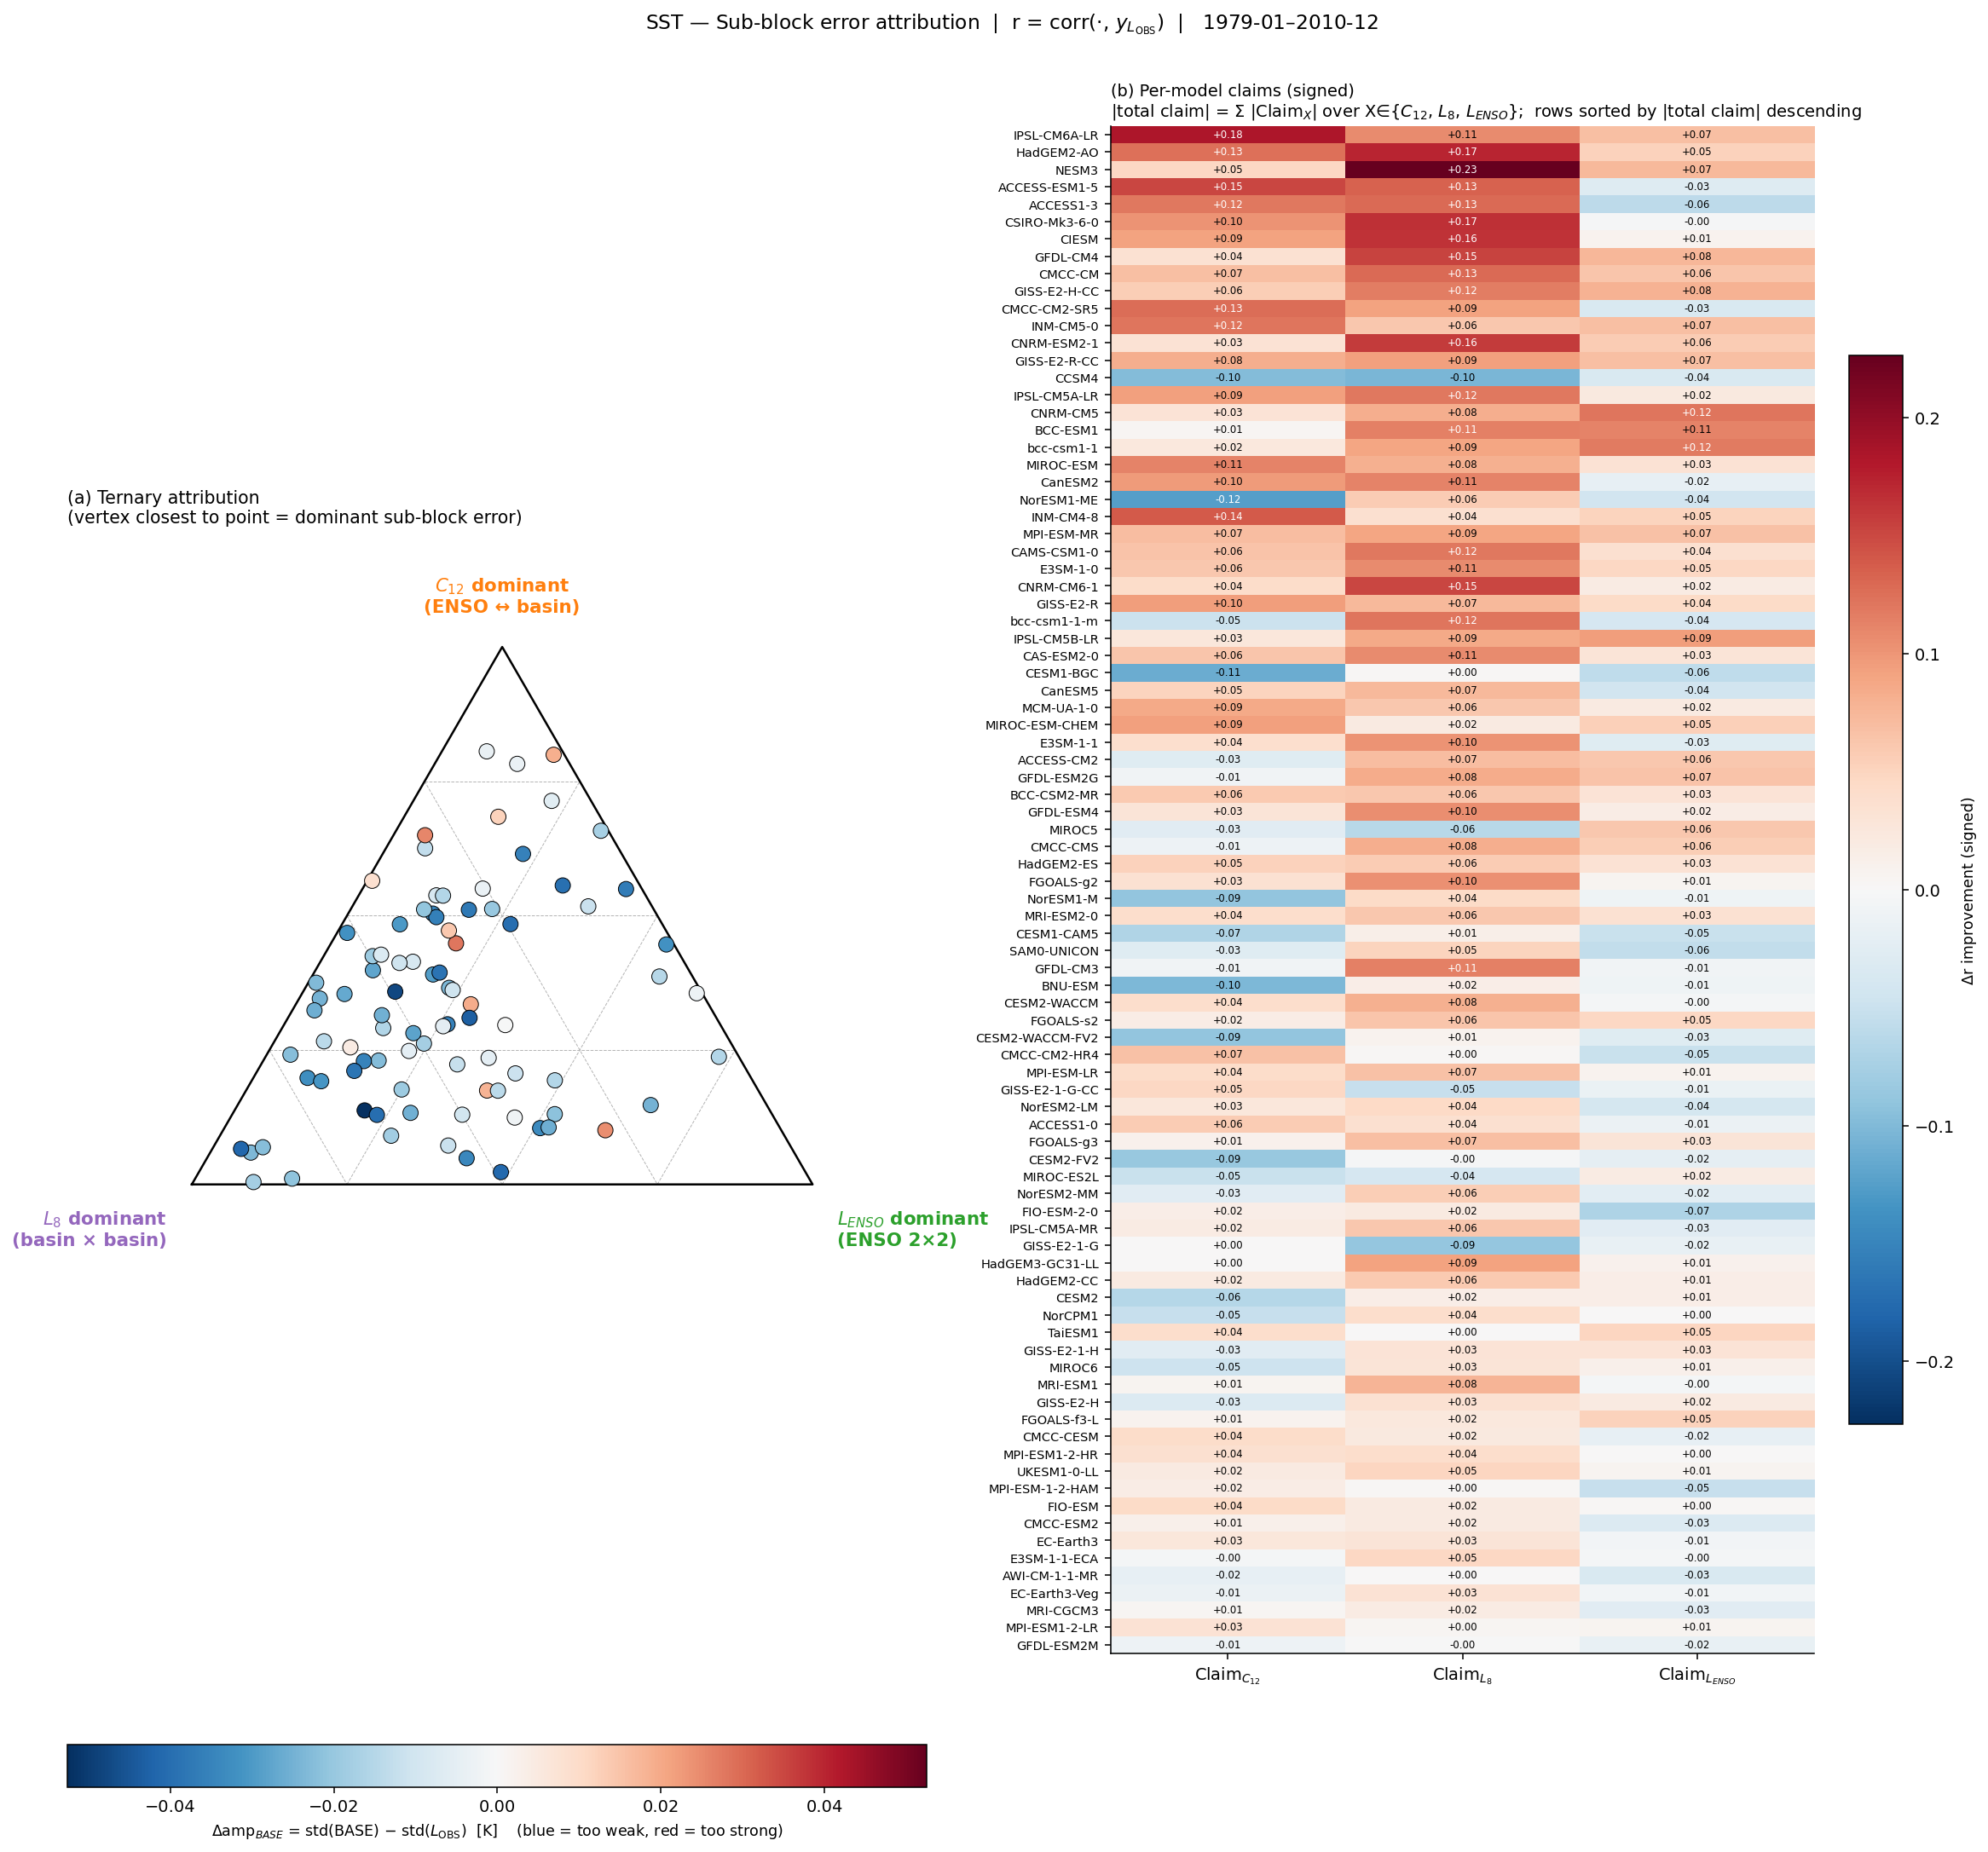

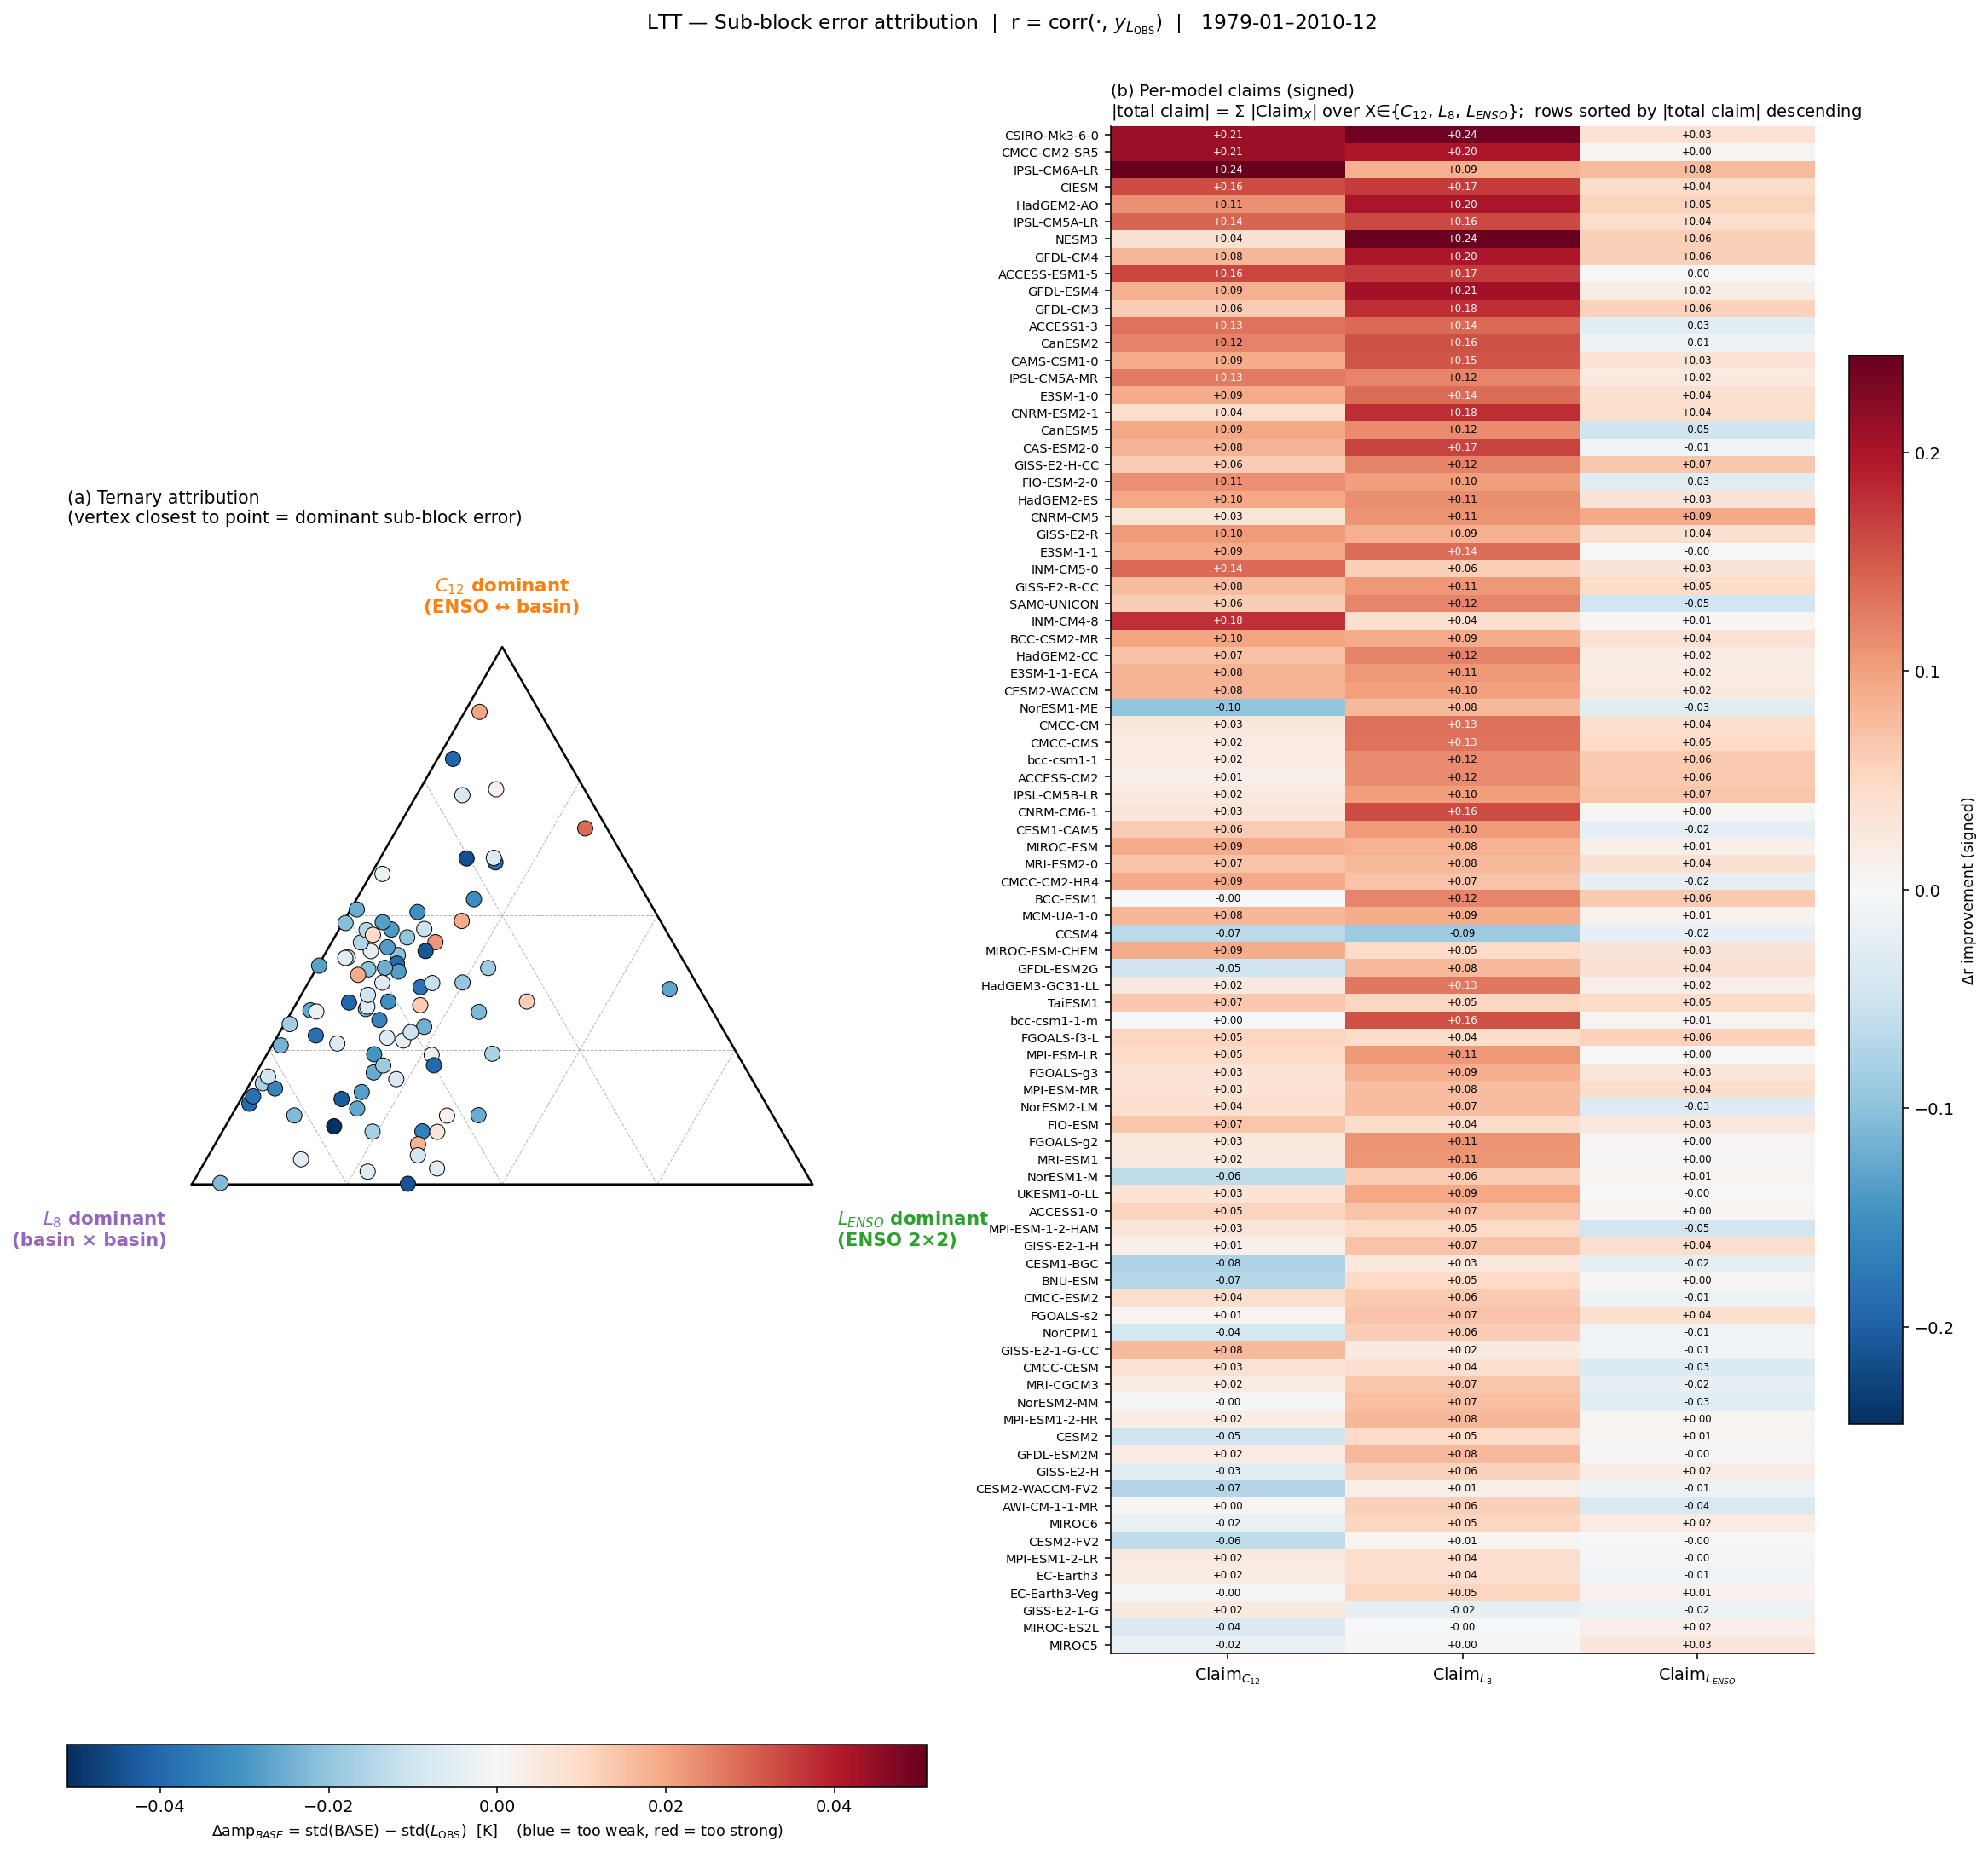

In [15]:
# ============================================================
# Fig S & T — Sub-block error attribution (SST and LTT)
# ============================================================
def compute_subblock_claims(kind):
    base_recs   = {r["model"]: r for r in per_model_series if r["exp"] == "BASE"}
    c12_recs    = {r["model"]: r for r in per_model_series if r["exp"] == "C12_ALL"}
    l8_recs     = {r["model"]: r for r in per_model_series if r["exp"] == "L8_ALL"}
    lenso_recs  = {r["model"]: r for r in per_model_series if r["exp"] == "L_ENSO"}
    obsl_recs   = {r["model"]: r for r in per_model_series if r["exp"] == "OBS_L"}
    common = sorted(set(base_recs) & set(c12_recs) & set(l8_recs)
                    & set(lenso_recs) & set(obsl_recs))

    obsl0 = obsl_recs[common[0]]
    key = "y_sst" if kind == "sst" else "y_ltt"
    y_obsl = obsl0[key].sel(time=EVAL_WIN)
    obsl_amp_v = float(y_obsl.std("time").values)

    def r_with_obsl(rec):
        y = rec[key].sel(time=EVAL_WIN)
        a, b = xr.align(y, y_obsl, join="inner")
        ok = np.isfinite(a.values) & np.isfinite(b.values)
        return float(np.corrcoef(a.values[ok], b.values[ok])[0,1]) if ok.sum() >= 12 else np.nan

    def amp_of(rec):
        return float(rec[key].sel(time=EVAL_WIN).std("time").values)

    rows = []
    for m in common:
        r_base  = r_with_obsl(base_recs[m])
        r_c12   = r_with_obsl(c12_recs[m])
        r_l8    = r_with_obsl(l8_recs[m])
        r_lenso = r_with_obsl(lenso_recs[m])
        rows.append(dict(
            model=m,
            r_base=r_base, r_c12=r_c12, r_l8=r_l8, r_lenso=r_lenso,
            d_amp_base_vs_obsl = amp_of(base_recs[m]) - obsl_amp_v,
            Claim_C12  = r_c12   - r_base,
            Claim_L8   = r_l8    - r_base,
            Claim_LENSO= r_lenso - r_base,
        ))
    df = pd.DataFrame(rows)
    abs_claims = df[["Claim_C12", "Claim_L8", "Claim_LENSO"]].abs().to_numpy()
    df["total_abs"] = abs_claims.sum(axis=1)
    df = df.sort_values("total_abs", ascending=False).reset_index(drop=True)
    return df

def plot_subblock_attribution(kind, fig_label):
    df = compute_subblock_claims(kind)
    n = len(df)

    claims = df[["Claim_C12", "Claim_L8", "Claim_LENSO"]].to_numpy()
    abs_claims = np.abs(claims)
    sums_abs = abs_claims.sum(axis=1)
    sums_abs[sums_abs < 1e-9] = 1e-9
    ratios = abs_claims / sums_abs[:, None]

    a_vals, b_vals, c_vals = ratios[:, 0], ratios[:, 1], ratios[:, 2]
    xT = c_vals + 0.5 * a_vals
    yT = a_vals * np.sqrt(3) / 2

    fig = plt.figure(figsize=(18, 16))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.0], wspace=0.20)
    fig.suptitle(
        f"{kind.upper()} — Sub-block error attribution  |  "
        + r"r = corr($\cdot$, $y_{L_\mathrm{OBS}}$)  |  "
        + f" {EVAL_WIN.start[:7]}–{EVAL_WIN.stop[:7]} ",
        y=0.99, fontsize=12)

    # ── (a) Ternary plot ──
    ax = fig.add_subplot(gs[0, 0])
    tri_x = [0, 1, 0.5, 0]; tri_y = [0, 0, np.sqrt(3)/2, 0]
    ax.plot(tri_x, tri_y, "k-", lw=1.3)

    for g in [0.25, 0.5, 0.75]:
        a_g = g
        x1 = 0.5 * a_g; y1 = a_g * np.sqrt(3)/2
        x2 = 1 - 0.5 * a_g; y2 = a_g * np.sqrt(3)/2
        ax.plot([x1, x2], [y1, y2], color="0.7", lw=0.5, ls="--", zorder=0)
        b_g = g
        x1 = 0.5 * (1 - b_g); y1 = (1 - b_g) * np.sqrt(3)/2
        x2 = 1 - b_g;       y2 = 0
        ax.plot([x1, x2], [y1, y2], color="0.7", lw=0.5, ls="--", zorder=0)
        c_g = g
        x1 = c_g;             y1 = 0
        x2 = c_g + 0.5*(1 - c_g); y2 = (1 - c_g) * np.sqrt(3)/2
        ax.plot([x1, x2], [y1, y2], color="0.7", lw=0.5, ls="--", zorder=0)

    ax.text(0.5, np.sqrt(3)/2 + 0.05, "$C_{12}$ dominant\n(ENSO ↔ basin)",
            ha="center", va="bottom", fontsize=11, fontweight="bold", color="tab:orange")
    ax.text(-0.04, -0.04, "$L_8$ dominant\n(basin × basin)",
            ha="right", va="top", fontsize=11, fontweight="bold", color="tab:purple")
    ax.text(1.04, -0.04, "$L_{ENSO}$ dominant\n(ENSO 2×2)",
            ha="left", va="top", fontsize=11, fontweight="bold", color="tab:green")

    damp_vs_obsl = df["d_amp_base_vs_obsl"].to_numpy()
    vmax_amp = max(np.abs(damp_vs_obsl).max(), 0.01)
    sc = ax.scatter(xT, yT, c=damp_vs_obsl, cmap="RdBu_r",
                    vmin=-vmax_amp, vmax=vmax_amp,
                    s=85, edgecolor="k", linewidth=0.5, zorder=4)

    # Colorbar at BOTTOM (horizontal)
    cax = fig.add_axes([0.06, 0.06, 0.40, 0.022])
    cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
    cbar.set_label(r"Δamp$_{BASE}$ = std(BASE) − std($L_\mathrm{OBS}$)  [K]"
                   "    (blue = too weak, red = too strong)", fontsize=9)

    ax.set_xlim(-0.20, 1.20)
    ax.set_ylim(-0.10, 1.05)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title("(a) Ternary attribution\n(vertex closest to point = dominant sub-block error)",
                 loc="left", fontsize=10.5)

    # ── (b) Heatmap — no row numbers ──
    ax2 = fig.add_subplot(gs[0, 1])
    matrix = df[["Claim_C12", "Claim_L8", "Claim_LENSO"]].to_numpy()
    vmax_h = max(np.abs(matrix).max(), 0.01)
    im = ax2.imshow(matrix, cmap="RdBu_r", vmin=-vmax_h, vmax=vmax_h, aspect="auto")
    ax2.set_xticks([0, 1, 2])
    ax2.set_xticklabels([r"Claim$_{C_{12}}$", r"Claim$_{L_8}$", r"Claim$_{L_{ENSO}}$"], fontsize=10)
    ax2.set_yticks(np.arange(n))
    ax2.set_yticklabels([m.split(chr(95))[-1][:22] for m in df["model"]],
                        fontsize=7.5)
    ax2.set_title(
        "(b) Per-model claims (signed)\n"
        "|total claim| = Σ |Claim$_X$| over X∈{$C_{12}$, $L_8$, $L_{ENSO}$};  "
        "rows sorted by |total claim| descending",
        loc="left", fontsize=10)

    for i in range(n):
        for j in range(3):
            v = matrix[i, j]
            tcolor = "white" if abs(v) > 0.5*vmax_h else "black"
            ax2.text(j, i, f"{v:+.2f}", ha="center", va="center",
                     fontsize=6, color=tcolor)

    cbar2 = plt.colorbar(im, ax=ax2, shrink=0.7, pad=0.04)
    cbar2.set_label("Δr improvement (signed)", fontsize=9)

    plt.subplots_adjust(left=0.06, right=0.95, top=0.93, bottom=0.13, wspace=0.20)
    plt.savefig(os.path.join(FIG_DIR, f"{fig_label}_attribution_{kind}.png"),
                dpi=150, bbox_inches="tight")
    plt.show()
    return df

df_sst_attr = plot_subblock_attribution("sst", "FigS")
df_ltt_attr = plot_subblock_attribution("ltt", "FigT")

## 12. Figure 9 — Total claim vs BASE error (SST + LTT)

One figure with 1×2 layout summarizing per-model error structure:
- X = `|total claim|` = Σ |Claim_X| over X ∈ {C12, L8, L_ENSO}
- Y = `1 − r(BASE, y_OBS_L)` (BASE dynamics fidelity vs OBS_L)
- Color = `|Δamp_BASE|` vs OBS_L

Each point is one model, **numbered 1–88** (alphabetical order). The bottom legend
maps number → model name and is shared across both panels (SST left, LTT right).

Threshold lines at sample medians partition the plane into 4 quadrants:
- bottom-left: genuinely good (low total claim + low BASE error)
- bottom-right: lucky-but-fixable (single sub-block fix would help)
- top-left: stubbornly bad (single fixes don't help)
- top-right: consistently fixable


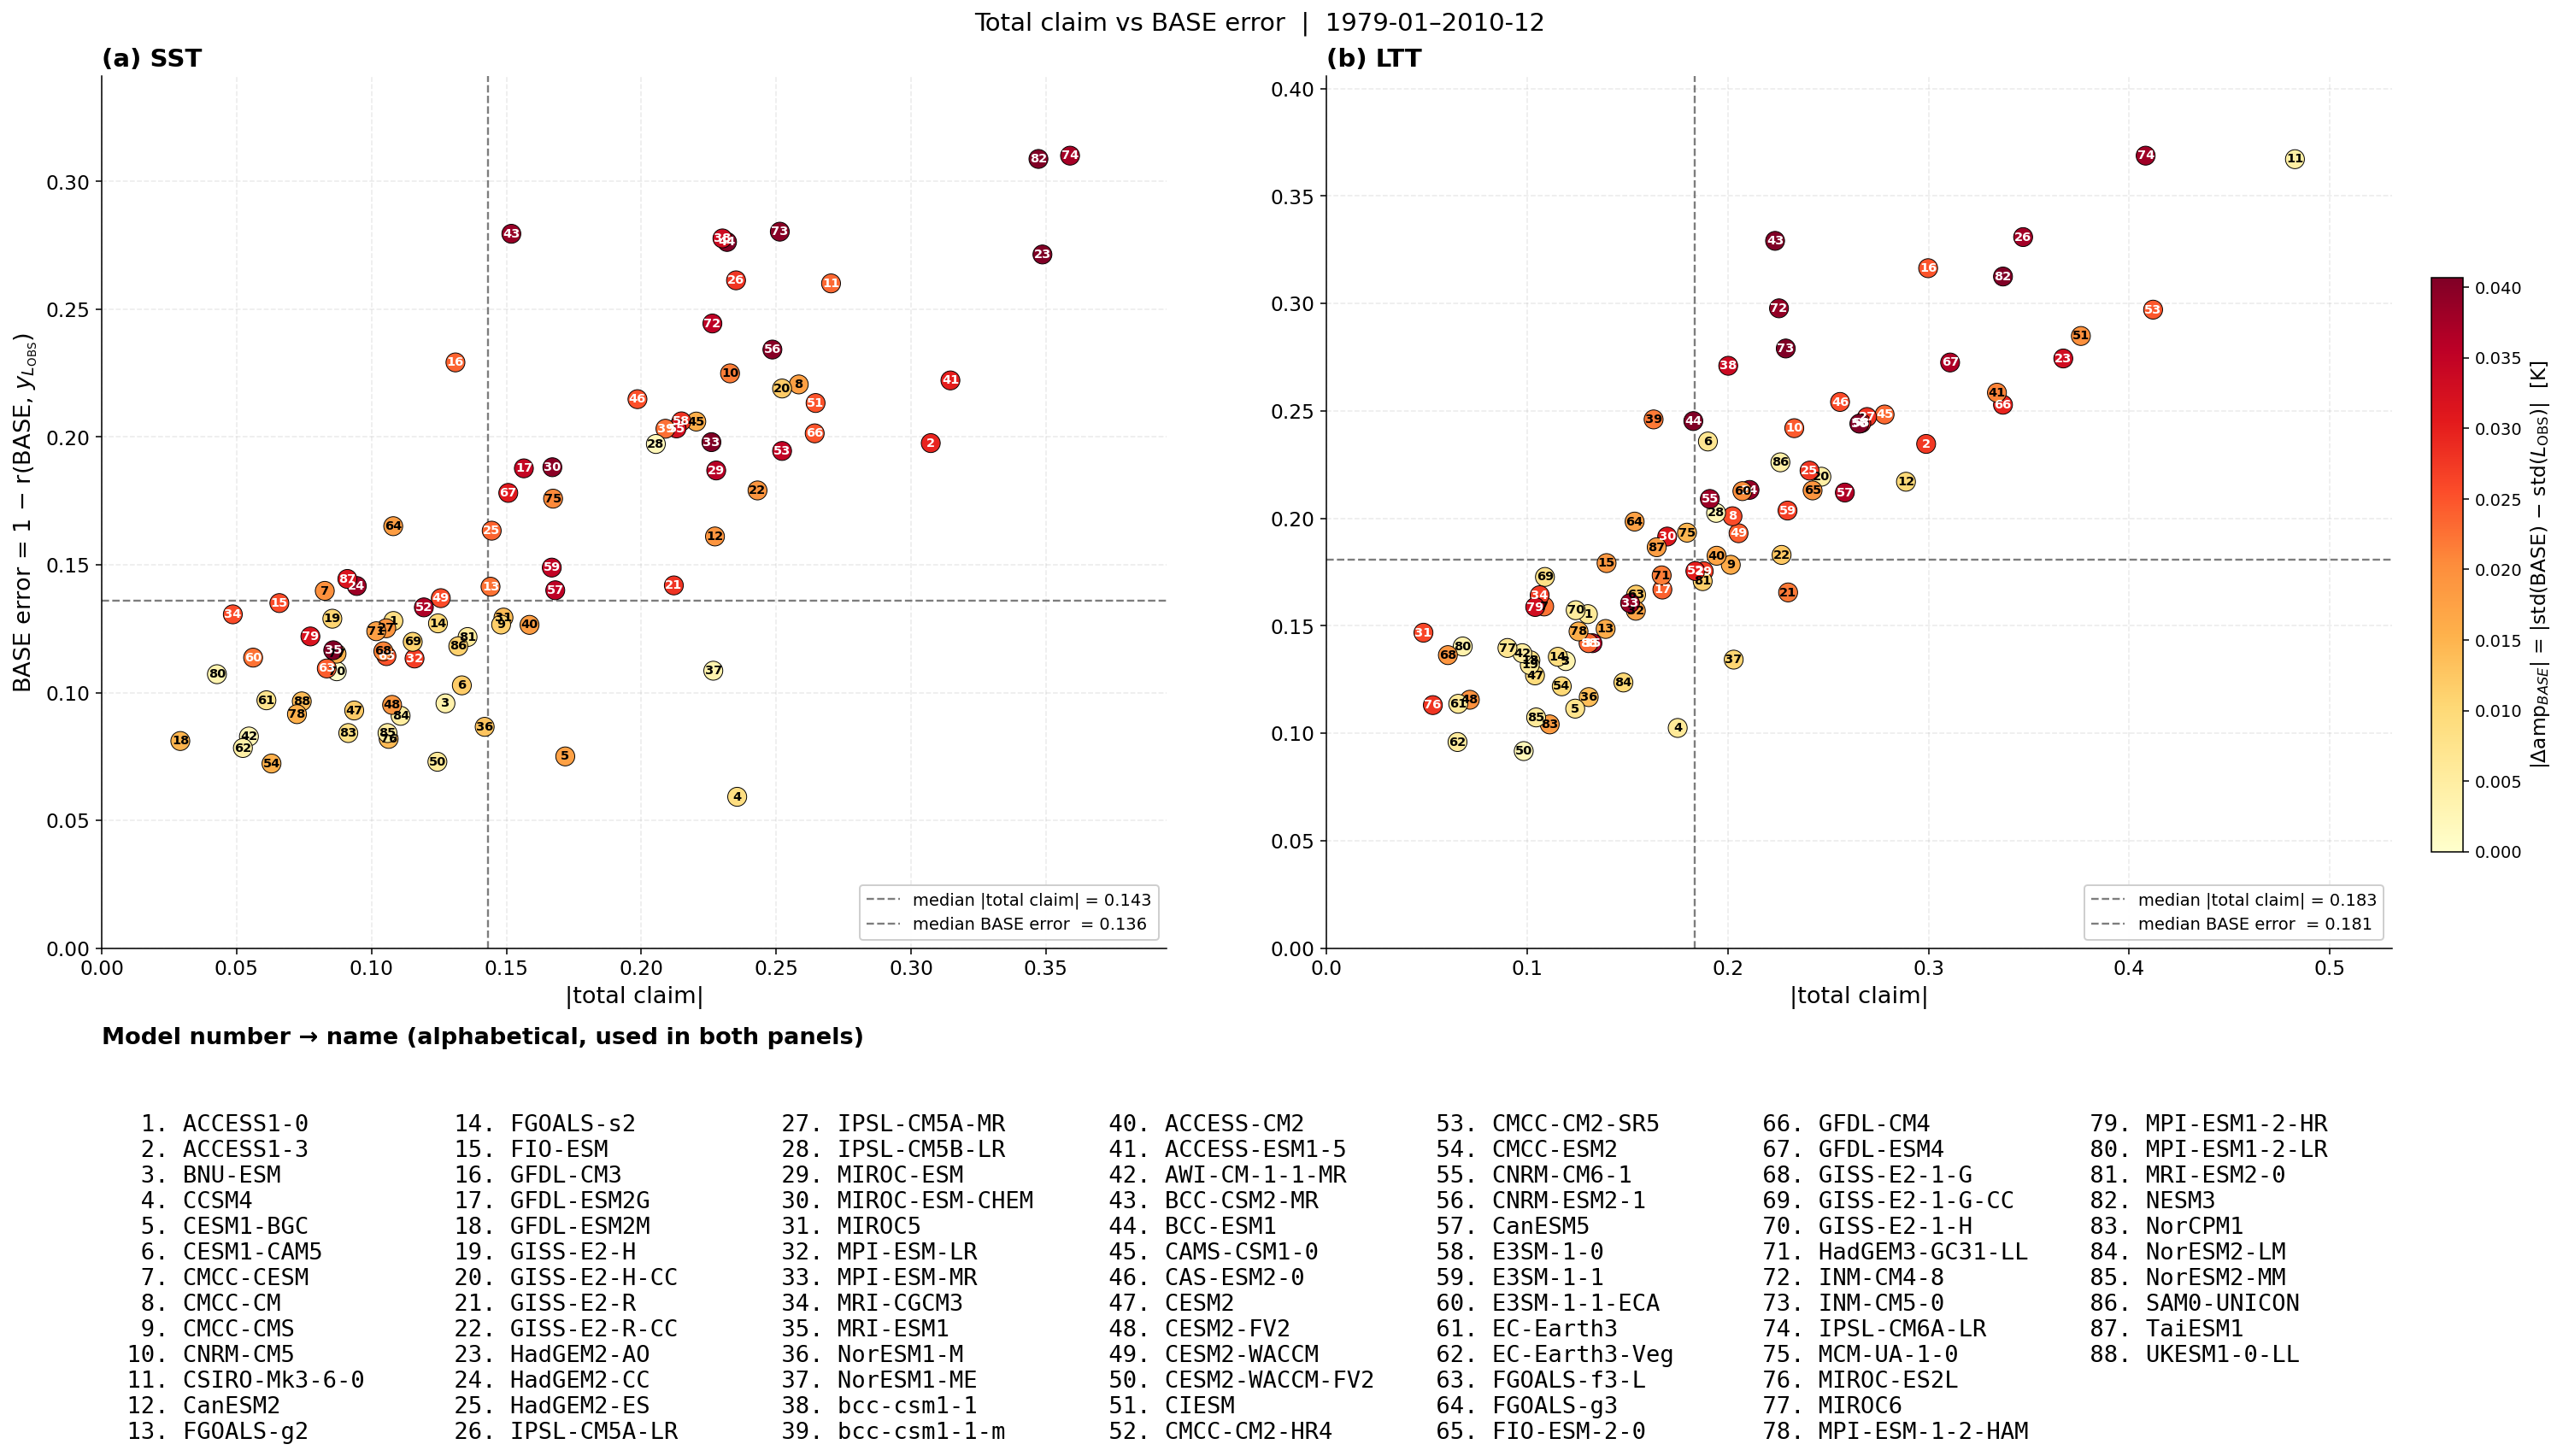


=== Quadrant summary ===

  SST:
    bottom-left  (small claim + small err):  38
    bottom-right (large claim + small err):   6
    top-left     (small claim + large err):   6
    top-right    (large claim + large err):  38

  LTT:
    bottom-left  (small claim + small err):  38
    bottom-right (large claim + small err):   6
    top-left     (small claim + large err):   6
    top-right    (large claim + large err):  38


In [16]:
# ============================================================
# Fig U — Total claim vs BASE error (combined SST+LTT)
# ============================================================
def plot_total_claim_combined(df_sst, df_ltt, fig_label="FigU"):
    # Alphabetical ordering across 87 models for consistent numbering
    all_models = sorted(set(df_sst["model"]) | set(df_ltt["model"]))
    short_names = [m.split(chr(95))[-1] for m in all_models]
    model_to_num = {m: i + 1 for i, m in enumerate(all_models)}

    fig = plt.figure(figsize=(22, 12))
    gs = fig.add_gridspec(2, 2, height_ratios=[3.0, 1.05], hspace=0.22, wspace=0.15)
    fig.suptitle(
        f"Total claim vs BASE error  |  "
        f"{EVAL_WIN.start[:7]}–{EVAL_WIN.stop[:7]}",
        y=0.985, fontsize=15)

    panel_specs = [(0, df_sst, "SST", "a"), (1, df_ltt, "LTT", "b")]
    sc_handle = None

    for col_i, df, kind_label, letter in panel_specs:
        ax = fig.add_subplot(gs[0, col_i])
        n = len(df)
        abs_claims = df[["Claim_C12", "Claim_L8", "Claim_LENSO"]].abs().to_numpy()
        total_claim = abs_claims.sum(axis=1)
        base_err = 1.0 - df["r_base"].to_numpy()
        abs_damp_obsl = np.abs(df["d_amp_base_vs_obsl"].to_numpy())

        vmax_amp = max(np.nanpercentile(abs_damp_obsl, 95), 0.005)
        sc = ax.scatter(total_claim, base_err, c=abs_damp_obsl, cmap="YlOrRd",
                        vmin=0, vmax=vmax_amp,
                        s=130, edgecolor="k", linewidth=0.5, zorder=4)
        if sc_handle is None: sc_handle = sc

        # Number on each point (using alphabetical model_to_num)
        for i in range(n):
            v = abs_damp_obsl[i] / vmax_amp
            tcolor = "white" if v > 0.55 else "black"
            num = model_to_num[df.iloc[i]["model"]]
            ax.text(total_claim[i], base_err[i], f"{num}",
                    ha="center", va="center", fontsize=7.5, color=tcolor,
                    fontweight="bold", zorder=5)

        x_thr = float(np.median(total_claim))
        y_thr = float(np.median(base_err))
        ax.axvline(x_thr, color="0.4", ls="--", lw=1.2, alpha=0.85,
                   label=f"median |total claim| = {x_thr:.3f}")
        ax.axhline(y_thr, color="0.4", ls="--", lw=1.2, alpha=0.85,
                   label=f"median BASE error  = {y_thr:.3f}")

        ax.set_xlim(0, total_claim.max() * 1.10)
        ax.set_ylim(0, base_err.max() * 1.10)

        ax.set_xlabel("|total claim|", fontsize=14)
        if col_i == 0:
            ax.set_ylabel(r"BASE error = 1 − r(BASE, $y_{L_\mathrm{OBS}}$)", fontsize=14)
        ax.set_title(f"({letter}) {kind_label}", loc="left", fontsize=15, fontweight="bold")
        ax.tick_params(axis="both", labelsize=12)
        ax.grid(ls="--", alpha=0.25)
        ax.legend(loc="lower right", fontsize=10, frameon=True, framealpha=0.95)

    # Shared colorbar at right side
    cax = fig.add_axes([0.945, 0.40, 0.012, 0.40])
    cbar = fig.colorbar(sc_handle, cax=cax, orientation="vertical")
    cbar.set_label(r"|Δamp$_{BASE}$| = |std(BASE) − std($L_\mathrm{OBS}$)|  [K]", fontsize=12)

    # ── Shared legend at bottom: number → name mapping ──
    ax_leg = fig.add_subplot(gs[1, :])
    ax_leg.axis("off")
    ax_leg.set_title("Model number → name (alphabetical, used in both panels)",
                     loc="left", fontsize=14, fontweight="bold", pad=20)

    n_cols = 7  # reduced from 9 → wider per-col cell to prevent long-name overlap
    n_models = len(all_models)
    rows_per_col = int(np.ceil(n_models / n_cols))

    # Build text grid (column-major fill)
    cell_w = 1.0 / n_cols
    for col_j in range(n_cols):
        col_text_lines = []
        for row_k in range(rows_per_col):
            idx = col_j * rows_per_col + row_k
            if idx >= n_models: break
            nm = short_names[idx][:18]
            col_text_lines.append(f"{idx+1:>3}. {nm}")
        col_text = "\n".join(col_text_lines)
        x_pos = col_j * cell_w + 0.005   # left-align with small padding from cell left edge
        ax_leg.text(x_pos, 0.88, col_text, ha="left", va="top",
                    fontsize=14, family="monospace",
                    transform=ax_leg.transAxes)

    plt.subplots_adjust(left=0.06, right=0.93, top=0.94, bottom=0.030)
    plt.savefig(os.path.join(FIG_DIR, f"{fig_label}_total_claim_combined.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    print(f"\n=== Quadrant summary ===")
    for col_i, df, kind_label, letter in panel_specs:
        abs_claims = df[["Claim_C12", "Claim_L8", "Claim_LENSO"]].abs().to_numpy()
        total_claim = abs_claims.sum(axis=1)
        base_err = 1.0 - df["r_base"].to_numpy()
        x_thr = float(np.median(total_claim))
        y_thr = float(np.median(base_err))
        quad_A = (total_claim < x_thr) & (base_err < y_thr)
        quad_B = (total_claim >= x_thr) & (base_err < y_thr)
        quad_C = (total_claim < x_thr) & (base_err >= y_thr)
        quad_D = (total_claim >= x_thr) & (base_err >= y_thr)
        print(f"\n  {kind_label}:")
        print(f"    bottom-left  (small claim + small err): {int(quad_A.sum()):3d}")
        print(f"    bottom-right (large claim + small err): {int(quad_B.sum()):3d}")
        print(f"    top-left     (small claim + large err): {int(quad_C.sum()):3d}")
        print(f"    top-right    (large claim + large err): {int(quad_D.sum()):3d}")

plot_total_claim_combined(df_sst_attr, df_ltt_attr, "FigU")

## 13. Figure 10 — Real-time forecast of tropical-mean SST and LTT warming (init 2026-04)

Self-contained forecast section (independent of the replay and CMIP engines). Initial conditions come from the real-time **OISST** (SST indices) + **PMEL/TAO** (WWV) pipeline, assembled 1982-01 to 2026-04. The operational XRO configuration with the nonlinear Niño-3.4 closure is trained on 1982–2022 and integrated forward 18 months (deterministic run + 1000-member seasonally modulated red-noise ensemble). The forecast 10-mode state is mapped to tropical-mean (30°S–30°N) SST and LTT via the calendar-month β regression, and the feedback-direction (C1/C2) and basin-resolved decoupling experiments are repeated in forecast mode (draft Fig. 10a–d).

real-time IC: 1982-01 -> 2026-04 n= 532


-- SST: XRO peak 0.430 K @ lead 8; contribution (XRO-variant) --
   $C_1=0$        +0.2511
   $C_2=0$        +0.2253
   $C_1$&$C_2=0$  +0.3246
   $C1_{ExPO}=0$  +0.1897
   $C1_{IO}=0$    +0.0232
   $C1_{AO}=0$    +0.0669
   $C2_{ExPO}=0$  +0.0808
   $C2_{IO}=0$    +0.1162
   $C2_{AO}=0$    +0.0619
-- LTT: XRO peak 0.529 K @ lead 10; contribution (XRO-variant) --
   $C_1=0$        +0.3512
   $C_2=0$        +0.4223
   $C_1$&$C_2=0$  +0.4842
   $C1_{ExPO}=0$  +0.2637
   $C1_{IO}=0$    +0.0414
   $C1_{AO}=0$    +0.0921
   $C2_{ExPO}=0$  +0.0959
   $C2_{IO}=0$    +0.2552
   $C2_{AO}=0$    +0.1615


saved: /Users/po/Library/CloudStorage/GoogleDrive-popccpo@gmail.com/My Drive/03.Projects/20260301_PhD_work/202604.Paper_Submission/Figure/Fig_tropmean_forecast_SST_LTT_contributions.png / .pdf


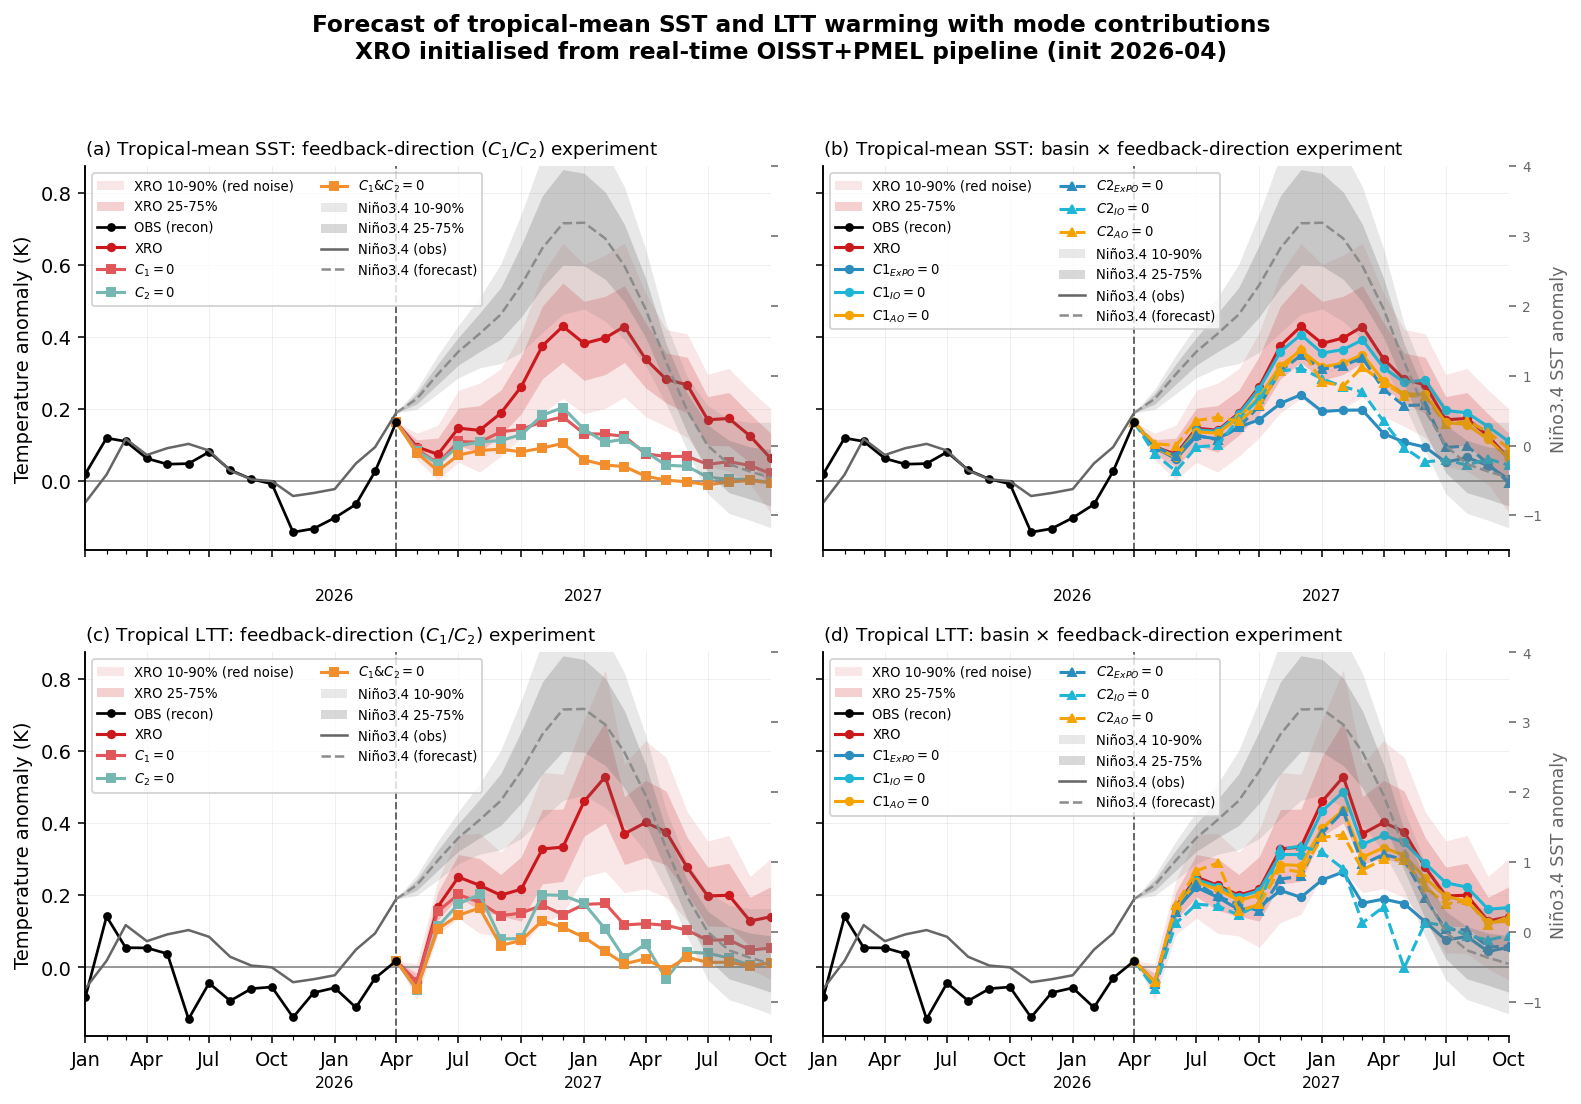

In [17]:
# ============================================================
# CELL FC -- Real-time forecast of tropical-mean SST & LTT warming
#            with mode contributions (init 2026-04)
#
# Self-contained: does NOT depend on CELL A / CELL B globals.
#   - Initial conditions: real-time OISST (SST indices) + PMEL/TAO (WWV),
#     anomaly + linear-detrended, assembled 1982-01 -> 2026-04.
#   - Engine: official operational config XRO(ncycle=12, ac_order=2) with
#     maskb=['IOD'], maskNT=['T2','TH'] (nonlinear recharge oscillator),
#     trained 1982-2022, reforecast 18 months from 2026-04. Same engine as
#     XRO_official_reproduce_2026.ipynb, so the Nino3.4 forecast matches the
#     operational plume. Contribution blocks are zeroed in the linear Lac
#     operator; the nonlinear T^2 / T*H ENSO terms remain in all variants.
#   - Tropical-mean (30S-30N) mapping: monthly beta regression of the 9-mode
#     state (Nino34 + 8 non-ENSO modes, z-scored) onto ERA5 tropical-mean
#     SST / LTT, fitted in-sample (recon-vs-OBS r ~ 0.86 SST, 0.84 LTT).
#   - Contributions diagnosed two ways:
#       (left)  per-basin counterfactual forecasts -- zero each basin's
#               coupling into the Nino3.4 tendency row only (operational
#               XRO "quantify" convention).
#       (right) feedback-direction blocks over all 8 extra-basin modes:
#               C1=0 (modes->ENSO), C2=0 (ENSO->modes), C1&C2=0.
#   - 1000-member red-noise spread (10-90%) on the full XRO forecast.
#
# Required files in DATA_DIR:
#   realtime_oisst_sst_indices.nc, realtime_tao_pmel_wwv.nc,
#   ERA5_tropical_mean_sst_anom_detr_1950-2025.nc,
#   ERA5_LTT_1000-850_detr_tropmean_1979-2025.nc
# ============================================================
import numpy as np, xarray as xr, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from XRO import XRO

INIT, NLEAD, NMEM = "2026-04", 18, 1000
TRAIN = slice("1982-01", "2022-12")
STATE10 = ["Nino34","WWV","NPMM","SPMM","IOB","IOD","SIOD","TNA","ATL3","SASD"]
MODES9  = ["Nino34","NPMM","SPMM","IOB","IOD","SIOD","TNA","ATL3","SASD"]   # no WWV
COL   = {v: i for i, v in enumerate(STATE10)}
BASIN = {"ExPO": ["NPMM","SPMM"], "IO": ["IOB","IOD","SIOD"], "AO": ["TNA","ATL3","SASD"]}
ALL8  = BASIN["ExPO"] + BASIN["IO"] + BASIN["AO"]
ENSO_ROWS = [COL["Nino34"], COL["WWV"]]
SUB = [COL[m] for m in ALL8]

def _mz(da):
    da = da.assign_coords(time=da.time.values.astype("datetime64[M]").astype("datetime64[ns]"))
    if "month" in da.coords:
        da = da.drop_vars("month")
    return da

# ---- real-time initial conditions (OISST + PMEL/TAO) ----
_o = _mz(xr.open_dataset(os.path.join(DATA_DIR, "realtime_oisst_sst_indices.nc")))
_w = _mz(xr.open_dataset(os.path.join(DATA_DIR, "realtime_tao_pmel_wwv.nc"))["WWV"])
ds_fc = xr.Dataset({"Nino34": _o["Nino34"], "WWV": _w})
for v in STATE10[2:]:
    ds_fc[v] = _o[v]
ds_fc = ds_fc[STATE10].sel(time=slice("1982-01", INIT)).dropna("time")
print("real-time IC:", str(ds_fc.time.values[0])[:7], "->", str(ds_fc.time.values[-1])[:7],
      "n=", ds_fc.sizes["time"])

# ---- tropical-mean OBS targets ----
_ys = xr.open_dataset(os.path.join(DATA_DIR, "ERA5_tropical_mean_sst_anom_detr_1950-2025.nc"))
y_sst = _mz(_ys[list(_ys.data_vars)[0]].rename("SST"))
_yl = xr.open_dataset(os.path.join(DATA_DIR, "ERA5_LTT_1000-850_detr_tropmean_1979-2025.nc"))
y_ltt = _mz(_yl[list(_yl.data_vars)[0]].rename("LTT"))

# ---- monthly beta mapping (z-scored 9-mode state -> tropical mean) ----
_Z  = ds_fc[MODES9].to_array("mode").transpose("time", "mode")
_MU  = _Z.groupby("time.month").mean("time")
_SIG = _Z.groupby("time.month").std("time")

def _zscore(vals, months):
    mu  = _MU.sel(month=xr.DataArray(months, dims="t")).values.T
    sig = _SIG.sel(month=xr.DataArray(months, dims="t")).values.T
    if vals.ndim == 3:
        out = (vals - mu[:, :, None]) / sig[:, :, None]
    else:
        out = (vals - mu) / sig
    return np.where(np.isfinite(out), out, 0.0)

def _fit_beta(y):
    Zz = ((_Z - _MU.sel(month=_Z["time.month"]).transpose("time","mode")) /
          _SIG.sel(month=_Z["time.month"]).transpose("time","mode")).where(np.isfinite(_Z), 0.0)
    Zz, yy = xr.align(Zz, y, join="inner")
    ti = pd.DatetimeIndex(Zz.time.values)
    beta = np.full((len(MODES9), 12), np.nan)
    for mm in range(1, 13):
        sel = ti.month == mm
        Zm, ym = Zz.values[sel], yy.values[sel].astype(float)
        ok = np.isfinite(ym) & np.all(np.isfinite(Zm), axis=1)
        if ok.sum() >= 12:
            beta[:, mm-1], *_ = np.linalg.lstsq(Zm[ok], ym[ok], rcond=None)
    return beta

BETA = {"SST": _fit_beta(y_sst), "LTT": _fit_beta(y_ltt)}

def _to_trop(state, months, var):
    z = _zscore(state, months)
    b = BETA[var][:, months-1]
    return np.einsum("ml,mlk->lk", b, z) if z.ndim == 3 else np.einsum("ml,ml->l", b, z)

# ---- XRO fit + counterfactual fits (official operational config) ----
_model = XRO(ncycle=12, ac_order=2)
_fit = _model.fit_matrix(ds_fc.sel(time=TRAIN), var_names=STATE10,
                         maskb=["IOD"], maskNT=["T2", "TH"])

def _patch(rows, cols):
    f = _fit.copy(deep=True); L = f["Lac"].values.copy()
    for r in rows:
        for c in cols:
            L[r, c, :] = 0.0
    f["Lac"] = (f["Lac"].dims, L); return f

# feedback-direction blocks over all 8 extra-basin modes
_fitC1  = _patch(ENSO_ROWS, SUB)                 # C1: modes -> ENSO
_fitC2  = _patch(SUB, ENSO_ROWS)                 # C2: ENSO -> modes
_fitC12 = _fit.copy(deep=True); _L = _fitC12["Lac"].values.copy()
for r in ENSO_ROWS:
    for c in SUB: _L[r, c, :] = 0.0
for r in SUB:
    for c in ENSO_ROWS: _L[r, c, :] = 0.0
_fitC12["Lac"] = (_fitC12["Lac"].dims, _L)

# basin-split feedback-direction blocks (only this basin's modes coupled)
def _c1_basin(b): return _patch(ENSO_ROWS, [COL[m] for m in BASIN[b]])   # basin modes -> ENSO
def _c2_basin(b): return _patch([COL[m] for m in BASIN[b]], ENSO_ROWS)   # ENSO -> basin modes

# ---- forecast leads + calendar months ----
ftime  = np.array([np.datetime64(INIT, "M") + np.timedelta64(L, "M") for L in range(NLEAD+1)])
fmonth = pd.DatetimeIndex(ftime.astype("datetime64[D]")).month.values

def _fc_state(fit_ds, ncopy=1, noise="zero", seed=0):
    fc = _model.reforecast(fit_ds=fit_ds, init_ds=ds_fc, n_month=NLEAD,
                           ncopy=ncopy, noise_type=noise, seed=seed)
    arrs = []
    for m in MODES9:
        a = fc[m].sel(init=INIT).squeeze()
        order = ["member","lead"] if "member" in a.dims else ["lead"]
        arrs.append(a.transpose(*order).values)
    st = np.stack(arrs, axis=0)
    if st.ndim == 3:
        st = np.transpose(st, (0, 2, 1))   # (mode,lead,member)
    return st

def _curves(fit_ds):
    st = _fc_state(fit_ds)
    return {v: _to_trop(st, fmonth, v) for v in ("SST","LTT")}

# (label, fit, color, marker, linestyle)
BCOL = {"ExPO": "#2b8cbe", "IO": "#1fb6d6", "AO": "#f5a300"}
CURVE_CC = [("XRO", _fit, "#cb181d", "o", "-"),
            (r"$C_1=0$",       _fitC1,  "#e15759", "s", "-"),
            (r"$C_2=0$",       _fitC2,  "#76b7b2", "s", "-"),
            (r"$C_1$&$C_2=0$", _fitC12, "#f28e2b", "s", "-")]
CURVE_BD = [("XRO", _fit, "#cb181d", "o", "-")]
for b in ("ExPO", "IO", "AO"):
    CURVE_BD.append((rf"$C1_{{{b}}}=0$", _c1_basin(b), BCOL[b], "o", "-"))
for b in ("ExPO", "IO", "AO"):
    CURVE_BD.append((rf"$C2_{{{b}}}=0$", _c2_basin(b), BCOL[b], "^", "--"))
mean_cc = {lab: _curves(fd) for lab, fd, *_ in CURVE_CC}
mean_bd = {lab: _curves(fd) for lab, fd, *_ in CURVE_BD}

# 1000-member red-noise spread on the full XRO forecast (10-90 and 25-75)
_st_ens = _fc_state(_fit, ncopy=NMEM, noise="red", seed=42)
band = {}
for v in ("SST","LTT"):
    ens = _to_trop(_st_ens, fmonth, v)
    band[v] = {"1090": (np.percentile(ens, 10, axis=1), np.percentile(ens, 90, axis=1)),
               "2575": (np.percentile(ens, 25, axis=1), np.percentile(ens, 75, axis=1))}
# Nino3.4 ensemble spread (row 0 of the mode state, physical units)
_nino_ens = _st_ens[0]                                  # (lead, member)
nino_band = {"1090": (np.percentile(_nino_ens, 10, axis=1), np.percentile(_nino_ens, 90, axis=1)),
             "2575": (np.percentile(_nino_ens, 25, axis=1), np.percentile(_nino_ens, 75, axis=1))}

# observed tail (reconstructed from real-time modes via the same beta)
_dst = ds_fc.sel(time=slice("2025-01", INIT))
otime = _dst.time.values.astype("datetime64[D]")
_tmon = pd.DatetimeIndex(_dst.time.values).month.values
_stt  = _dst[MODES9].to_array("mode").transpose("mode","time").values
obs_recon = {v: _to_trop(_stt, _tmon, v) for v in ("SST","LTT")}

# Nino3.4: ENSO driver shown as grey dashed reference (full XRO forecast + obs tail)
nino_fc  = _fc_state(_fit)[0]                       # row 0 of MODES9 = Nino34, (lead+1,)
nino_obs = _dst["Nino34"].values

for v in ("SST","LTT"):
    xro = mean_cc["XRO"][v]; kpk = int(np.nanargmax(xro))
    print(f"-- {v}: XRO peak {xro[kpk]:.3f} K @ lead {kpk}; contribution (XRO-variant) --")
    for lab, *_ in CURVE_CC[1:]:
        print(f"   {lab:14s} {xro[kpk]-mean_cc[lab][v][kpk]:+.4f}")
    for lab, *_ in CURVE_BD[1:]:
        print(f"   {lab:14s} {xro[kpk]-mean_bd[lab][v][kpk]:+.4f}")

# ---------------- figure ----------------
fig, axes = plt.subplots(2, 2, figsize=(11.4, 8.0), sharex=True, sharey=True)
ftime_d = ftime.astype("datetime64[D]")
VAR_NAME = {"SST": "Tropical-mean SST", "LTT": "Tropical LTT"}
EXP_NAME = {0: r"feedback-direction ($C_1$/$C_2$) experiment",
            1: r"basin $\times$ feedback-direction experiment"}
PANEL_LBL = [["a", "b"], ["c", "d"]]
ROWS   = [("SST", None), ("LTT", None)]
PANELS = [(CURVE_CC, mean_cc), (CURVE_BD, mean_bd)]
t0 = ftime_d[0]
NINO_YL = (-1.5, 4.0)
for i, (v, _) in enumerate(ROWS):
    for j, (CURVES, MEANS) in enumerate(PANELS):
        ax = axes[i, j]
        ax.axhline(0, color="0.5", lw=0.8)
        ax.axvline(t0, color="0.4", lw=1.0, ls="--")
        lo90, hi90 = band[v]["1090"]; lo75, hi75 = band[v]["2575"]
        ax.fill_between(ftime_d, lo90, hi90, color="#cb181d",
                        alpha=0.10, lw=0, zorder=1, label="XRO 10-90% (red noise)")
        ax.fill_between(ftime_d, lo75, hi75, color="#cb181d",
                        alpha=0.20, lw=0, zorder=1, label="XRO 25-75%")
        ax.plot(otime, obs_recon[v], "-o", color="k", ms=3.5, lw=1.4,
                label="OBS (recon)", zorder=6)
        for lab, fd, col, mk, ls in CURVES:
            ax.plot(ftime_d, MEANS[lab][v], marker=mk, ls=ls,
                    color=col, ms=3.8, lw=1.6, label=lab, zorder=5)
        # Nino3.4 ENSO driver on secondary right axis (fixed scale)
        #   observed (OISST real-time) = solid; XRO forecast = dashed + grey spread
        ax2 = ax.twinx()
        nlo90, nhi90 = nino_band["1090"]; nlo75, nhi75 = nino_band["2575"]
        ax2.fill_between(ftime_d, nlo90, nhi90, color="0.45",
                         alpha=0.16, lw=0, zorder=0, label=u"Niño3.4 10-90%")
        ax2.fill_between(ftime_d, nlo75, nhi75, color="0.45",
                         alpha=0.28, lw=0, zorder=0, label=u"Niño3.4 25-75%")
        ax2.plot(otime, nino_obs, color="0.40", ls="-",  lw=1.3, label=u"Niño3.4 (obs)")
        ax2.plot(ftime_d, nino_fc, color="0.55", ls="--", lw=1.3, label=u"Niño3.4 (forecast)")
        ax2.set_ylim(NINO_YL)
        ax2.tick_params(axis="y", colors="0.4", labelsize=7)
        if j == 1:
            ax2.set_ylabel(u"Niño3.4 SST anomaly", color="0.4", fontsize=9)
        else:
            ax2.set_yticklabels([])
        ax.set_title(f"({PANEL_LBL[i][j]}) {VAR_NAME[v]}: {EXP_NAME[j]}",
                     loc="left", fontsize=9.5)
        if j == 0: ax.set_ylabel(u"Temperature anomaly (K)")
        ax.set_xlim(otime[0], ftime_d[-1])
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        ax.xaxis.set_minor_locator(mdates.MonthLocator())
        ax.grid(alpha=0.2, lw=0.5)
        _h1, _l1 = ax.get_legend_handles_labels()
        _h2, _l2 = ax2.get_legend_handles_labels()
        ax2.legend(_h1 + _h2, _l1 + _l2, ncol=2, loc="upper left",
                   frameon=True, fontsize=6.8)
        for yr in (2026, 2027):
            jan = np.datetime64("%d-01-01" % yr)
            if otime[0] <= jan <= ftime[-1]:
                ax.annotate(str(yr), xy=(jan, 0), xytext=(0, -26), textcoords="offset points",
                            xycoords=("data", "axes fraction"), ha="center", fontsize=8,
                            annotation_clip=False)
fig.suptitle("Forecast of tropical-mean SST and LTT warming with mode contributions\n"
             "XRO initialised from real-time OISST+PMEL pipeline (init 2026-04)",
             fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
# FIG_DIR from the setup cell
_fp = os.path.join(FIG_DIR, "Fig_tropmean_forecast_SST_LTT_contributions")
fig.savefig(_fp + ".png", dpi=300, bbox_inches="tight")
fig.savefig(_fp + ".pdf", bbox_inches="tight")
print("saved:", _fp + ".png / .pdf")
plt.show()
